## 0. Setup

In [1]:
# 0.1  Library versions used for the paper. On Colab they are installed here; elsewhere this cell only prints them.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
PINNED = ["scikit-learn==1.6.1", "lightgbm==4.6.0", "imbalanced-learn==0.14.2", "deap", "pytorch-tabnet==4.1.0"]
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINNED], check=True)
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost==3.4.1"])
    if r.returncode != 0:                      # xgboost 3.4.1 needs Python >= 3.12
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    print("installed:", PINNED + ["xgboost==3.4.1"])
else:
    print("Not on Colab, nothing installed. Versions used for the paper:", PINNED + ["xgboost==3.4.1"])

installed: ['scikit-learn==1.6.1', 'lightgbm==4.6.0', 'imbalanced-learn==0.14.2', 'deap', 'pytorch-tabnet==4.1.0', 'xgboost==3.4.1']


In [2]:
# 0.2  Imports, seed and switches
import os, gc, glob, json, time, random, zipfile, platform, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker
from scipy import stats

import sklearn, xgboost as xgb, lightgbm as lgb, imblearn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE, ADASYN, RandomOverSampler

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

# Switches. Every expensive stage is checkpointed, so leaving them on and re-running only skips finished work.
RUN_UNSW_GRID   = True   # Table 3, tree rows: 3 models x {none, SMOTE, ADASYN} x 5 folds = 45 fits
RUN_NEURAL      = True   # Table 3, neural rows: TabNet and FT-Transformer, no resampling, 5 folds
RUN_UNSW_EXTRAS = True   # de-duplicated control and the two Exploits ablations
RUN_GA_CHECK    = True   # genetic-algorithm feature-selection check
RUN_PROTOCOLS   = True   # 1.20 to 1.22: grouped folds, de-duplicated folds, time-ordered and per-day splits
RUN_TENFOLD     = True   # 1.23: the resampling comparison repeated with ten folds, for the signed-rank test
RUN_XAI         = True   # 1.25, 1.26: SHAP attribution and learning curves
RUN_CICIDS      = True   # Part 2
RUN_MERGED      = True   # Part 3: merged pool and cross-dataset transfer

# Folder (inside NIDS) for results, checkpoints and figures. "results_final" is where the earlier
# pipeline notebook saved its folds, so those are reused. A new name recomputes everything.
RESULTS_SUBDIR = "results_final"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def make_encoder(class_names):
    '''Fit a LabelEncoder and return (encoder, class names in ENCODED order).
    LabelEncoder sorts names alphabetically, so per-class numbers are always reported with this list.'''
    le = LabelEncoder().fit(class_names)
    ordered = [str(c) for c in le.classes_]
    assert all(le.transform([n])[0] == i for i, n in enumerate(ordered)), "encoder order mismatch"
    return le, ordered


def jsonl_rows(path):
    return [json.loads(l) for l in open(path)] if os.path.exists(path) else []


def jsonl_append(path, row):
    with open(path, "a") as f:
        f.write(json.dumps(row) + "\n")


# Every number that appears in the paper is also recorded here and checked in cell 4.3.
LEDGER_VALUES = {}
def record(key, value):
    LEDGER_VALUES[key] = None if value is None else float(value)


def duplicate_audit(Xdf, y, name, verify=200, seed=SEED):
    '''The single duplicate and label-conflict audit used for UNSW-NB15, CICIDS-2017 and the
    merged pool, so all three corpora are measured the same way.

    Returns (counts, keep_mask, row_hash). Nothing is dropped here: keep_mask keeps one record per
    (feature vector, label) pair and the caller decides whether to use it, so both variants -
    duplicates kept and duplicates removed - can be trained and reported.

    Two counts are easy to confuse, so both are printed:
      distinct feature vectors      - how many different feature vectors exist
      distinct (vector, label) pairs - how many survive de-duplication
    They differ by exactly the number of extra labels carried by vectors that appear under more
    than one label, and that identity is asserted below.'''
    h = pd.util.hash_pandas_object(Xdf, index=False).values
    y = np.asarray(y)
    g = pd.DataFrame({"h": h, "y": y})
    keep = ~g.duplicated(subset=["h", "y"], keep="first").values
    n_any = int(g.duplicated(subset=["h", "y"], keep=False).sum())
    nuniq = g.groupby("h")["y"].nunique()
    conflict = nuniq[nuniq > 1]
    in_conf = g["h"].isin(set(conflict.index)).values
    a = dict(name=name, records=int(len(g)), features=int(Xdf.shape[1]),
             distinct_vectors=int(g["h"].nunique()), distinct_vector_label_pairs=int(keep.sum()),
             removed_as_copies=int((~keep).sum()), records_with_a_copy=n_any,
             conflicted_vectors=int(len(conflict)), records_on_conflicted_vectors=int(in_conf.sum()),
             extra_label_variants=int((conflict - 1).sum()))
    assert a["distinct_vector_label_pairs"] - a["distinct_vectors"] == a["extra_label_variants"]

    print(f"=== duplicate and label-conflict audit: {name} ===")
    print(f"records                                          : {a['records']:,}")
    print(f"distinct feature vectors ({a['features']} features)"
          f"{'':<{max(0, 14 - len(str(a['features'])))}}: {a['distinct_vectors']:,}")
    print(f"distinct (feature vector, label) pairs           : {a['distinct_vector_label_pairs']:,}"
          f"   <- what de-duplication keeps")
    print(f"  the gap between those two counts               : {a['extra_label_variants']:,} extra labels "
          f"carried by {a['conflicted_vectors']:,} vectors that appear under more than one label")
    print(f"records with at least one exact copy (features+label): {a['records_with_a_copy']:,} "
          f"({a['records_with_a_copy'] / a['records'] * 100:.2f}%)")
    print(f"records dropped if those copies are removed      : {a['removed_as_copies']:,}")
    print(f"records sitting on a conflicted vector           : {a['records_on_conflicted_vectors']:,} "
          f"({a['records_on_conflicted_vectors'] / a['records'] * 100:.2f}%)")

    if verify and len(conflict):
        rng = np.random.default_rng(seed)
        ids = list(conflict.index)
        ids = [ids[i] for i in rng.choice(len(ids), size=min(verify, len(ids)), replace=False)]
        ok = sum(Xdf.loc[h == i].drop_duplicates().shape[0] == 1 for i in ids)
        print(f"hash check: {ok}/{len(ids)} sampled conflict groups verified identical by exact comparison")
        a["hash_check_ok"], a["hash_check_n"] = int(ok), int(len(ids))
    return a, keep, h


def paired_tests(a, b, metrics, where, comparison, fold_col="fold"):
    '''Paired t-test and exact Wilcoxon signed-rank test on the same fold-level differences.

    The signed-rank test makes no normality assumption, but it is discrete: with n folds the
    smallest two-sided p-value it can return is 2 / 2**n, which is 0.0625 at five folds and 0.002
    at ten. Both tests are therefore always reported together, with the number of folds that moved
    in each direction, which is what the signed-rank statistic actually summarises.'''
    rows = []
    for m in metrics:
        x = a.sort_values(fold_col)[m].values * 100.0
        y = b.sort_values(fold_col)[m].values * 100.0
        d = x - y
        t, pt = stats.ttest_rel(x, y)
        if np.allclose(d, 0):
            w, pw = np.nan, 1.0
        else:
            w, pw = stats.wilcoxon(x, y, zero_method="wilcox", alternative="two-sided", method="exact")
        rows.append(dict(where=where, comparison=comparison, metric=m, folds=int(len(d)),
                         diff_pp=round(float(d.mean()), 3), sd_diff=round(float(d.std(ddof=1)), 3),
                         folds_favouring_first=int((d > 0).sum()), t_stat=round(float(t), 2),
                         p_ttest=round(float(pt), 6), w_stat=float(w), p_wilcoxon=round(float(pw), 6)))
    return pd.DataFrame(rows)


def wilcoxon_floor(n_folds):
    return 2 / 2 ** n_folds


print("imports done | seed", SEED)

imports done | seed 42


In [3]:
# 0.3  Data folder (Google Drive on Colab), results folder and environment report
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    CANDIDATES = ["/content/drive/MyDrive/NIDS", "/content/drive/My Drive/NIDS",
                  "/content/drive/Shareddrives/NIDS", "/content/drive/Shared drives/NIDS"]
    NIDS_DIR = next((p for p in CANDIDATES if os.path.isdir(p)), None)
    if NIDS_DIR is None:
        for root, dirs, _ in os.walk("/content/drive"):
            if root.count(os.sep) > 6:
                dirs[:] = []; continue
            if "NIDS" in dirs:
                NIDS_DIR = os.path.join(root, "NIDS"); break
    WORK = "/content/work"
else:                                         # any other machine: point NIDS_DIR at the data folder
    NIDS_DIR = os.environ.get("NIDS_DIR", os.path.abspath("NIDS"))
    WORK = os.environ.get("NIDS_WORK", os.path.abspath("nids_work"))
assert NIDS_DIR and os.path.isdir(NIDS_DIR), "No folder named NIDS found."

REQUIRED = ["UNSW-NB15_1.csv", "UNSW-NB15_2.csv", "UNSW-NB15_3.csv", "UNSW-NB15_4.csv",
            "NUSW-NB15_features.csv", "MachineLearningCSV.zip"]
missing = [f for f in REQUIRED if not os.path.exists(os.path.join(NIDS_DIR, f))]
assert not missing, f"missing in {NIDS_DIR}: {missing}"

OUT = os.path.join(NIDS_DIR, RESULTS_SUBDIR)
FIG_DIR = os.path.join(OUT, "figures")
for d in (OUT, FIG_DIR, WORK):
    os.makedirs(d, exist_ok=True)

print("data folder   :", NIDS_DIR)
for f in REQUIRED:
    print(f"  {f:<28}{os.path.getsize(os.path.join(NIDS_DIR, f)) / 1e6:>9.1f} MB")
print("results folder:", OUT)
ckpts = sorted(f for f in os.listdir(OUT) if f.endswith(".jsonl") or f.endswith(".json"))
print("checkpoints already there (finished folds are reused):", ckpts if ckpts else "none")


def _version(mod):
    try:
        return __import__(mod).__version__
    except Exception:
        return "not installed"

try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)"
except Exception:
    GPU = "torch not installed"
ENV = {"run_started": time.strftime("%Y-%m-%d %H:%M:%S"), "python": sys.version.split()[0],
       "platform": platform.platform(), "cpu_count": os.cpu_count(), "gpu": GPU,
       **{m: _version(m) for m in ["numpy", "pandas", "sklearn", "xgboost", "lightgbm", "imblearn",
                                   "scipy", "torch", "pytorch_tabnet", "deap", "matplotlib"]},
       "seed": SEED, "results_folder": OUT}
for k, v in ENV.items():
    print(f"  {k:<16}{v}")
json.dump(ENV, open(os.path.join(OUT, "reproducibility.json"), "w"), indent=2)

Mounted at /content/drive
data folder   : /content/drive/MyDrive/NIDS
  UNSW-NB15_1.csv                 169.0 MB
  UNSW-NB15_2.csv                 165.2 MB
  UNSW-NB15_3.csv                 154.6 MB
  UNSW-NB15_4.csv                  97.6 MB
  NUSW-NB15_features.csv            0.0 MB
  MachineLearningCSV.zip          235.1 MB
results folder: /content/drive/MyDrive/NIDS/results_final
checkpoints already there (finished folds are reused): ['cicids_cv_folds.jsonl', 'cicids_withdup_folds.jsonl', 'merged_cv_folds.jsonl', 'reproducibility.json', 'unsw_extras.jsonl', 'unsw_ga_check.json', 'unsw_grid_folds.jsonl', 'unsw_hyperparameters.json', 'unsw_neural_folds.jsonl', 'unsw_protocol_folds.jsonl', 'unsw_tenfold_folds.jsonl']
  run_started     2026-10-26 15:48:12
  python          3.13.16
  platform        Linux-6.6.122+-x86_64-with-glibc2.39
  cpu_count       2
  gpu             none (CPU only)
  numpy           2.1.3
  pandas          2.2.3
  sklearn         1.6.1
  xgboost         3.4.1
  li

In [4]:
# 0.4  Figure style and shared plotting helpers
# Categorical slots in a fixed order (checked for colour-vision deficiency); one blue ramp for magnitude.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_RAMP = ["#fcfcfb", "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ_BLUE = mcolors.LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
COLOR_MODEL = {"RF": SERIES[0], "XGB": SERIES[1], "LGB": SERIES[2], "TabNet": SERIES[3], "FT-Transformer": SERIES[4]}
COLOR_RESAMP = {"none": SERIES[0], "smote": SERIES[1], "adasyn": SERIES[2]}
RESAMP_LABEL = {"none": "No resampling", "smote": "SMOTE", "adasyn": "ADASYN"}
MODEL_LABEL = {"RF": "Random Forest", "XGB": "XGBoost", "LGB": "LightGBM"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
})


def save_fig(fig, name, show=True):
    '''PNG for reading here, PDF for dropping straight into the LaTeX source.'''
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=170, bbox_inches="tight")
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"), bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


def value_axis(ax, axis="y"):
    '''Grid only along the value axis.'''
    ax.grid(axis=("x" if axis == "y" else "y"), visible=False)


def plot_confusion_pair(cm, classes, title, fname, show=True):
    '''Raw counts on the left, row percentages on the right. Rows are true classes.'''
    cm = np.asarray(cm, dtype=float)
    pct = cm / np.where(cm.sum(1, keepdims=True) == 0, 1, cm.sum(1, keepdims=True)) * 100
    k = len(classes)
    size = max(4.2, 0.62 * k + 1.6)
    fig, axes = plt.subplots(1, 2, figsize=(2 * size + 1.2, size))
    vmax = max(cm.max(), 2)
    panels = [(cm, mcolors.LogNorm(vmin=1, vmax=vmax), "Raw counts (number of flows)"),
              (pct, mcolors.Normalize(0, 100), "Row percentages (each row sums to 100%)")]
    for ax, (mat, norm, sub) in zip(axes, panels):
        shown = np.where(mat > 0, mat, np.nan) if isinstance(norm, mcolors.LogNorm) else mat
        ax.imshow(shown, cmap=SEQ_BLUE, norm=norm)
        ax.set_facecolor(SURFACE); ax.grid(False)
        ax.set_xticks(range(k)); ax.set_xticklabels(classes, rotation=45, ha="right")
        ax.set_yticks(range(k)); ax.set_yticklabels(classes)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
        ax.set_title(sub, fontsize=10)
        for s in ax.spines.values():
            s.set_visible(False)
        fs = 8 if k <= 7 else 6.5
        for i in range(k):
            for j in range(k):
                v = mat[i, j]
                frac = (np.log(max(v, 1)) / np.log(vmax)) if isinstance(norm, mcolors.LogNorm) else v / 100
                txt = f"{int(v):,}" if isinstance(norm, mcolors.LogNorm) else f"{v:.1f}%"
                ax.text(j, i, txt, ha="center", va="center", fontsize=fs,
                        color="white" if frac > 0.6 else INK)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, fname, show)


def plot_confusion_pct(cm, classes, title, fname, note=None, show=True, size=None):
    '''One panel, row percentages, with the count underneath each percentage. This is the figure
    the paper prints: recall reads straight off the diagonal and the errors read across the row.'''
    cm = np.asarray(cm, dtype=float)
    pct = cm / np.where(cm.sum(1, keepdims=True) == 0, 1, cm.sum(1, keepdims=True)) * 100
    k = len(classes)
    s = size or max(4.6, 0.66 * k + 1.8)
    fig, ax = plt.subplots(figsize=(s, s * 0.92))
    ax.imshow(pct, cmap=SEQ_BLUE, norm=mcolors.Normalize(0, 100))
    ax.set_facecolor(SURFACE); ax.grid(False)
    ax.set_xticks(range(k)); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(k)); ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    for sp in ax.spines.values():
        sp.set_visible(False)
    fs = 8.5 if k <= 7 else 7
    for i in range(k):
        for j in range(k):
            v, n = pct[i, j], cm[i, j]
            if v < 0.05 and n == 0:
                continue
            col = "white" if v > 60 else INK
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=fs, color=col)
            ax.text(j, i + 0.30, f"{int(n):,}", ha="center", va="center", fontsize=fs - 2, color=col, alpha=0.75)
    ax.set_title(title, fontsize=11)
    if note:
        ax.text(0, -0.13, note, transform=ax.transAxes, fontsize=8.5, color=INK2, va="top")
    fig.tight_layout()
    save_fig(fig, fname, show)


def confusion_summary(cm, classes):
    '''Per-class support, correct, recall, precision and the class most errors go to.'''
    cm = np.asarray(cm, dtype=int)
    rows = []
    for i, c in enumerate(classes):
        sup, ok = int(cm[i].sum()), int(cm[i, i])
        off = cm[i].copy(); off[i] = -1
        j = int(np.argmax(off))
        rows.append(dict(Class=c, Support=sup, Correct=ok, Recall_pct=round(ok / max(sup, 1) * 100, 2),
                         Precision_pct=round(ok / max(cm[:, i].sum(), 1) * 100, 2),
                         Most_errors_go_to=classes[j] if sup > ok else "-",
                         Errors_to_it=int(cm[i, j]) if sup > ok else 0))
    return pd.DataFrame(rows)


print("style and helpers ready; figures ->", FIG_DIR)

style and helpers ready; figures -> /content/drive/MyDrive/NIDS/results_final/figures


---
# Part 1. UNSW-NB15 on its own (paper Sections 3.1, 4 and 5)

The pipeline starts from the four official raw capture files rather than a pre-processed mirror,
cleans them, rebuilds a pool with the class counts of the widely used 257,673-record benchmark
partition, audits it, and then runs every UNSW-NB15 experiment in the paper.

In [5]:
# 1.1  Load the four raw capture files (host and timestamp columns are never loaded)
feat_meta = pd.read_csv(os.path.join(NIDS_DIR, "NUSW-NB15_features.csv"), encoding="latin1")
feat_meta.columns = [c.strip() for c in feat_meta.columns]
name_col = [c for c in feat_meta.columns if c.lower().startswith("name")][0]
COLUMNS = feat_meta[name_col].astype(str).str.strip().tolist()
COLUMNS = [c.replace("ct_src_ ltm", "ct_src_ltm").replace("Label", "label") for c in COLUMNS]  # known typo
assert len(COLUMNS) == 49

LEAK_COLS = ["srcip", "dstip"]        # host identifiers: dropped at load, never seen again
META_COLS = ["Stime", "Ltime"]        # capture timestamps: loaded, but used only to order records for
                                      # the time-aware splits in 1.21; never given to a model
KEEP = [c for c in COLUMNS if c not in LEAK_COLS]
DTYPE_OVERRIDE = {"sport": str, "dsport": str, "proto": str, "state": str, "service": str,
                  "ct_ftp_cmd": str, "is_ftp_login": str, "ct_flw_http_mthd": str, "attack_cat": str}
UNSW_PARTS = [os.path.join(NIDS_DIR, f"UNSW-NB15_{i}.csv") for i in range(1, 5)]

t0 = time.time()
df = pd.concat([pd.read_csv(p, header=None, names=COLUMNS, usecols=KEEP, dtype=DTYPE_OVERRIDE,
                            low_memory=False, encoding="latin1", na_values=[" ", ""])
                for p in UNSW_PARTS], ignore_index=True)
print(f"raw rows: {len(df):,} from {len(UNSW_PARTS)} files ({time.time() - t0:.0f}s)")
print(f"columns loaded: {len(KEEP)} of 49 (never loaded: {LEAK_COLS}; "
      f"loaded but never used as model input: {META_COLS})")
assert len(df) == 2540047
record("unsw_raw_rows", len(df))

raw rows: 2,540,047 from 4 files (54s)
columns loaded: 47 of 49 (never loaded: ['srcip', 'dstip']; loaded but never used as model input: ['Stime', 'Ltime'])


In [6]:
# 1.2  Clean: hexadecimal ports, the two spellings of Backdoor(s), padded labels, FTP/HTTP blanks
def to_port_int(series):
    def conv(x):
        if pd.isna(x): return -1
        x = str(x).strip()
        if x in ("", "-"): return -1
        try:
            return int(x, 16) if x.lower().startswith("0x") else int(float(x))
        except ValueError:
            return -1
    return series.map(conv).astype(np.int64)

def clean_attack_cat(series):
    s = series.fillna("Normal").astype(str).str.strip()
    return s.replace({"": "Normal", "Backdoor": "Backdoors"})

print("attack_cat spellings before cleaning:",
      df["attack_cat"].dropna().astype(str).str.strip().value_counts().filter(like="ackdoor").to_dict())
df["sport"] = to_port_int(df["sport"]); df["dsport"] = to_port_int(df["dsport"])
df["attack_cat"] = clean_attack_cat(df["attack_cat"])
for c in ["ct_ftp_cmd", "ct_flw_http_mthd"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(np.int64)
df["is_ftp_login"] = pd.to_numeric(df["is_ftp_login"], errors="coerce").fillna(0).clip(0, 1).astype(np.int64)
df["label"] = pd.to_numeric(df["label"], errors="coerce").fillna(0).astype(np.int64)
for c in META_COLS:                       # Unix seconds; used only for ordering, never as a feature
    df[c] = pd.to_numeric(df[c], errors="coerce")
assert df[META_COLS].notna().all().all() and (df["Ltime"] >= df["Stime"]).all()
print("capture window:", pd.to_datetime(df["Stime"].min(), unit="s"), "..",
      pd.to_datetime(df["Stime"].max(), unit="s"),
      "| distinct calendar days:", pd.to_datetime(df["Stime"], unit="s").dt.floor("D").nunique())

counts = df["attack_cat"].value_counts()
print(counts.to_string())
EXPECTED = {"Generic": 215481, "Exploits": 44525, "Fuzzers": 24246, "DoS": 16353,
            "Reconnaissance": 13987, "Analysis": 2677, "Backdoors": 2329, "Shellcode": 1511, "Worms": 174}
assert all(counts.get(k) == v for k, v in EXPECTED.items()), "cleaning regression"
print("all nine published attack-class totals matched; Normal (the remainder) =", f"{counts['Normal']:,}")
record("unsw_normal_raw", counts["Normal"])

attack_cat spellings before cleaning: {'Backdoor': 1795, 'Backdoors': 534}
capture window: 2015-01-22 11:49:37 .. 2015-02-18 12:21:08 | distinct calendar days: 3
attack_cat
Normal            2218764
Generic            215481
Exploits            44525
Fuzzers             24246
DoS                 16353
Reconnaissance      13987
Analysis             2677
Backdoors            2329
Shellcode            1511
Worms                 174
all nine published attack-class totals matched; Normal (the remainder) = 2,218,764


                Records      %
attack_cat                    
Normal            93000  36.09
Generic           58871  22.85
Exploits          44525  17.28
Fuzzers           24246   9.41
DoS               16353   6.35
Reconnaissance    13987   5.43
Analysis           2677   1.04
Backdoors          2329   0.90
Shellcode          1511   0.59
Worms               174   0.07
Total 257,673
imbalance ratio (largest : smallest) = 534:1  (Normal : Worms)


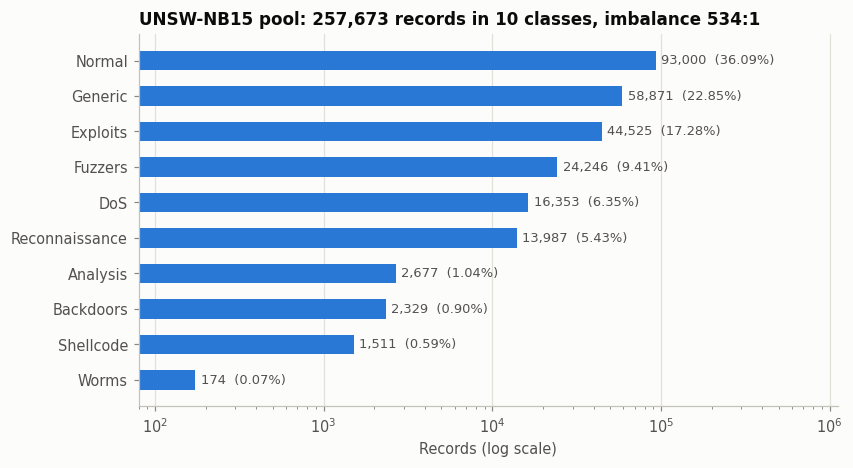

In [7]:
# 1.3  The 257,673-record pool: downsample only Normal and Generic, keep every other record (Table 1, left)
TARGETS = {"Normal": 93000, "Generic": 58871}
df = pd.concat([g.sample(n=TARGETS[c], random_state=SEED) if c in TARGETS else g
                for c, g in df.groupby("attack_cat")], ignore_index=True)
gc.collect()
assert len(df) == 257673
TARGET_COL, CAT_COLS = "attack_cat", ["proto", "service", "state"]
FEATURE_COLS = [c for c in df.columns if c not in [TARGET_COL, "label", *META_COLS]]
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]
assert len(FEATURE_COLS) == 43

vc = df[TARGET_COL].value_counts()
table1_unsw = pd.DataFrame({"Records": vc, "%": (vc / len(df) * 100).round(2)})
print(table1_unsw.to_string()); print(f"Total {len(df):,}")
imb_unsw = vc.max() / vc.min()
print(f"imbalance ratio (largest : smallest) = {imb_unsw:.0f}:1  ({vc.idxmax()} : {vc.idxmin()})")
table1_unsw.to_csv(os.path.join(OUT, "table1_unsw_distribution.csv"))
record("unsw_pool_total", len(df)); record("unsw_imbalance_ratio", round(imb_unsw))
for c in vc.index:
    record(f"unsw_count_{c}", vc[c]); record(f"unsw_pct_{c}", vc[c] / len(df) * 100)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
order = vc.sort_values().index
ax.barh(order, vc[order].values, height=0.55, color=SERIES[0])
ax.set_xscale("log"); value_axis(ax, "x")
for i, c in enumerate(order):
    ax.text(vc[c] * 1.08, i, f"{vc[c]:,}  ({vc[c] / len(df) * 100:.2f}%)", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(80, vc.max() * 12)
ax.set_xlabel("Records (log scale)")
ax.set_title(f"UNSW-NB15 pool: {len(df):,} records in 10 classes, imbalance {imb_unsw:.0f}:1")
save_fig(fig, "unsw_class_distribution")

In [8]:
# 1.4  Dataset audit before any training: features, missing values, infinities, minority classes
print(f"features used as input: {len(FEATURE_COLS)}  ({len(CAT_COLS)} categorical, {len(NUM_COLS)} numeric)")
print("  categorical:", CAT_COLS)
print("  numeric    :", ", ".join(NUM_COLS))
print("never used as input: attack_cat (the target), label (binary attack flag, a direct leak),",
      "srcip and dstip (hosts, dropped at load), Stime and Ltime (timestamps, kept only to order",
      "records for the time-aware splits in 1.21)")

miss = df[FEATURE_COLS].isna().sum()
miss = miss[miss > 0]
print("\nmissing values after cleaning:", "none" if miss.empty else miss.to_dict())
num_block = df[NUM_COLS].apply(pd.to_numeric, errors="coerce")
print("non-finite numeric entries:", int(np.isinf(num_block.to_numpy(dtype=float, na_value=0.0)).sum()),
      "| non-numeric entries in numeric columns:", int(num_block.isna().sum().sum()))
del num_block

print("\nclasses below 1% of the pool, with their ratio to Normal:")
for c, n in vc.items():
    if n / len(df) < 0.01:
        print(f"  {c:<12}{n:>7,}  ({n / len(df) * 100:.2f}%)  Normal : {c} = {vc['Normal'] / n:.0f}:1")

features used as input: 43  (3 categorical, 40 numeric)
  categorical: ['proto', 'service', 'state']
  numeric    : sport, dsport, dur, sbytes, dbytes, sttl, dttl, sloss, dloss, Sload, Dload, Spkts, Dpkts, swin, dwin, stcpb, dtcpb, smeansz, dmeansz, trans_depth, res_bdy_len, Sjit, Djit, Sintpkt, Dintpkt, tcprtt, synack, ackdat, is_sm_ips_ports, ct_state_ttl, ct_flw_http_mthd, is_ftp_login, ct_ftp_cmd, ct_srv_src, ct_srv_dst, ct_dst_ltm, ct_src_ltm, ct_src_dport_ltm, ct_dst_sport_ltm, ct_dst_src_ltm
never used as input: attack_cat (the target), label (binary attack flag, a direct leak), srcip and dstip (hosts, dropped at load), Stime and Ltime (timestamps, kept only to order records for the time-aware splits in 1.21)

missing values after cleaning: none
non-finite numeric entries: 0 | non-numeric entries in numeric columns: 0

classes below 1% of the pool, with their ratio to Normal:
  Backdoors     2,329  (0.90%)  Normal : Backdoors = 40:1
  Shellcode     1,511  (0.59%)  Normal : Shell

In [9]:
# 1.5  Duplicate and label-conflict audit, and the model-free ceiling (Section 4.5, Table 4, Section 9)
# The audit is the shared duplicate_audit() from 0.2, the same function CICIDS-2017 (2.1) and the merged
# pool (3.2) are measured with. Nothing is removed here: 1.19 trains both variants.
dup_unsw, keep_unsw, row_hash = duplicate_audit(df[FEATURE_COLS], df[TARGET_COL].values, "UNSW-NB15 pool")
grp = pd.DataFrame({"h": row_hash, "y": df[TARGET_COL].values})
nuniq = grp.groupby("h")["y"].nunique(); conflict = set(nuniq[nuniq > 1].index)
in_conf = grp["h"].isin(conflict).values
n_dup = dup_unsw["records_with_a_copy"]

# the same audit per class, so it is clear which classes the copies belong to
dup_cls = pd.DataFrame([
    dict(Class=c, Records=int((df[TARGET_COL] == c).sum()),
         Kept=int(((df[TARGET_COL] == c) & keep_unsw).sum()),
         Removed=int(((df[TARGET_COL] == c) & ~keep_unsw).sum()),
         Removed_pct=round(((df[TARGET_COL] == c) & ~keep_unsw).sum() / (df[TARGET_COL] == c).sum() * 100, 2))
    for c in sorted(df[TARGET_COL].unique())])
print("\nwhere the exact copies are:")
print(dup_cls.to_string(index=False))
dup_cls.to_csv(os.path.join(OUT, "unsw_duplicate_audit.csv"), index=False)

# the best any deterministic classifier can do is give each group its majority label
tab = grp.groupby(["h", "y"]).size().rename("n").reset_index()
tab["_r"] = tab.groupby("h")["n"].rank(method="first", ascending=False)
win = tab["_r"] == 1
max_acc = tab.loc[win, "n"].sum() / len(grp) * 100
print(f"maximum achievable accuracy on these features: {max_acc:.2f}%\n")
rows = []
for cls in sorted(grp["y"].unique()):
    sub = tab[tab["y"] == cls]; tot = int(sub["n"].sum())
    rec = int(sub.loc[win[sub.index].values, "n"].sum())
    lost = sub.index[(~win[sub.index]).values]
    to = (tab[tab["h"].isin(set(tab.loc[lost, "h"])) & win].groupby("y")["n"].sum()
          .sort_values(ascending=False).index[0]) if len(lost) else "-"
    rows.append(dict(Class=cls, Support=tot, Ceiling_recall=round(rec / tot * 100, 2),
                     Unrecoverable=tot - rec, Lost_to=to))
ceiling_df = pd.DataFrame(rows).sort_values("Ceiling_recall")
print(ceiling_df.to_string(index=False))
ceiling_df.to_csv(os.path.join(OUT, "unsw_ceiling.csv"), index=False)

print("\nwho the confused classes collide with (records of the other class on shared vectors):")
for cls in ["Analysis", "Backdoors", "DoS", "Exploits"]:
    mine = set(tab.loc[tab["y"] == cls, "h"])
    shared = tab[tab["h"].isin(mine) & (tab["y"] != cls)]
    top = shared.groupby("y")["n"].sum().sort_values(ascending=False).head(3)
    print(f"  {cls:<10}", ", ".join(f"{k} {int(v):,}" for k, v in top.items()))

record("unsw_distinct_vectors", grp["h"].nunique())
record("unsw_distinct_vector_label_pairs", dup_unsw["distinct_vector_label_pairs"])
record("unsw_extra_label_variants", dup_unsw["extra_label_variants"])
record("unsw_exact_copy_records", n_dup); record("unsw_exact_copy_pct", n_dup / len(grp) * 100)
record("unsw_conflict_groups", len(conflict)); record("unsw_conflict_records", in_conf.sum())
record("unsw_conflict_pct", in_conf.mean() * 100); record("unsw_max_accuracy", max_acc)
for _, r in ceiling_df.iterrows():
    record(f"ceiling_{r['Class']}", r["Ceiling_recall"])

=== duplicate and label-conflict audit: UNSW-NB15 pool ===
records                                          : 257,673
distinct feature vectors (43 features)            : 167,339
distinct (feature vector, label) pairs           : 176,183   <- what de-duplication keeps
  the gap between those two counts               : 8,844 extra labels carried by 2,023 vectors that appear under more than one label
records with at least one exact copy (features+label): 102,737 (39.87%)
records dropped if those copies are removed      : 81,490
records sitting on a conflicted vector           : 38,809 (15.06%)
hash check: 200/200 sampled conflict groups verified identical by exact comparison

where the exact copies are:
         Class  Records  Kept  Removed  Removed_pct
      Analysis     2677  2032      645        24.09
     Backdoors     2329  1880      449        19.28
           DoS    16353  5512    10841        66.29
      Exploits    44525 27443    17082        38.36
       Fuzzers    24246 21643 

In [10]:
# 1.6  Fold-local preprocessing: the encoder and the scaler are fitted on the training fold only
UNSEEN_CODE = -1

class FoldSafeOrdinalEncoder:
    '''Ordinal codes for proto/service/state learned from the training fold; unseen categories -> -1.'''
    def __init__(self, cols):
        self.cols = list(cols); self.maps_ = {}; self.observed_codes_ = {}
    def fit(self, X):
        for c in self.cols:
            cats = sorted(X[c].astype(str).unique())
            self.maps_[c] = {v: i for i, v in enumerate(cats)}
            self.observed_codes_[c] = np.arange(len(cats), dtype=np.float64)
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            X[c] = X[c].astype(str).map(self.maps_[c]).fillna(UNSEEN_CODE).astype(np.float64)
        return X

def snap_to_observed(arr, col_positions, observed_values):
    '''SMOTE interpolates nominal codes (proto = 63.4); snap them back to a category that exists.'''
    arr = arr.copy()
    for pos, vals in zip(col_positions, observed_values):
        arr[:, pos] = vals[np.abs(arr[:, pos][:, None] - vals[None, :]).argmin(axis=1)]
    return arr

def preprocess_fold(X_tr_raw, X_va_raw):
    enc = FoldSafeOrdinalEncoder(CAT_COLS).fit(X_tr_raw)
    Xtr, Xva = enc.transform(X_tr_raw), enc.transform(X_va_raw)
    names = list(Xtr.columns)
    cat_pos = [names.index(c) for c in CAT_COLS]
    obs = [enc.observed_codes_[c] for c in CAT_COLS]
    Xtr = Xtr.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
    Xva = Xva.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
    sc = MinMaxScaler()
    Xtr[names] = sc.fit_transform(Xtr[names])      # fitted on the training fold only
    Xva[names] = sc.transform(Xva[names])
    lo = np.array([sc.data_min_[names.index(c)] for c in CAT_COLS])
    rg = np.array([max(sc.data_range_[names.index(c)], 1e-12) for c in CAT_COLS])
    obs = [(v - l) / r for v, l, r in zip(obs, lo, rg)]
    return Xtr.values.astype(np.float32), Xva.values.astype(np.float32), names, cat_pos, obs

X_all_raw = df[FEATURE_COLS].reset_index(drop=True)
UNSW_LE, UNSW_CLASSES = make_encoder(sorted(df[TARGET_COL].unique()))
y_all = UNSW_LE.transform(df[TARGET_COL].values)
n_classes = len(UNSW_CLASSES)
splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_all_raw, y_all))
print("classes in encoded order (used by every per-class table and matrix):")
print("  " + ", ".join(f"{i}={c}" for i, c in enumerate(UNSW_CLASSES)))
record("unsw_n_features", len(FEATURE_COLS))

classes in encoded order (used by every per-class table and matrix):
  0=Analysis, 1=Backdoors, 2=DoS, 3=Exploits, 4=Fuzzers, 5=Generic, 6=Normal, 7=Reconnaissance, 8=Shellcode, 9=Worms


In [11]:
# 1.7  Leakage checks and the cross-validation audit (how many records of each class sit in each fold)
assert TARGET_COL not in X_all_raw.columns and "label" not in X_all_raw.columns
assert not any(c in X_all_raw.columns for c in LEAK_COLS + META_COLS)
_Xtr, _Xva, *_ = preprocess_fold(X_all_raw.iloc[splits[0][0]], X_all_raw.iloc[splits[0][1]])
assert _Xtr.min() >= -1e-6 and _Xtr.max() <= 1 + 1e-6, "training fold not inside [0, 1]"
n_out = int(((_Xva < -1e-6) | (_Xva > 1 + 1e-6)).sum())
print(f"fold 0: every training value is inside [0, 1]; {n_out:,} of {_Xva.size:,} validation values fall outside it,")
print("as expected when the scaler has never seen the validation fold.")
del _Xtr, _Xva

cols = {}
for f, (tr, va) in enumerate(splits):
    cols[f"fold{f} train"] = np.bincount(y_all[tr], minlength=n_classes)
    cols[f"fold{f} val"] = np.bincount(y_all[va], minlength=n_classes)
cv_counts = pd.DataFrame(cols, index=UNSW_CLASSES)
print("\nrecords per class in every training and validation fold:")
print(cv_counts.to_string())
assert (cv_counts.values > 0).all(), "a class is missing from some fold"
pool_share = np.bincount(y_all, minlength=n_classes) / len(y_all)
dev = max(np.abs(np.bincount(y_all[va], minlength=n_classes) / len(va) - pool_share).max() for _, va in splits) * 100
print(f"\nlargest gap between a validation fold's class share and the pool's: {dev:.4f} percentage points")
assert dev < 0.05, "stratification looks broken"
cv_counts.to_csv(os.path.join(OUT, "unsw_cv_fold_counts.csv"))

# A shuffled split cannot separate identical records, so some validation records have an exact copy in
# their own training fold. This measures how many, and 1.19 to 1.21 measure what it costs.
leak_rows = []
for f, (tr, va) in enumerate(splits):
    copies = int(np.isin(row_hash[va], row_hash[tr]).sum())
    leak_rows.append(dict(fold=f, validation_records=len(va), with_a_training_copy=copies,
                          pct=round(copies / len(va) * 100, 2)))
leak_tab = pd.DataFrame(leak_rows)
print("\nvalidation records whose 43-feature vector also occurs in their training fold:")
print(leak_tab.to_string(index=False))
print(f"mean {leak_tab['pct'].mean():.2f}% of each validation fold. Those records are not errors in the "
      f"corpus and\nnot removed here; cells 1.19 to 1.21 retrain under protocols that separate them.")
leak_tab.to_csv(os.path.join(OUT, "unsw_stratified_leakage_audit.csv"), index=False)
record("unsw_val_records_with_training_copy_pct", leak_tab["pct"].mean())

fold 0: every training value is inside [0, 1]; 3 of 2,216,005 validation values fall outside it,
as expected when the scaler has never seen the validation fold.

records per class in every training and validation fold:
                fold0 train  fold0 val  fold1 train  fold1 val  fold2 train  fold2 val  fold3 train  fold3 val  fold4 train  fold4 val
Analysis               2141        536         2141        536         2142        535         2142        535         2142        535
Backdoors              1863        466         1864        465         1863        466         1863        466         1863        466
DoS                   13083       3270        13082       3271        13082       3271        13082       3271        13083       3270
Exploits              35620       8905        35620       8905        35620       8905        35620       8905        35620       8905
Fuzzers               19397       4849        19397       4849        19397       4849        19397       

In [12]:
# 1.8  Capped oversampling inside the training fold, and an audit of what enters each fit
CAP = 5000

def resample_train(Xtr, ytr, name, cat_pos, obs, ncls):
    if name == "none":
        return Xtr, ytr
    before = np.bincount(ytr, minlength=ncls)
    strat = {c: CAP for c in range(ncls) if 0 < before[c] < CAP}
    if not strat:
        return Xtr, ytr
    k = min(5, int(min(before[c] for c in strat)) - 1)
    try:
        s = (SMOTE(sampling_strategy=strat, random_state=SEED, k_neighbors=k) if name == "smote"
             else ADASYN(sampling_strategy=strat, random_state=SEED, n_neighbors=k))
        Xo, yo = s.fit_resample(Xtr, ytr)
    except Exception as e:           # logged, never silent
        print(f"    {name} failed ({type(e).__name__}: {e}); RandomOverSampler used")
        Xo, yo = RandomOverSampler(sampling_strategy=strat, random_state=SEED).fit_resample(Xtr, ytr)
    return snap_to_observed(Xo, cat_pos, obs), yo

audit_rows = []
for f, (tr, va) in enumerate(splits):
    Xtr0, _, _, cat_pos, obs = preprocess_fold(X_all_raw.iloc[tr], X_all_raw.iloc[va])
    ytr0 = y_all[tr]
    before = np.bincount(ytr0, minlength=n_classes)
    after = {rs: np.bincount(resample_train(Xtr0, ytr0, rs, cat_pos, obs, n_classes)[1], minlength=n_classes)
             for rs in ["smote", "adasyn"]}
    for i, c in enumerate(UNSW_CLASSES):
        audit_rows.append(dict(fold=f, Class=c, validation=int((y_all[va] == i).sum()), train_before=int(before[i]),
                               after_smote=int(after["smote"][i]), after_adasyn=int(after["adasyn"][i])))
res_audit = pd.DataFrame(audit_rows)
res_audit.to_csv(os.path.join(OUT, "unsw_resampling_audit.csv"), index=False)

f0 = res_audit[res_audit.fold == 0].set_index("Class")
f0 = f0.assign(synthetic_smote=f0.after_smote - f0.train_before,
               pct_synthetic_smote=((f0.after_smote - f0.train_before) / f0.after_smote * 100).round(1))
print("fold 0: records per class entering the fit (validation fold untouched in every condition)")
print(f0[["validation", "train_before", "after_smote", "after_adasyn", "synthetic_smote", "pct_synthetic_smote"]].to_string())
tot = res_audit.groupby("fold")[["train_before", "after_smote", "after_adasyn"]].sum()
print("\ntraining rows per fold:\n" + tot.to_string())
print(f"\nclasses lifted to {CAP:,}: " + ", ".join(sorted(set(res_audit.loc[res_audit.train_before < CAP, 'Class']))))

fold 0: records per class entering the fit (validation fold untouched in every condition)
                validation  train_before  after_smote  after_adasyn  synthetic_smote  pct_synthetic_smote
Class                                                                                                    
Analysis               536          2141         5000          4715             2859                 57.2
Backdoors              466          1863         5000          5211             3137                 62.7
DoS                   3270         13083        13083         13083                0                  0.0
Exploits              8905         35620        35620         35620                0                  0.0
Fuzzers               4849         19397        19397         19397                0                  0.0
Generic              11775         47096        47096         47096                0                  0.0
Normal               18600         74400        74400         

In [13]:
# 1.9  Models and metrics (untuned, identical for every condition)
HYPERPARAMS = {
    "RF":  dict(n_estimators=100, n_jobs=-1, random_state=SEED),
    "XGB": dict(tree_method="hist", n_estimators=100, max_depth=8, n_jobs=-1,
                random_state=SEED, eval_metric="mlogloss", verbosity=0),
    "LGB": dict(n_estimators=100, n_jobs=-1, random_state=SEED, verbosity=-1),
}
def get_model(name):
    return {"RF": RandomForestClassifier, "XGB": xgb.XGBClassifier,
            "LGB": lgb.LGBMClassifier}[name](**HYPERPARAMS[name])

def fold_metrics(yva, pred, proba, ncls):
    '''AUC-PR comes from the class probabilities, never from hard predictions.'''
    yb = label_binarize(yva, classes=list(range(ncls)))
    return dict(accuracy=accuracy_score(yva, pred),
                precision_macro=precision_score(yva, pred, average="macro", zero_division=0),
                recall_macro=recall_score(yva, pred, average="macro", zero_division=0),
                f1_macro=f1_score(yva, pred, average="macro", zero_division=0),
                auc_pr_macro=average_precision_score(yb, proba, average="macro"))

METRICS = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_pr_macro"]
MET_LABEL = {"accuracy": "Accuracy", "precision_macro": "Macro precision", "recall_macro": "Macro recall",
             "f1_macro": "Macro F1", "auc_pr_macro": "Macro AUC-PR"}
json.dump({k: {kk: str(vv) for kk, vv in v.items()} for k, v in HYPERPARAMS.items()},
          open(os.path.join(OUT, "unsw_hyperparameters.json"), "w"), indent=2)
for k, v in HYPERPARAMS.items():
    print(f"{MODEL_LABEL[k]:<14}{v}")

Random Forest {'n_estimators': 100, 'n_jobs': -1, 'random_state': 42}
XGBoost       {'tree_method': 'hist', 'n_estimators': 100, 'max_depth': 8, 'n_jobs': -1, 'random_state': 42, 'eval_metric': 'mlogloss', 'verbosity': 0}
LightGBM      {'n_estimators': 100, 'n_jobs': -1, 'random_state': 42, 'verbosity': -1}


In [14]:
# 1.10  Main grid: 3 models x {none, SMOTE, ADASYN} x 5 folds (checkpointed after every fit)
GRID_FILE = os.path.join(OUT, "unsw_grid_folds.jsonl")
MODELS, RESAMPLERS = ["RF", "XGB", "LGB"], ["none", "smote", "adasyn"]
done = {(r["fold"], r["resampling"], r["model"]) for r in jsonl_rows(GRID_FILE)}
print(f"{len(done)} of 45 fits found in the checkpoint file")
if RUN_UNSW_GRID:
    for fold, (tr, va) in enumerate(splits):
        todo = [(rs, m) for rs in RESAMPLERS for m in MODELS if (fold, rs, m) not in done]
        if not todo:
            continue
        Xtr0, Xva, _, cat_pos, obs = preprocess_fold(X_all_raw.iloc[tr], X_all_raw.iloc[va])
        ytr0, yva = y_all[tr], y_all[va]
        for rs in RESAMPLERS:
            if all((fold, rs, m) in done for m in MODELS):
                continue
            Xtr, ytr = resample_train(Xtr0, ytr0, rs, cat_pos, obs, n_classes)
            print(f"fold{fold} {rs:<6} rows entering the fit: {len(ytr):,} ({len(ytr) - len(ytr0):,} synthetic)")
            for m in MODELS:
                if (fold, rs, m) in done:
                    continue
                t0 = time.time(); clf = get_model(m); clf.fit(Xtr, ytr)
                proba = clf.predict_proba(Xva)
                assert np.array_equal(np.asarray(clf.classes_), np.arange(n_classes))  # column order
                pred = np.argmax(proba, axis=1)
                row = fold_metrics(yva, pred, proba, n_classes)
                row.update(fold=fold, resampling=rs, model=m, n_train=int(len(ytr)),
                           recall_per_class=recall_score(yva, pred, average=None,
                               labels=list(range(n_classes)), zero_division=0).tolist(),
                           cm=confusion_matrix(yva, pred, labels=list(range(n_classes))).tolist(),
                           fit_seconds=round(time.time() - t0, 1))
                jsonl_append(GRID_FILE, row)
                print(f"   {m:<3} acc={row['accuracy']:.4f} F1_M={row['f1_macro']:.4f} "
                      f"AUC-PR_M={row['auc_pr_macro']:.4f} ({time.time() - t0:.0f}s)")
grid = pd.DataFrame(jsonl_rows(GRID_FILE)).drop_duplicates(subset=["fold", "resampling", "model"])
assert len(grid) == 45, f"only {len(grid)} of 45 fits available"
print("\nmacro F1 (%) of every fit, by fold:")
print((grid.pivot_table(index=["model", "resampling"], columns="fold", values="f1_macro") * 100).round(2).to_string())

45 of 45 fits found in the checkpoint file

macro F1 (%) of every fit, by fold:
fold                  0      1      2      3      4
model resampling                                   
LGB   adasyn      67.38  66.00  67.54  67.46  64.56
      none        58.00  58.72  58.87  58.78  58.04
      smote       67.33  66.39  67.08  67.56  64.27
RF    adasyn      67.30  65.87  66.25  66.95  64.43
      none        65.37  64.90  65.96  66.37  62.66
      smote       67.61  65.71  66.77  66.17  64.35
XGB   adasyn      67.50  66.04  66.29  66.44  65.28
      none        67.60  66.98  68.53  67.02  65.13
      smote       67.19  66.04  66.85  66.75  64.61


                      Accuracy Macro precision  Macro recall      Macro F1  Macro AUC-PR
model resampling                                                                        
RF    none        87.53 ± 0.12    77.15 ± 2.26  62.37 ± 1.17  65.05 ± 1.45  68.90 ± 1.36
      smote       87.44 ± 0.13    70.31 ± 1.17  65.50 ± 1.48  66.12 ± 1.22  67.37 ± 1.15
      adasyn      87.46 ± 0.12    70.70 ± 1.03  65.65 ± 1.31  66.16 ± 1.12  67.57 ± 1.25
XGB   none        88.38 ± 0.12    81.15 ± 0.94  64.82 ± 1.50  67.05 ± 1.24  70.95 ± 0.81
      smote       88.27 ± 0.10    71.84 ± 1.38  65.12 ± 1.17  66.29 ± 1.03  70.81 ± 1.22
      adasyn      88.25 ± 0.10    72.74 ± 1.36  65.07 ± 0.82  66.31 ± 0.80  70.83 ± 1.08
LGB   none        85.81 ± 1.01    63.16 ± 2.38  58.75 ± 0.86  58.48 ± 0.43  54.45 ± 2.09
      smote       88.49 ± 0.05    74.03 ± 1.57  65.68 ± 1.49  66.53 ± 1.34  71.46 ± 1.57
      adasyn      88.56 ± 0.09    75.02 ± 1.81  65.81 ± 1.55  66.59 ± 1.30  71.68 ± 1.35

lowest tree accuracy

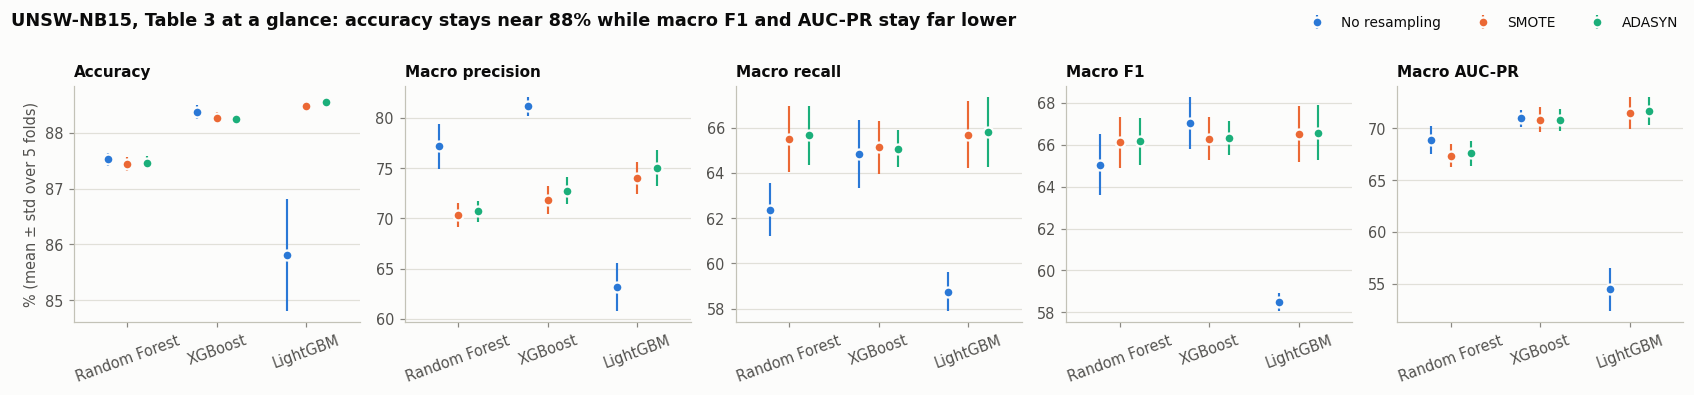

In [15]:
# 1.11  Table 3, tree rows: mean and standard deviation over the five folds
agg = grid.groupby(["model", "resampling"])[METRICS].agg(["mean", "std"]) * 100
ORDER = [(m, r) for m in MODELS for r in RESAMPLERS]
tab2_trees = pd.DataFrame({MET_LABEL[m]: [f"{agg.loc[k, (m, 'mean')]:.2f} ± {agg.loc[k, (m, 'std')]:.2f}" for k in ORDER]
                           for m in METRICS},
                          index=pd.MultiIndex.from_tuples(ORDER, names=["model", "resampling"]))
print(tab2_trees.to_string())
tab2_trees.to_csv(os.path.join(OUT, "table2_unsw_trees.csv"))
for k in ORDER:
    for m in METRICS:
        record(f"t2_{k[0]}_{k[1]}_{m}", agg.loc[k, (m, "mean")]); record(f"t2sd_{k[0]}_{k[1]}_{m}", agg.loc[k, (m, "std")])

means = agg.xs("mean", axis=1, level=1)
print(f"\nlowest tree accuracy: {means['accuracy'].min():.2f}% ({'/'.join(means['accuracy'].idxmin())}); "
      f"highest: {means['accuracy'].max():.2f}% ({'/'.join(means['accuracy'].idxmax())})")
print(f"highest macro F1: {means['f1_macro'].max():.2f}% ({'/'.join(means['f1_macro'].idxmax())}); "
      f"gap to its accuracy: {means.loc[means['f1_macro'].idxmax(), 'accuracy'] - means['f1_macro'].max():.2f} points")
record("unsw_min_tree_accuracy", means["accuracy"].min()); record("unsw_max_tree_accuracy", means["accuracy"].max())
record("unsw_max_tree_f1", means["f1_macro"].max())

fig, axes = plt.subplots(1, 5, figsize=(15.5, 3.6), sharey=False)
for ax, m in zip(axes, METRICS):
    for j, rs in enumerate(RESAMPLERS):
        x = np.arange(len(MODELS)) + (j - 1) * 0.22
        mu = [agg.loc[(md_, rs), (m, "mean")] for md_ in MODELS]
        sd = [agg.loc[(md_, rs), (m, "std")] for md_ in MODELS]
        ax.errorbar(x, mu, yerr=sd, fmt="o", ms=6.5, color=COLOR_RESAMP[rs], ecolor=COLOR_RESAMP[rs],
                    elinewidth=1.4, capsize=0, mec=SURFACE, mew=1.5, label=RESAMP_LABEL[rs])
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels([MODEL_LABEL[k] for k in MODELS], rotation=20)
    ax.set_title(MET_LABEL[m], fontsize=10); value_axis(ax)
    ax.set_xlim(-0.6, len(MODELS) - 0.4)
axes[0].set_ylabel("% (mean ± std over 5 folds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("UNSW-NB15, Table 3 at a glance: accuracy stays near 88% while macro F1 and AUC-PR stay far lower",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_fig(fig, "unsw_table2_tree_models")

        where     comparison          metric  folds  diff_pp  sd_diff  folds_favouring_first  t_stat  p_ttest  w_stat  p_wilcoxon
           RF  smote vs none        accuracy      5   -0.092    0.057                      0   -3.60 0.022745     0.0      0.0625
           RF  smote vs none precision_macro      5   -6.832    1.947                      0   -7.85 0.001425     0.0      0.0625
           RF  smote vs none    recall_macro      5    3.129    1.158                      5    6.04 0.003784     0.0      0.0625
           RF  smote vs none        f1_macro      5    1.069    0.937                      4    2.55 0.063217     1.0      0.1250
           RF  smote vs none    auc_pr_macro      5   -1.533    0.683                      0   -5.02 0.007373     0.0      0.0625
           RF adasyn vs none        accuracy      5   -0.068    0.050                      1   -3.02 0.039232     1.0      0.1250
           RF adasyn vs none precision_macro      5   -6.443    1.787                     

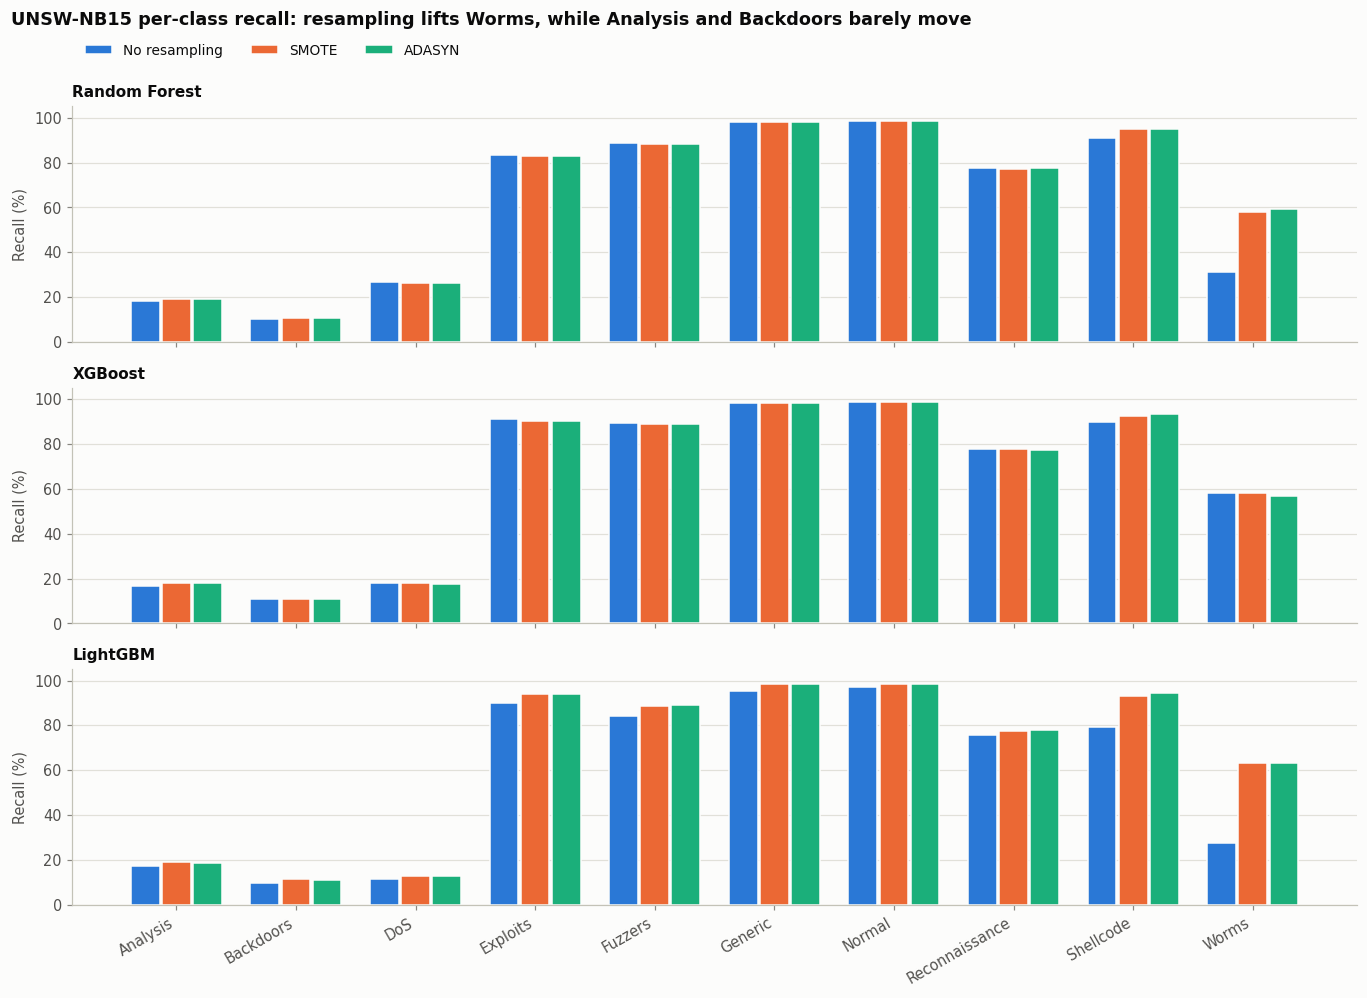

In [16]:
# 1.12  Does resampling help? Paired t-test and Wilcoxon signed-rank against no resampling, and the
#       per-class picture (Section 5.2). Both tests run on the same five fold differences.
parts = []
for m in MODELS:
    base = grid[(grid.model == m) & (grid.resampling == "none")]
    for t in ["smote", "adasyn"]:
        parts.append(paired_tests(grid[(grid.model == m) & (grid.resampling == t)], base,
                                  METRICS, m, f"{t} vs none"))
for a, b in [("XGB", "RF"), ("XGB", "LGB"), ("RF", "LGB")]:      # model against model, same folds
    parts.append(paired_tests(grid[(grid.model == a) & (grid.resampling == "none")],
                              grid[(grid.model == b) & (grid.resampling == "none")],
                              METRICS, "no resampling", f"{a} vs {b}"))
ttests = pd.concat(parts, ignore_index=True)
print(ttests.to_string(index=False))
n_folds = grid.fold.nunique()
print(f"\nCV folds share most of their training data, so read the p-values as indicative "
      f"(Dietterich 1998).\nThe signed-rank test assumes no normality but is discrete: with "
      f"{n_folds} folds its smallest possible two-sided\np-value is "
      f"{wilcoxon_floor(n_folds):.4f}, reached when every fold moves the same way, so it can never "
      f"clear 5% here.\nCell 1.23 repeats the resampling comparison with ten folds, where the floor "
      f"is {wilcoxon_floor(10):.4f}.")
both = ((ttests.p_ttest < 0.05) == (ttests.p_wilcoxon <= wilcoxon_floor(n_folds) + 1e-9))
print(f"the two tests agree on {both.mean() * 100:.0f}% of the {len(ttests)} comparisons "
      f"(t-test at 5%, signed-rank at its floor); disagreements:")
print(ttests[~both][["where", "comparison", "metric", "diff_pp", "folds_favouring_first",
                     "p_ttest", "p_wilcoxon"]].to_string(index=False) if (~both).any() else "  none")
ttests.to_csv(os.path.join(OUT, "unsw_paired_ttests.csv"), index=False)
for _, r in ttests.iterrows():
    if r["comparison"].endswith("vs none"):
        tag = f"{r['where']}_{r['comparison'].split()[0]}_{r['metric']}"
        record(f"tt_{tag}_diff", r["diff_pp"]); record(f"tt_{tag}_p", r["p_ttest"])
        record(f"wil_{tag}_p", r["p_wilcoxon"])

pcr = {(m, rs): np.mean(np.vstack(g["recall_per_class"].tolist()), axis=0) * 100
       for (m, rs), g in grid.groupby(["model", "resampling"])}
per_class = pd.DataFrame({f"{m}/{rs}": pcr[(m, rs)] for (m, rs) in ORDER}, index=UNSW_CLASSES).round(2)
print("\nper-class recall (%), mean over 5 folds:")
print(per_class.to_string()); per_class.to_csv(os.path.join(OUT, "unsw_per_class_recall.csv"))
for (m, rs) in ORDER:
    for i, c in enumerate(UNSW_CLASSES):
        record(f"pcr_{m}_{rs}_{c}", pcr[(m, rs)][i])
moves = {c: max(abs(pcr[(m, t)][UNSW_CLASSES.index(c)] - pcr[(m, "none")][UNSW_CLASSES.index(c)])
                for m in MODELS for t in ["smote", "adasyn"]) for c in ["Analysis", "Backdoors"]}
print(f"\nlargest change in Analysis / Backdoors recall under any model and method: "
      f"{moves['Analysis']:.2f} / {moves['Backdoors']:.2f} points")
record("unsw_max_move_analysis_backdoors", max(moves.values()))

fig, axes = plt.subplots(3, 1, figsize=(12.5, 9.2), sharex=True)
x = np.arange(n_classes)
for ax, m in zip(axes, MODELS):
    for j, rs in enumerate(RESAMPLERS):
        ax.bar(x + (j - 1) * 0.26, pcr[(m, rs)], width=0.24, color=COLOR_RESAMP[rs],
               edgecolor=SURFACE, linewidth=1.0, label=RESAMP_LABEL[rs])
    ax.set_ylim(0, 105); value_axis(ax); ax.set_ylabel("Recall (%)")
    ax.set_title(MODEL_LABEL[m], fontsize=10)
axes[0].legend(ncol=3, loc="upper left", bbox_to_anchor=(0.0, 1.32))
axes[-1].set_xticks(x); axes[-1].set_xticklabels(UNSW_CLASSES, rotation=30, ha="right")
fig.suptitle("UNSW-NB15 per-class recall: resampling lifts Worms, while Analysis and Backdoors barely move",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "unsw_per_class_recall_by_resampling")

### 1.13 Neural models (Table 3, last two rows)

TabNet and FT-Transformer are trained on the no-resampling condition only, on the same five folds as the
tree ensembles and with the same fold-local preprocessing. Each model holds out a stratified 10% of its
**training** fold for early stopping; the validation fold is used only for the final scores.

* **TabNet**: `n_d = n_a = 8`, 3 decision steps, batch 1,024 (virtual batch 256), up to 50 epochs with
  early stopping (patience 8) on validation log-loss. It receives the same 43-column matrix as the trees.
* **FT-Transformer**: numeric features get their own linear tokens and the three categorical features
  their own embeddings (index 0 is kept for categories unseen in training). The configuration is fixed to
  the one the paper reports as a lower bound: one encoder layer, token dimension 16, two heads, feed-forward
  width 32, dropout 0.1, AdamW (learning rate 2e-3, weight decay 1e-5), batch 1,024, five epochs.

10 of 10 neural fits found in the checkpoint file

per fold:
         model  fold  accuracy  precision_macro  recall_macro  f1_macro  auc_pr_macro  epochs_run  best_epoch  fit_seconds
FT-Transformer     0     82.32            37.77         39.93     38.21         46.02           5           4          7.2
FT-Transformer     1     82.17            37.82         39.67     37.98         45.30           5           4          7.3
FT-Transformer     2     82.54            41.51         40.50     39.22         45.95           5           4          7.4
FT-Transformer     3     83.28            47.20         43.00     42.65         50.45           5           4          7.4
FT-Transformer     4     81.77            37.24         39.02     37.27         42.88           5           4          7.3
        TabNet     0     86.70            54.41         55.37     54.09         62.11          21          12        163.3
        TabNet     1     86.42            70.77         54.35     53.78       

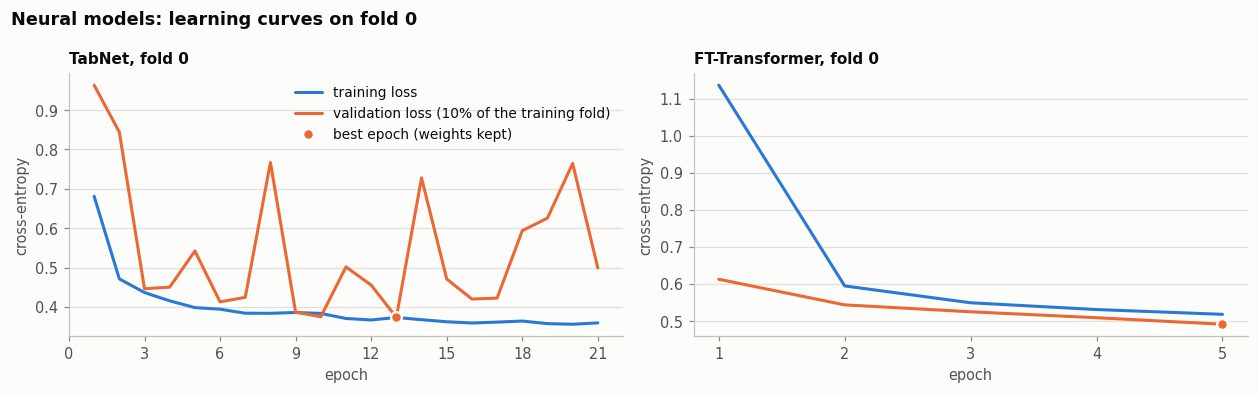

In [17]:
# 1.13  TabNet and FT-Transformer, no resampling, 5 folds (checkpointed per fold and model)
NEURAL_FILE = os.path.join(OUT, "unsw_neural_folds.jsonl")
TABNET_ARCH = dict(n_d=8, n_a=8, n_steps=3)
TABNET_FIT = dict(max_epochs=50, patience=8, batch_size=1024, virtual_batch_size=256)
FT_ARCH = dict(d_token=16, n_layers=1, n_heads=2, d_ffn=32, dropout=0.1)
FT_FIT = dict(max_epochs=5, patience=3, lr=2e-3, weight_decay=1e-5, batch_size=1024)
EVAL_BATCH = 8192
NEURAL_MODELS = ["TabNet", "FT-Transformer"]
neural_done = {(r["fold"], r["model"]) for r in jsonl_rows(NEURAL_FILE)}
print(f"{len(neural_done)} of 10 neural fits found in the checkpoint file")

if RUN_NEURAL and len(neural_done) < 10:
    import torch, torch.nn as nn
    from pytorch_tabnet.tab_model import TabNetClassifier
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    print("device:", DEVICE, "| torch", torch.__version__)

    class FeatureTokenizer(nn.Module):
        '''One linear projection per numeric feature, one embedding table per categorical feature,
        plus a learned CLS token (Gorishniy et al., 2021).'''
        def __init__(self, n_num, cat_cards, d_token):
            super().__init__()
            self.num_weight = nn.Parameter(torch.empty(n_num, d_token))
            self.num_bias = nn.Parameter(torch.empty(n_num, d_token))
            nn.init.uniform_(self.num_weight, -1 / d_token ** 0.5, 1 / d_token ** 0.5)
            nn.init.uniform_(self.num_bias, -1 / d_token ** 0.5, 1 / d_token ** 0.5)
            self.cat_embeddings = nn.ModuleList([nn.Embedding(c, d_token) for c in cat_cards])
            self.cls = nn.Parameter(torch.empty(1, 1, d_token))
            nn.init.uniform_(self.cls, -1 / d_token ** 0.5, 1 / d_token ** 0.5)
        def forward(self, x_num, x_cat):
            num_tok = x_num.unsqueeze(-1) * self.num_weight + self.num_bias
            cat_tok = torch.stack([e(x_cat[:, i]) for i, e in enumerate(self.cat_embeddings)], dim=1)
            tokens = torch.cat([num_tok, cat_tok], dim=1)
            return torch.cat([self.cls.expand(x_num.size(0), -1, -1), tokens], dim=1)

    class FTTransformer(nn.Module):
        def __init__(self, n_num, cat_cards, n_cls, d_token, n_layers, n_heads, d_ffn, dropout):
            super().__init__()
            self.tokenizer = FeatureTokenizer(n_num, cat_cards, d_token)
            layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=d_ffn,
                                               dropout=dropout, batch_first=True, activation="gelu")
            self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
            self.norm = nn.LayerNorm(d_token)
            self.head = nn.Sequential(nn.Linear(d_token, d_ffn), nn.GELU(), nn.Linear(d_ffn, n_cls))
        def forward(self, x_num, x_cat):
            return self.head(self.norm(self.encoder(self.tokenizer(x_num, x_cat))[:, 0]))

    def ft_inputs(X_tr_raw, X_va_raw):
        '''Numeric block Min-Max scaled and categorical codes shifted by one (0 = unseen), both learned
        from the training fold only.'''
        enc = FoldSafeOrdinalEncoder(CAT_COLS).fit(X_tr_raw)
        num = lambda X: (X[NUM_COLS].apply(pd.to_numeric, errors="coerce")
                         .replace([np.inf, -np.inf], np.nan).fillna(0.0).values)
        ntr, nva = num(X_tr_raw), num(X_va_raw)
        sc = MinMaxScaler().fit(ntr)
        ctr = (enc.transform(X_tr_raw)[CAT_COLS].values + 1).astype(np.int64)
        cva = (enc.transform(X_va_raw)[CAT_COLS].values + 1).astype(np.int64)
        cards = [len(enc.maps_[c]) + 1 for c in CAT_COLS]
        return sc.transform(ntr).astype(np.float32), sc.transform(nva).astype(np.float32), ctr, cva, cards

    def save_neural(fold, model_name, yva, proba, n_train, seconds, extra):
        pred = np.argmax(proba, axis=1)
        row = fold_metrics(yva, pred, proba, n_classes)
        row.update(fold=fold, model=model_name, resampling="none", n_train=int(n_train),
                   fit_seconds=round(seconds, 1),
                   recall_per_class=recall_score(yva, pred, average=None, labels=list(range(n_classes)),
                                                 zero_division=0).tolist(),
                   cm=confusion_matrix(yva, pred, labels=list(range(n_classes))).tolist(), **extra)
        jsonl_append(NEURAL_FILE, row)
        print(f"fold{fold} {model_name:<14} acc={row['accuracy']:.4f} F1_M={row['f1_macro']:.4f} "
              f"AUC-PR_M={row['auc_pr_macro']:.4f} epochs={extra['epochs_run']} "
              f"(best {extra['best_epoch']}) {seconds:.0f}s")

    for fold, (tr, va) in enumerate(splits):
        ytr, yva = y_all[tr], y_all[va]
        if (fold, "TabNet") not in neural_done:
            Xtr, Xva, *_ = preprocess_fold(X_all_raw.iloc[tr], X_all_raw.iloc[va])
            Xf, Xv, yf, yv = train_test_split(Xtr, ytr, test_size=0.1, stratify=ytr, random_state=SEED)
            t0 = time.time()
            clf = TabNetClassifier(**TABNET_ARCH, seed=SEED, verbose=0, device_name=DEVICE)
            clf.fit(Xf, yf, eval_set=[(Xv, yv)], eval_metric=["logloss"], **TABNET_FIT)
            seconds = time.time() - t0
            assert list(clf.classes_) == list(range(n_classes))
            proba = clf.predict_proba(Xva)
            hist = clf.history.history
            save_neural(fold, "TabNet", yva, proba, len(yf), seconds,
                        dict(epochs_run=len(hist["loss"]), best_epoch=int(clf.best_epoch),
                             train_loss=[float(v) for v in hist["loss"]],
                             val_loss=[float(v) for v in hist["val_0_logloss"]]))
            del clf, Xtr, Xva; gc.collect()

        if (fold, "FT-Transformer") not in neural_done:
            ntr, nva, ctr, cva, cards = ft_inputs(X_all_raw.iloc[tr], X_all_raw.iloc[va])
            idx_f, idx_v = train_test_split(np.arange(len(ytr)), test_size=0.1, stratify=ytr, random_state=SEED)
            dev = torch.device(DEVICE)
            T = lambda a, dt: torch.tensor(a, dtype=dt, device=dev)
            Xf_n, Xf_c, yf_t = T(ntr[idx_f], torch.float32), T(ctr[idx_f], torch.long), T(ytr[idx_f], torch.long)
            Xv_n, Xv_c, yv_t = T(ntr[idx_v], torch.float32), T(ctr[idx_v], torch.long), T(ytr[idx_v], torch.long)
            torch.manual_seed(SEED)
            model = FTTransformer(ntr.shape[1], cards, n_classes, **FT_ARCH).to(dev)
            opt = torch.optim.AdamW(model.parameters(), lr=FT_FIT["lr"], weight_decay=FT_FIT["weight_decay"])
            loss_fn = nn.CrossEntropyLoss()

            def logits(Xn, Xc):
                model.eval()
                with torch.no_grad():
                    return torch.cat([model(Xn[b:b + EVAL_BATCH], Xc[b:b + EVAL_BATCH])
                                      for b in range(0, Xn.shape[0], EVAL_BATCH)])

            train_losses, val_losses, best, best_state, bad = [], [], np.inf, None, 0
            n, bs, t0 = Xf_n.shape[0], FT_FIT["batch_size"], time.time()
            for epoch in range(FT_FIT["max_epochs"]):
                model.train(); perm = torch.randperm(n, device=dev); ep = 0.0
                for b in range(0, n, bs):
                    idx = perm[b:b + bs]
                    opt.zero_grad()
                    loss = loss_fn(model(Xf_n[idx], Xf_c[idx]), yf_t[idx])
                    loss.backward(); opt.step()
                    ep += loss.item() * len(idx)
                train_losses.append(ep / n)
                val_losses.append(loss_fn(logits(Xv_n, Xv_c), yv_t).item())
                print(f"   fold{fold} FT-Transformer epoch {epoch}: train loss {train_losses[-1]:.4f}, "
                      f"validation loss {val_losses[-1]:.4f} ({time.time() - t0:.0f}s)")
                if val_losses[-1] < best - 1e-4:
                    best, best_state, bad = val_losses[-1], {k: v.clone() for k, v in model.state_dict().items()}, 0
                else:
                    bad += 1
                    if bad >= FT_FIT["patience"]:
                        break
            seconds = time.time() - t0
            model.load_state_dict(best_state)
            proba = torch.softmax(logits(T(nva, torch.float32), T(cva, torch.long)), dim=1).cpu().numpy()
            save_neural(fold, "FT-Transformer", yva, proba, len(idx_f), seconds,
                        dict(epochs_run=len(train_losses), best_epoch=int(np.argmin(val_losses)),
                             train_loss=train_losses, val_loss=val_losses))
            del model, opt, Xf_n, Xf_c, Xv_n, Xv_c; gc.collect()

neural = pd.DataFrame(jsonl_rows(NEURAL_FILE))
if len(neural):
    neural = neural.drop_duplicates(subset=["fold", "model"])
    nagg = neural.groupby("model")[METRICS].agg(["mean", "std"]) * 100
    for mdl in NEURAL_MODELS:
        if mdl in nagg.index:
            for m in METRICS:
                record(f"t2_{mdl}_none_{m}", nagg.loc[mdl, (m, "mean")])
                record(f"t2sd_{mdl}_none_{m}", nagg.loc[mdl, (m, "std")])
    print("\nper fold:")
    print(neural.assign(**{m: (neural[m] * 100).round(2) for m in METRICS})
          [["model", "fold"] + METRICS + ["epochs_run", "best_epoch", "fit_seconds"]]
          .sort_values(["model", "fold"]).to_string(index=False))
    for mdl in NEURAL_MODELS:
        g = neural[neural.model == mdl]
        if len(g):
            still = sum(v[-1] <= min(v) + 1e-9 for v in g["val_loss"])
            capped = sum(e >= (TABNET_FIT if mdl == "TabNet" else FT_FIT)["max_epochs"] for e in g["epochs_run"])
            print(f"{mdl}: {capped}/5 folds used every allowed epoch; "
                  f"validation loss was still at its lowest in the last epoch in {still}/5 folds")

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    for ax, mdl in zip(axes, NEURAL_MODELS):
        g = neural[(neural.model == mdl) & (neural.fold == 0)]
        if not len(g):
            continue
        tl, vl = g.iloc[0]["train_loss"], g.iloc[0]["val_loss"]
        ep = np.arange(1, len(tl) + 1)
        b = int(g.iloc[0]["best_epoch"])
        ax.plot(ep, tl, color=SERIES[0], label="training loss")
        ax.plot(ep, vl, color=SERIES[1], label="validation loss (10% of the training fold)")
        ax.plot(ep[b], vl[b], "o", color=SERIES[1], ms=7, mec=SURFACE, mew=1.5,
                label="best epoch (weights kept)")
        ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.set_title(f"{mdl}, fold 0", fontsize=10)
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        value_axis(ax)
    axes[0].legend(loc="upper right")
    fig.suptitle("Neural models: learning curves on fold 0", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "unsw_neural_learning_curves")
else:
    print("no neural results yet (RUN_NEURAL is False)")

In [18]:
# 1.14  Table 3 complete: tree ensembles under every condition, then the two neural models
rows = []
for (mdl, rs) in ORDER:
    rows.append(dict(Model=MODEL_LABEL[mdl], Resampling=RESAMP_LABEL[rs],
                     **{MET_LABEL[m]: (agg.loc[(mdl, rs), (m, "mean")], agg.loc[(mdl, rs), (m, "std")]) for m in METRICS}))
if len(neural):
    for mdl in NEURAL_MODELS:
        if mdl in nagg.index:
            rows.append(dict(Model=mdl, Resampling=RESAMP_LABEL["none"],
                             **{MET_LABEL[m]: (nagg.loc[mdl, (m, "mean")], nagg.loc[mdl, (m, "std")]) for m in METRICS}))
t2 = pd.DataFrame(rows)
best = {MET_LABEL[m]: max(v[0] for v in t2[MET_LABEL[m]]) for m in METRICS}
show = t2[["Model", "Resampling"]].copy()
for m in METRICS:
    col = MET_LABEL[m]
    show[col] = [f"{mu:.2f} ± {sd:.2f}" + (" *" if abs(mu - best[col]) < 1e-9 else "") for mu, sd in t2[col]]
print("Table 3. UNSW-NB15, 5-fold cross-validated results (mean ± std, %). * = best in its column")
print(show.to_string(index=False))
show.to_csv(os.path.join(OUT, "table2_unsw_complete.csv"), index=False)

if len(neural) and "TabNet" in nagg.index:
    tn = nagg.loc["TabNet", ("auc_pr_macro", "mean")]
    below = [f"{MODEL_LABEL[k[0]]}/{RESAMP_LABEL[k[1]]}" for k in ORDER if agg.loc[k, ("auc_pr_macro", "mean")] < tn]
    print(f"\nTabNet macro AUC-PR {tn:.2f}%; tree configurations below it: {below if below else 'none'}")
    record("tabnet_aucpr_beats_only_lgb_none", 1.0 if below == ["LightGBM/No resampling"] else 0.0)

Table 3. UNSW-NB15, 5-fold cross-validated results (mean ± std, %). * = best in its column
         Model    Resampling       Accuracy Macro precision   Macro recall       Macro F1   Macro AUC-PR
 Random Forest No resampling   87.53 ± 0.12    77.15 ± 2.26   62.37 ± 1.17   65.05 ± 1.45   68.90 ± 1.36
 Random Forest         SMOTE   87.44 ± 0.13    70.31 ± 1.17   65.50 ± 1.48   66.12 ± 1.22   67.37 ± 1.15
 Random Forest        ADASYN   87.46 ± 0.12    70.70 ± 1.03   65.65 ± 1.31   66.16 ± 1.12   67.57 ± 1.25
       XGBoost No resampling   88.38 ± 0.12  81.15 ± 0.94 *   64.82 ± 1.50 67.05 ± 1.24 *   70.95 ± 0.81
       XGBoost         SMOTE   88.27 ± 0.10    71.84 ± 1.38   65.12 ± 1.17   66.29 ± 1.03   70.81 ± 1.22
       XGBoost        ADASYN   88.25 ± 0.10    72.74 ± 1.36   65.07 ± 0.82   66.31 ± 0.80   70.83 ± 1.08
      LightGBM No resampling   85.81 ± 1.01    63.16 ± 2.38   58.75 ± 0.86   58.48 ± 0.43   54.45 ± 2.09
      LightGBM         SMOTE   88.49 ± 0.05    74.03 ± 1.57   65.68 ±

XGBoost without resampling, pooled over the 5 validation folds: 257,673 predictions (the whole pool)


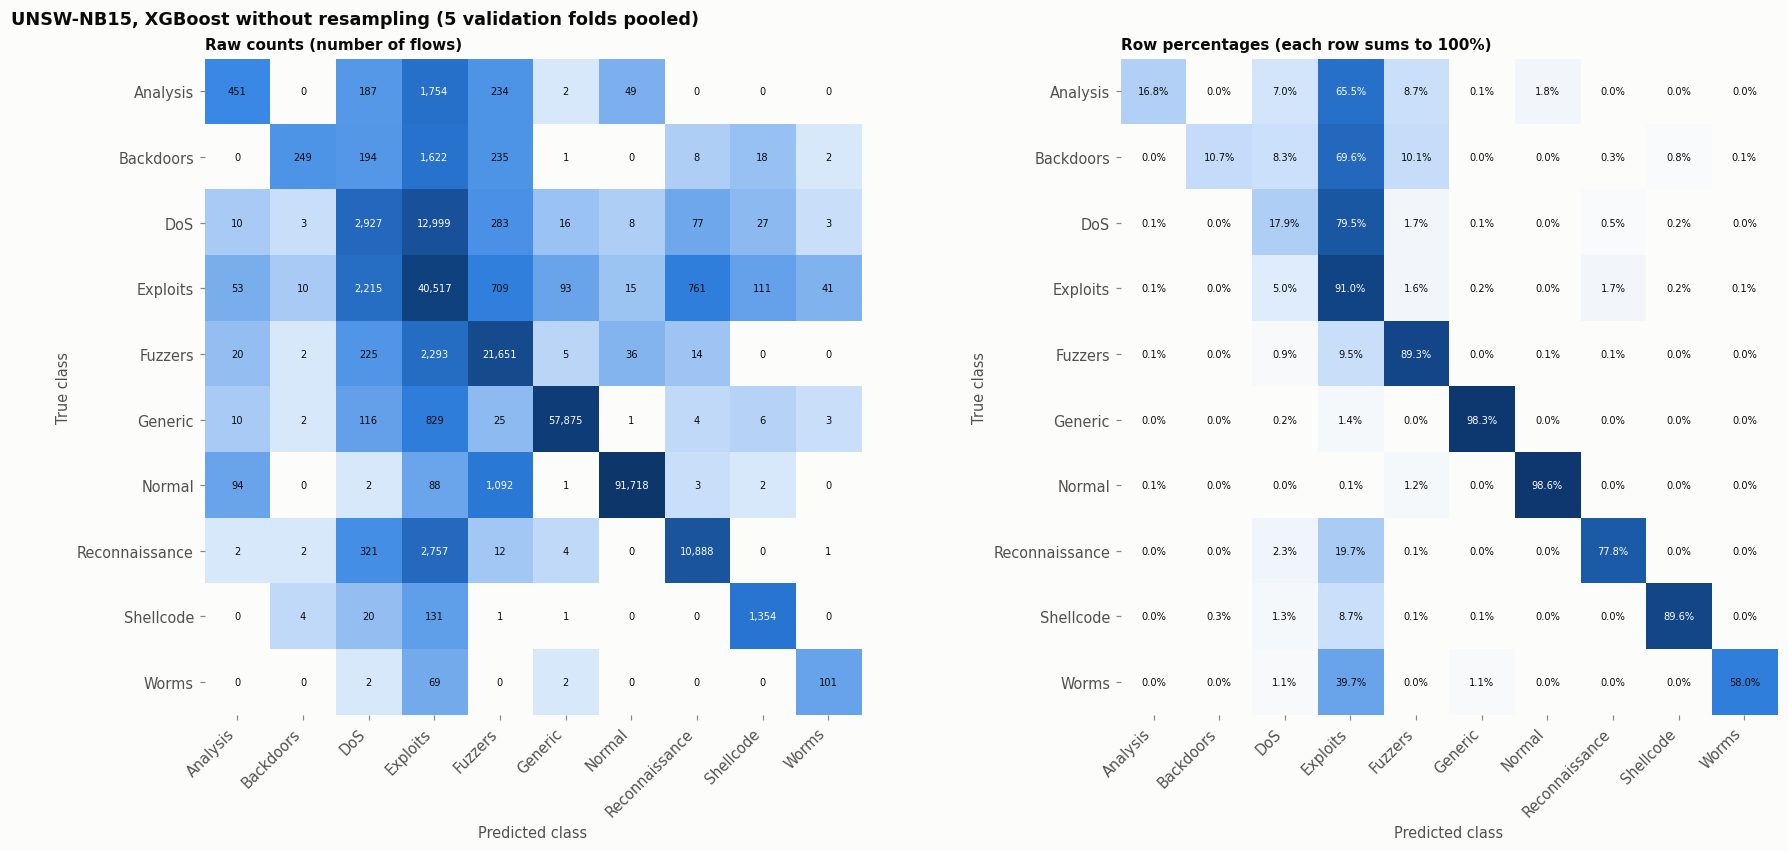

         Class  Support  Correct  Recall_pct  Precision_pct Most_errors_go_to  Errors_to_it
      Analysis     2677      451       16.85          70.47          Exploits          1754
     Backdoors     2329      249       10.69          91.54          Exploits          1622
           DoS    16353     2927       17.90          47.14          Exploits         12999
      Exploits    44525    40517       91.00          64.25               DoS          2215
       Fuzzers    24246    21651       89.30          89.31          Exploits          2293
       Generic    58871    57875       98.31          99.78          Exploits           829
        Normal    93000    91718       98.62          99.88           Fuzzers          1092
Reconnaissance    13987    10888       77.84          92.62          Exploits          2757
     Shellcode     1511     1354       89.61          89.20          Exploits           131
         Worms      174      101       58.05          66.89          Exploits   

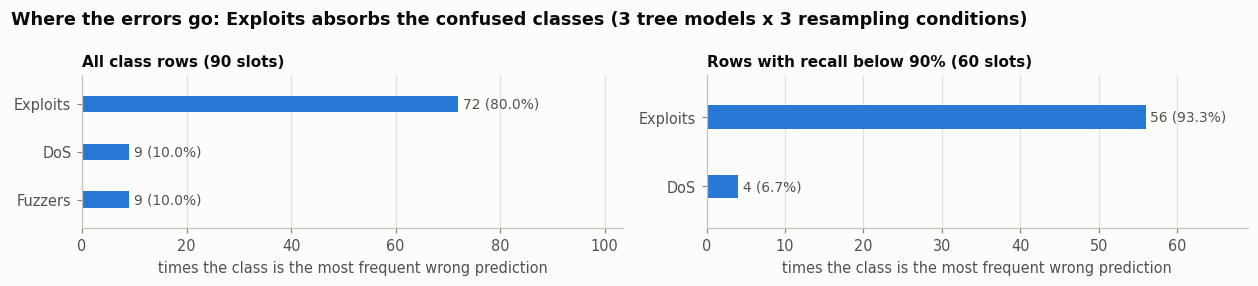

In [19]:
# 1.15  Where the errors go: pooled confusion matrix of XGBoost and the attractor tally (Section 5.3)
pooled = {(m, rs): np.sum(np.array(g["cm"].tolist()), axis=0) for (m, rs), g in grid.groupby(["model", "resampling"])}
cm_xgb = pooled[("XGB", "none")]
print(f"XGBoost without resampling, pooled over the 5 validation folds: {cm_xgb.sum():,} predictions (the whole pool)")
plot_confusion_pair(cm_xgb, UNSW_CLASSES, "UNSW-NB15, XGBoost without resampling (5 validation folds pooled)",
                    "unsw_confusion_xgb_none")
summ_xgb = confusion_summary(cm_xgb, UNSW_CLASSES)
print(summ_xgb.to_string(index=False))
summ_xgb.to_csv(os.path.join(OUT, "unsw_confusion_summary_xgb_none.csv"), index=False)
for c in ["Analysis", "Backdoors", "DoS"]:
    record(f"xgb_none_top_wrong_is_exploits_{c}",
           1.0 if summ_xgb.set_index("Class").loc[c, "Most_errors_go_to"] == "Exploits" else 0.0)

# the other eight tree configurations are saved as figures without being displayed here
for (m, rs), cm in pooled.items():
    if (m, rs) != ("XGB", "none"):
        plot_confusion_pair(cm, UNSW_CLASSES, f"UNSW-NB15, {MODEL_LABEL[m]}, {RESAMP_LABEL[rs]}",
                            f"unsw_confusion_{m.lower()}_{rs}", show=False)
print("confusion matrices of all 9 tree configurations saved in", FIG_DIR)

def tally(recall_below=None):
    t, n = {}, 0
    for cm in pooled.values():
        for i in range(n_classes):
            r = cm[i, i] / cm[i].sum() * 100
            if recall_below is not None and r >= recall_below:
                continue
            off = cm[i].copy(); off[i] = -1
            j = UNSW_CLASSES[int(np.argmax(off))]; t[j] = t.get(j, 0) + 1; n += 1
    return n, dict(sorted(t.items(), key=lambda x: -x[1]))
n_all, t_all = tally(); n_hard, t_hard = tally(90.0)
print(f"\nattractor tally, every (class, model, resampling) slot: {n_all} slots ->", t_all)
print(f"attractor tally, only classes with recall below 90%:    {n_hard} slots ->", t_hard)
record("attr_slots_all", n_all); record("attr_exploits_all", t_all.get("Exploits", 0))
record("attr_dos_all", t_all.get("DoS", 0)); record("attr_fuzzers_all", t_all.get("Fuzzers", 0))
record("attr_n_winners_all", len(t_all))
record("attr_slots_hard", n_hard); record("attr_exploits_hard", t_hard.get("Exploits", 0)); record("attr_dos_hard", t_hard.get("DoS", 0))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 2.6))
for ax, (n, t, ttl) in zip(axes, [(n_all, t_all, f"All class rows ({n_all} slots)"),
                                  (n_hard, t_hard, f"Rows with recall below 90% ({n_hard} slots)")]):
    items = list(t.items())[::-1]
    ax.barh([k for k, _ in items], [v for _, v in items], height=0.34, color=SERIES[0])
    ax.set_ylim(-0.6, len(items) - 0.4)
    for i, (k, v) in enumerate(items):
        ax.text(v + n * 0.01, i, f"{v} ({v / n * 100:.1f}%)", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, n * 1.15); value_axis(ax, "x"); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("times the class is the most frequent wrong prediction")
fig.suptitle("Where the errors go: Exploits absorbs the confused classes (3 tree models x 3 resampling conditions)",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "unsw_attractor_tally")

Table 4. Ceiling recall under accuracy-optimal labelling against observed XGBoost recall (%)
                Observed (XGBoost, none)  Ceiling  Headroom
Exploits                           91.00    88.25     -2.75
Fuzzers                            89.30    88.57     -0.73
Generic                            98.31    99.02      0.71
Normal                             98.62   100.00      1.38
Backdoors                          10.69    15.67      4.98
Reconnaissance                     77.84    84.14      6.30
Analysis                           16.85    23.23      6.38
Shellcode                          89.61   100.00     10.39
Worms                              58.05    91.38     33.33
DoS                                17.90    57.93     40.03

maximum achievable accuracy 91.58% vs XGBoost's observed 88.38%: 3.20 points apart


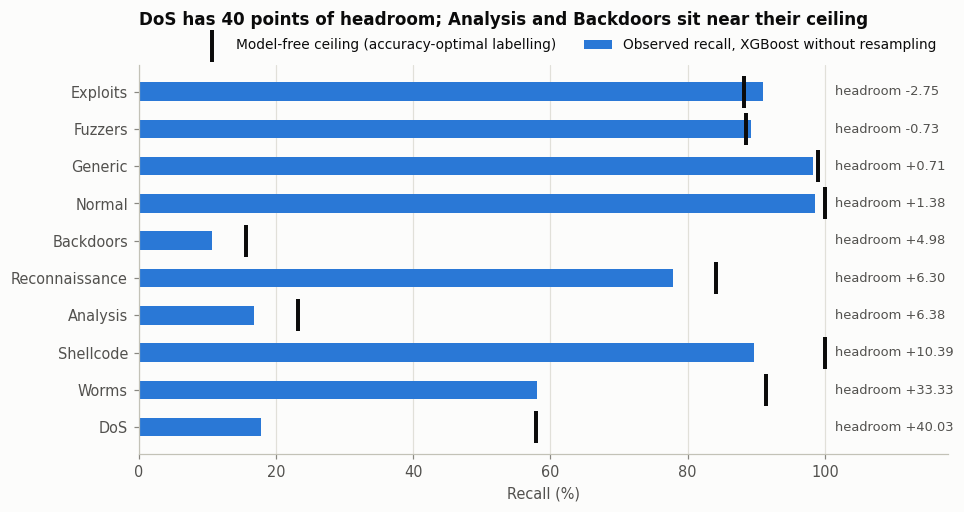

In [20]:
# 1.16  Model-free ceiling against observed recall (Table 4)
obs_xgb = per_class["XGB/none"]
ceil = ceiling_df.set_index("Class")["Ceiling_recall"].reindex(UNSW_CLASSES)
table3 = pd.DataFrame({"Observed (XGBoost, none)": obs_xgb, "Ceiling": ceil,
                       "Headroom": (ceil - obs_xgb).round(2)}).sort_values("Headroom")
print("Table 4. Ceiling recall under accuracy-optimal labelling against observed XGBoost recall (%)")
print(table3.to_string())
table3.to_csv(os.path.join(OUT, "table3_unsw_ceiling_vs_observed.csv"))
for c in UNSW_CLASSES:
    record(f"headroom_{c}", ceil[c] - obs_xgb[c])
print(f"\nmaximum achievable accuracy {max_acc:.2f}% vs XGBoost's observed "
      f"{agg.loc[('XGB', 'none'), ('accuracy', 'mean')]:.2f}%: "
      f"{max_acc - agg.loc[('XGB', 'none'), ('accuracy', 'mean')]:.2f} points apart")
record("unsw_ceiling_gap_to_xgb", max_acc - agg.loc[("XGB", "none"), ("accuracy", "mean")])

fig, ax = plt.subplots(figsize=(9.5, 4.6))
order_c = table3.index[::-1]
y = np.arange(len(order_c))
ax.barh(y, table3.loc[order_c, "Observed (XGBoost, none)"], height=0.5, color=SERIES[0],
        label="Observed recall, XGBoost without resampling")
ax.scatter(table3.loc[order_c, "Ceiling"], y, marker="|", s=420, linewidths=2.6, color=INK,
           label="Model-free ceiling (accuracy-optimal labelling)", zorder=3)
for i, c in enumerate(order_c):
    ax.text(101.5, i, f"headroom {table3.loc[c, 'Headroom']:+.2f}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(order_c); ax.set_xlim(0, 118); value_axis(ax, "x")
ax.set_xlabel("Recall (%)"); ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
ax.set_title("DoS has 40 points of headroom; Analysis and Backdoors sit near their ceiling", pad=26)
save_fig(fig, "unsw_ceiling_vs_observed")

In [21]:
# 1.17  De-duplicated control (Section 9) and the Exploits removal ablations (Section 5.4)
EXTRA_FILE = os.path.join(OUT, "unsw_extras.jsonl")
have = {(r["exp"], r["fold"], r["model"]) for r in jsonl_rows(EXTRA_FILE)}

def run_variant(exp, X_raw, y, classes, models):
    for fold, (tr, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_raw, y)):
        if all((exp, fold, m) in have for m in models):
            continue
        Xtr, Xva, *_ = preprocess_fold(X_raw.iloc[tr], X_raw.iloc[va])
        for m in models:
            if (exp, fold, m) in have:
                continue
            clf = get_model(m); clf.fit(Xtr, y[tr]); proba = clf.predict_proba(Xva)
            pred = np.argmax(proba, 1)
            row = fold_metrics(y[va], pred, proba, len(classes))
            row.update(exp=exp, fold=fold, model=m, classes=classes,
                       cm=confusion_matrix(y[va], pred, labels=list(range(len(classes)))).tolist())
            jsonl_append(EXTRA_FILE, row); print(exp, fold, m, round(row["f1_macro"], 4))

keep = ~pd.DataFrame({"h": row_hash, "y": y_all}).duplicated(subset=["h", "y"], keep="first").values
print(f"de-duplicated pool: {keep.sum():,} records ({(~keep).sum():,} copies removed)")
record("dedup_records", keep.sum())
if RUN_UNSW_EXTRAS:
    run_variant("dedup", X_all_raw[keep].reset_index(drop=True), y_all[keep], UNSW_CLASSES, ["XGB"])
    for drop, exp in [(["Exploits"], "drop_exploits"), (["Exploits", "DoS"], "drop_exploits_and_dos")]:
        sub = df[~df[TARGET_COL].isin(drop)].reset_index(drop=True)
        le_v, cls_v = make_encoder(sorted(sub[TARGET_COL].unique()))
        run_variant(exp, sub[FEATURE_COLS].reset_index(drop=True),
                    le_v.transform(sub[TARGET_COL].values), cls_v, ["RF", "XGB", "LGB"])

ex = pd.DataFrame(jsonl_rows(EXTRA_FILE))
if len(ex):
    ex = ex.drop_duplicates(subset=["exp", "fold", "model"])
    dd = ex[ex.exp == "dedup"]; base = grid[(grid.model == "XGB") & (grid.resampling == "none")]
    dd_tab = pd.DataFrame({"with duplicates": [base[m].mean() * 100 for m in METRICS],
                           "de-duplicated": [dd[m].mean() * 100 for m in METRICS]},
                          index=[MET_LABEL[m] for m in METRICS]).round(2)
    print("\nDe-duplicated control, XGBoost without resampling (mean over 5 folds, %):")
    print(dd_tab.to_string())
    for m in METRICS:
        record(f"dedup_{m}", dd[m].mean() * 100)

    abl_rows = []
    for exp in ["drop_exploits", "drop_exploits_and_dos"]:
        for m in MODELS:
            g = ex[(ex.exp == exp) & (ex.model == m)]
            if len(g) < 5:
                continue
            cls_v = g["classes"].iloc[0]; cm = np.sum(np.array(g["cm"].tolist()), axis=0)
            cm10 = pooled[(m, "none")]
            for c in ["Analysis", "Backdoors", "DoS"]:
                if c not in cls_v:
                    continue
                i, i10 = cls_v.index(c), UNSW_CLASSES.index(c)
                off = cm[i].copy(); off[i] = -1
                off10 = cm10[i10].copy(); off10[i10] = -1
                r0, r1 = cm10[i10, i10] / cm10[i10].sum() * 100, cm[i, i] / cm[i].sum() * 100
                abl_rows.append(dict(ablation=exp, model=m, Class=c, recall_10_classes=round(r0, 2),
                                     recall_after=round(r1, 2), change=round(r1 - r0, 2),
                                     top_wrong_before=UNSW_CLASSES[int(np.argmax(off10))],
                                     top_wrong_after=cls_v[int(np.argmax(off))]))
                record(f"abl_{exp}_{m}_{c}_after", r1); record(f"abl_{exp}_{m}_{c}_change", r1 - r0)
    abl = pd.DataFrame(abl_rows)
    print("\nExploits ablations: recall of the confused classes before and after removing classes (pooled over folds)")
    print(abl.to_string(index=False))
    abl.to_csv(os.path.join(OUT, "unsw_exploits_ablations.csv"), index=False)

de-duplicated pool: 176,183 records (81,490 copies removed)

De-duplicated control, XGBoost without resampling (mean over 5 folds, %):
                 with duplicates  de-duplicated
Accuracy                   88.38          90.24
Macro precision            81.15          68.18
Macro recall               64.82          65.37
Macro F1                   67.05          66.19
Macro AUC-PR               70.95          73.11

Exploits ablations: recall of the confused classes before and after removing classes (pooled over folds)
             ablation model     Class  recall_10_classes  recall_after  change top_wrong_before top_wrong_after
        drop_exploits    RF  Analysis              18.34         20.25    1.91         Exploits             DoS
        drop_exploits    RF Backdoors              10.30         10.78    0.47         Exploits             DoS
        drop_exploits    RF       DoS              26.62         93.83   67.21         Exploits         Fuzzers
        drop_exploits  

In [22]:
# 1.18  Genetic-algorithm feature selection, validated on the same folds with the same XGBoost (Section 5.4)
GA_FILE = os.path.join(OUT, "unsw_ga_check.json")
if os.path.exists(GA_FILE):
    ga = json.load(open(GA_FILE)); print("GA result loaded from", GA_FILE)
elif RUN_GA_CHECK:
    from deap import base, creator, tools, algorithms
    idx = np.arange(len(y_all))
    isub, _ = train_test_split(idx, train_size=70000, stratify=y_all, random_state=SEED)
    itr, iva = train_test_split(isub, test_size=0.3, stratify=y_all[isub], random_state=SEED)
    Xp_tr, Xp_va, *_ = preprocess_fold(X_all_raw.iloc[itr], X_all_raw.iloc[iva])
    NF = len(FEATURE_COLS)

    def fitness(ind):
        '''Macro F1 of a small XGBoost on a held-out proxy split drawn from the pool.'''
        mask = np.array(ind, dtype=bool)
        if mask.sum() < 5:
            return (0.0,)
        clf = xgb.XGBClassifier(n_estimators=60, max_depth=5, learning_rate=0.3, tree_method="hist",
                                random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
        clf.fit(Xp_tr[:, mask], y_all[itr])
        return (f1_score(y_all[iva], clf.predict(Xp_va[:, mask]), average="macro", zero_division=0),)

    if not hasattr(creator, "FitnessMax"):
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
        creator.create("Individual", list, fitness=creator.FitnessMax)
    tb = base.Toolbox()
    tb.register("attr_bool", random.randint, 0, 1)
    tb.register("individual", tools.initRepeat, creator.Individual, tb.attr_bool, n=NF)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", fitness)
    tb.register("mate", tools.cxTwoPoint)
    tb.register("mutate", tools.mutFlipBit, indpb=1.0 / NF)
    tb.register("select", tools.selTournament, tournsize=3)
    random.seed(SEED); np.random.seed(SEED)
    hof = tools.HallOfFame(1)
    t0 = time.time()
    algorithms.eaSimple(tb.population(n=16), tb, cxpb=0.5, mutpb=0.3, ngen=12, halloffame=hof, verbose=False)
    best_mask = np.array(hof[0], dtype=bool)
    print(f"GA search: population 16, 12 generations, {time.time() - t0:.0f}s; proxy macro F1 {hof[0].fitness.values[0]:.4f}")

    rec = {"all43": [], "ga": []}
    for fold, (tr, va) in enumerate(splits):
        Xtr, Xva, *_ = preprocess_fold(X_all_raw.iloc[tr], X_all_raw.iloc[va])
        for tag, mask in [("all43", np.ones(NF, bool)), ("ga", best_mask)]:
            clf = get_model("XGB"); clf.fit(Xtr[:, mask], y_all[tr])
            pred = np.argmax(clf.predict_proba(Xva[:, mask]), 1)
            rec[tag].append(recall_score(y_all[va], pred, average=None, labels=list(range(n_classes)),
                                         zero_division=0).tolist())
    ga = dict(selected=[f for f, b in zip(FEATURE_COLS, best_mask) if b], all43=rec["all43"], ga=rec["ga"])
    json.dump(ga, open(GA_FILE, "w"), indent=1)

if RUN_GA_CHECK or os.path.exists(GA_FILE):
    A, G = np.array(ga["all43"]), np.array(ga["ga"])
    print(f"GA selected {len(ga['selected'])} of {len(FEATURE_COLS)} features:", ga["selected"])
    ga_tab = pd.DataFrame({"all 43": A.mean(0) * 100, "GA subset": G.mean(0) * 100,
                           "change": (G.mean(0) - A.mean(0)) * 100,
                           "paired p": [stats.ttest_rel(G[:, i], A[:, i])[1] for i in range(n_classes)]},
                          index=UNSW_CLASSES).round(3)
    print("\nper-class recall (%), XGBoost on the same 5 folds, all features vs the GA subset:")
    print(ga_tab.to_string())
    ga_tab.to_csv(os.path.join(OUT, "unsw_ga_check.csv"))
    record("ga_n_selected", len(ga["selected"]))
    for c in ["Analysis", "Backdoors", "DoS"]:
        record(f"ga_change_{c}", ga_tab.loc[c, "change"]); record(f"ga_p_{c}", ga_tab.loc[c, "paired p"])

GA result loaded from /content/drive/MyDrive/NIDS/results_final/unsw_ga_check.json
GA selected 18 of 43 features: ['sport', 'dsport', 'proto', 'state', 'dbytes', 'sttl', 'dloss', 'service', 'swin', 'smeansz', 'trans_depth', 'res_bdy_len', 'Djit', 'synack', 'is_sm_ips_ports', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']

per-class recall (%), XGBoost on the same 5 folds, all features vs the GA subset:
                all 43  GA subset  change  paired p
Analysis        16.848     17.184   0.337     0.455
Backdoors       10.692     10.906   0.215     0.266
DoS             17.899     14.896  -3.003     0.007
Exploits        90.998     93.826   2.828     0.004
Fuzzers         89.297     88.217  -1.081     0.012
Generic         98.308     98.271  -0.037     0.166
Normal          98.622     98.598  -0.024     0.054
Reconnaissance  77.844     77.472  -0.372     0.136
Shellcode       89.610     87.953  -1.657     0.256
Worms           58.050     62.706   4.655     0.304


## How much of the result comes from the split? (paper Sections 4.3 and 5.5)

Cell 1.7 measured a real weakness of the protocol used everywhere in this literature: because a shuffled
split cannot separate identical records, roughly 41% of every validation fold has an exact copy of itself
in its own training fold. The cells below retrain the same models under four stricter protocols and report
what each one changes:

* **grouped folds** - every record sharing a 43-feature vector is forced onto one side, so no validation
  record has an exact copy in training, while the folds stay the same size;
* **de-duplicated folds** - one record per feature-vector/label pair, which shrinks the pool to 176,183;
* **time-ordered 80/20** - the earliest 80% of the capture trains, the last 20% is held out, against a
  random split of exactly the same size;
* **per-day holdout** - the capture has two simulation days, each used once for training and once for testing.

The timestamps (`Stime`, `Ltime`) order the records and never enter a model.

In [23]:
# 1.19  Grouped folds and de-duplicated folds, same pipeline and same hyperparameters (Section 4.3)
PROT_FILE = os.path.join(OUT, "unsw_protocol_folds.jsonl")
prot_done = {(r["tag"], r["model"], r["resampling"]) for r in jsonl_rows(PROT_FILE)}

def run_protocol(tag, X_raw, y, tr, va, models, resamplings, ncls, extra=None):
    '''One train/validation split under any protocol, through the fold-local pipeline of 1.6 and 1.8.'''
    if all((tag, m, rs) in prot_done for m in models for rs in resamplings):
        return
    Xtr0, Xva, _, cat_pos, obs = preprocess_fold(X_raw.iloc[tr], X_raw.iloc[va])
    ytr0, yva = y[tr], y[va]
    for rs in resamplings:
        if all((tag, m, rs) in prot_done for m in models):
            continue
        Xtr, ytr = resample_train(Xtr0, ytr0, rs, cat_pos, obs, ncls)
        for m in models:
            if (tag, m, rs) in prot_done:
                continue
            t0 = time.time(); clf = get_model(m); clf.fit(Xtr, ytr)
            proba = clf.predict_proba(Xva); pred = np.argmax(proba, axis=1)
            row = fold_metrics(yva, pred, proba, ncls)
            row.update(tag=tag, model=m, resampling=rs, n_train=int(len(ytr)), n_val=int(len(va)),
                       recall_per_class=recall_score(yva, pred, average=None, labels=list(range(ncls)),
                                                     zero_division=0).tolist(),
                       cm=confusion_matrix(yva, pred, labels=list(range(ncls))).tolist(),
                       fit_seconds=round(time.time() - t0, 1), **(extra or {}))
            jsonl_append(PROT_FILE, row); prot_done.add((tag, m, rs))
            print(f"  {tag:<14}{m:<4}{rs:<7}acc={row['accuracy']:.4f} F1_M={row['f1_macro']:.4f} "
                  f"AUCPR_M={row['auc_pr_macro']:.4f} ({time.time() - t0:.0f}s)")

from sklearn.model_selection import StratifiedGroupKFold
grouped = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
               .split(X_all_raw, y_all, groups=row_hash))
audit = pd.DataFrame([dict(fold=f, train=len(tr), validation=len(va),
                           shared_vectors=len(set(row_hash[tr]) & set(row_hash[va])),
                           classes_in_validation=int((np.bincount(y_all[va], minlength=n_classes) > 0).sum()))
                      for f, (tr, va) in enumerate(grouped)])
print("grouped 5-fold: a feature vector belongs to exactly one fold, so shared_vectors must be 0")
print(audit.to_string(index=False))
assert (audit.shared_vectors == 0).all() and (audit.classes_in_validation == n_classes).all()
audit.to_csv(os.path.join(OUT, "unsw_grouped_fold_audit.csv"), index=False)

if RUN_PROTOCOLS:
    for f, (tr, va) in enumerate(grouped):
        run_protocol(f"grouped_f{f}", X_all_raw, y_all, tr, va, MODELS, ["none"], n_classes)
    for f, (tr, va) in enumerate(grouped):                 # does SMOTE still behave without the copies?
        run_protocol(f"grouped_f{f}", X_all_raw, y_all, tr, va, ["XGB"], ["smote"], n_classes)

    X_dd = X_all_raw[keep].reset_index(drop=True); y_dd = y_all[keep]
    print(f"\nde-duplicated pool: {len(y_dd):,} records; same 5-fold stratified protocol")
    for f, (tr, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_dd, y_dd)):
        run_protocol(f"dedup_f{f}", X_dd, y_dd, tr, va, MODELS, ["none"], n_classes)

grouped 5-fold: a feature vector belongs to exactly one fold, so shared_vectors must be 0
 fold  train  validation  shared_vectors  classes_in_validation
    0 206081       51592               0                     10
    1 206515       51158               0                     10
    2 205186       52487               0                     10
    3 206683       50990               0                     10
    4 206227       51446               0                     10

de-duplicated pool: 176,183 records; same 5-fold stratified protocol


In [24]:
# 1.20  Time-aware splits: the capture has two simulation days, so chronology can be respected (Sec. 4.3)
day = pd.to_datetime(df["Stime"], unit="s").dt.floor("D")
day_tag = np.where(day <= pd.Timestamp("2015-01-31"), "jan", "feb")
day_comp = pd.crosstab(pd.Series(day_tag, name="capture day"), df[TARGET_COL]).T
day_comp["total"] = day_comp.sum(axis=1)
print("records per class on each simulation day (the pool of 1.3, not the raw capture):")
print(day_comp.to_string())
print(f"\njan = {(day_tag == 'jan').sum():,} records "
      f"({pd.to_datetime(df.loc[day_tag == 'jan', 'Stime'].min(), unit='s')} .. "
      f"{pd.to_datetime(df.loc[day_tag == 'jan', 'Stime'].max(), unit='s')})")
print(f"feb = {(day_tag == 'feb').sum():,} records "
      f"({pd.to_datetime(df.loc[day_tag == 'feb', 'Stime'].min(), unit='s')} .. "
      f"{pd.to_datetime(df.loc[day_tag == 'feb', 'Stime'].max(), unit='s')})")
day_comp.to_csv(os.path.join(OUT, "unsw_day_composition.csv"))

order = np.lexsort((df["Ltime"].values, df["Stime"].values))   # chronological, ties by end time
cut = int(0.8 * len(order))
rnd_tr, rnd_va = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=SEED, stratify=y_all)
SPLITS = [("single_random", rnd_tr, rnd_va), ("single_time", order[:cut], order[cut:]),
          ("day_jan2feb", np.where(day_tag == "jan")[0], np.where(day_tag == "feb")[0]),
          ("day_feb2jan", np.where(day_tag == "feb")[0], np.where(day_tag == "jan")[0])]

comp_rows = []
for tag, tr, va in SPLITS:
    ctr = np.bincount(y_all[tr], minlength=n_classes); cva = np.bincount(y_all[va], minlength=n_classes)
    st, sv = df["Stime"].values[tr], df["Stime"].values[va]
    print(f"\n{tag}: train {len(tr):,} ({pd.to_datetime(st.min(), unit='s')} .. "
          f"{pd.to_datetime(st.max(), unit='s')})")
    print(f"{'':>{len(tag) + 2}}val   {len(va):,} ({pd.to_datetime(sv.min(), unit='s')} .. "
          f"{pd.to_datetime(sv.max(), unit='s')})")
    miss_tr = [c for i, c in enumerate(UNSW_CLASSES) if ctr[i] == 0]
    miss_va = [c for i, c in enumerate(UNSW_CLASSES) if cva[i] == 0]
    print(f"{'':>{len(tag) + 2}}classes missing from train: {miss_tr or 'none'}; from validation: {miss_va or 'none'}")
    for i, c in enumerate(UNSW_CLASSES):
        comp_rows.append(dict(split=tag, Class=c, train=int(ctr[i]), validation=int(cva[i])))
pd.DataFrame(comp_rows).to_csv(os.path.join(OUT, "unsw_split_composition.csv"), index=False)
print("\nsingle_random is the control for single_time: same sizes, same models, only the ordering differs.")
print("The two day splits are not size-matched to each other, so they are read against each other only")
print("for direction, not for the size of the gap.")

if RUN_PROTOCOLS:
    for tag, tr, va in SPLITS:
        run_protocol(tag, X_all_raw, y_all, tr, va, MODELS, ["none"], n_classes)

records per class on each simulation day (the pool of 1.3, not the raw capture):
capture day       feb    jan  total
attack_cat                         
Analysis         2151    526   2677
Backdoors        1795    534   2329
DoS             15186   1167  16353
Exploits        39116   5409  44525
Fuzzers         19195   5051  24246
Generic         56858   2013  58871
Normal          48464  44536  93000
Reconnaissance  12228   1759  13987
Shellcode        1288    223   1511
Worms             150     24    174

jan = 61,242 records (2015-01-22 11:50:14 .. 2015-01-23 00:25:24)
feb = 196,431 records (2015-02-18 00:23:55 .. 2015-02-18 12:21:08)

single_random: train 206,138 (2015-01-22 11:50:15 .. 2015-02-18 12:21:08)
               val   51,535 (2015-01-22 11:50:14 .. 2015-02-18 12:21:08)
               classes missing from train: none; from validation: none

single_time: train 206,138 (2015-01-22 11:50:14 .. 2015-02-18 09:27:51)
             val   51,535 (2015-02-18 09:27:51 .. 2015-02-18 

UNSW-NB15 under every split protocol (mean ± std over folds where the protocol has folds, %):
                                 Protocol         Model  Folds  Train     Accuracy Macro precision Macro recall     Macro F1 Macro AUC-PR
    Stratified 5-fold (used in the paper) Random Forest      5 206138 87.53 ± 0.12    77.15 ± 2.26 62.37 ± 1.17 65.05 ± 1.45 68.90 ± 1.36
    Stratified 5-fold (used in the paper)       XGBoost      5 206138 88.38 ± 0.12    81.15 ± 0.94 64.82 ± 1.50 67.05 ± 1.24 70.95 ± 0.81
    Stratified 5-fold (used in the paper)      LightGBM      5 206138 85.81 ± 1.01    63.16 ± 2.38 58.75 ± 0.86 58.48 ± 0.43 54.45 ± 2.09
Grouped 5-fold (no shared feature vector) Random Forest      5 206138 88.62 ± 0.57    82.04 ± 0.89 62.89 ± 1.10 65.95 ± 0.93 72.69 ± 0.85
Grouped 5-fold (no shared feature vector)       XGBoost      5 206138 88.71 ± 0.50    81.48 ± 0.58 64.44 ± 1.46 66.71 ± 1.08 71.79 ± 0.27
Grouped 5-fold (no shared feature vector)      LightGBM      5 206138 86.37 ± 

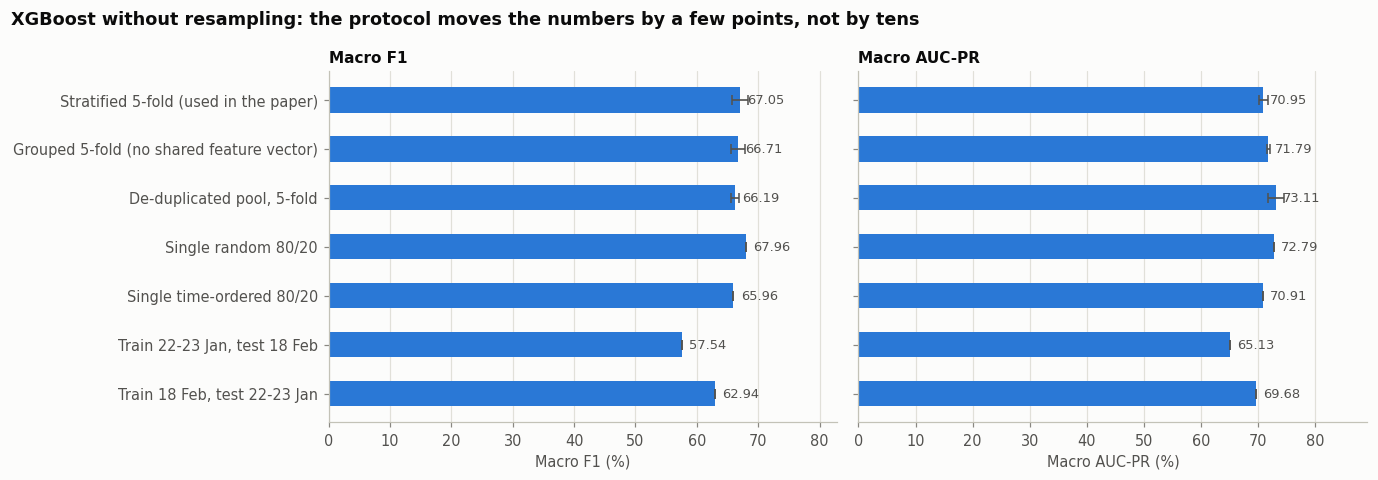

In [25]:
# 1.21  What each protocol changes (Table 5): one row per protocol, XGBoost and the other two trees
prot = pd.DataFrame(jsonl_rows(PROT_FILE)).drop_duplicates(subset=["tag", "model", "resampling"], keep="last")
prot["protocol"] = prot["tag"].str.replace(r"_f\d+$", "", regex=True)
base_rows = grid[grid.resampling == "none"].assign(protocol="stratified_5fold",
                                                   tag=lambda d: "strat_f" + d.fold.astype(str))
prot_all = pd.concat([prot, base_rows[prot.columns.intersection(base_rows.columns)]], ignore_index=True)

PROT_LABEL = {"stratified_5fold": "Stratified 5-fold (used in the paper)",
              "grouped": "Grouped 5-fold (no shared feature vector)",
              "dedup": "De-duplicated pool, 5-fold",
              "single_random": "Single random 80/20",
              "single_time": "Single time-ordered 80/20",
              "day_jan2feb": "Train 22-23 Jan, test 18 Feb",
              "day_feb2jan": "Train 18 Feb, test 22-23 Jan"}
PROT_ORDER = list(PROT_LABEL)
rows = []
for p in PROT_ORDER:
    for m in MODELS:
        g = prot_all[(prot_all.protocol == p) & (prot_all.model == m) & (prot_all.resampling == "none")]
        if not len(g):
            continue
        r = dict(Protocol=PROT_LABEL[p], Model=MODEL_LABEL[m], Folds=len(g),
                 Train=int(g.n_train.mean()) if "n_train" in g else np.nan)
        for met in METRICS:
            r[MET_LABEL[met]] = (f"{g[met].mean() * 100:.2f} ± {g[met].std(ddof=1) * 100:.2f}"
                                 if len(g) > 1 else f"{g[met].mean() * 100:.2f}")
        rows.append(r)
protocol_table = pd.DataFrame(rows)
print("UNSW-NB15 under every split protocol (mean ± std over folds where the protocol has folds, %):")
print(protocol_table.to_string(index=False))
protocol_table.to_csv(os.path.join(OUT, "table3b_protocol_comparison.csv"), index=False)

xgb_only = {p: prot_all[(prot_all.protocol == p) & (prot_all.model == "XGB") & (prot_all.resampling == "none")]
            for p in PROT_ORDER}
for p, g in xgb_only.items():
    if len(g):
        record(f"prot_{p}_acc", g.accuracy.mean() * 100)
        record(f"prot_{p}_f1", g.f1_macro.mean() * 100)
        record(f"prot_{p}_aucpr", g.auc_pr_macro.mean() * 100)
gs = xgb_only["grouped"].f1_macro.mean() * 100 - xgb_only["stratified_5fold"].f1_macro.mean() * 100
ts = xgb_only["single_time"].f1_macro.mean() * 100 - xgb_only["single_random"].f1_macro.mean() * 100
print(f"\nremoving every shared feature vector moves XGBoost macro F1 by {gs:+.2f} points;")
print(f"ordering the same-sized split by time moves it by {ts:+.2f} points.")
record("prot_grouped_minus_stratified_f1", gs); record("prot_time_minus_random_f1", ts)

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))
labels = [PROT_LABEL[p] for p in PROT_ORDER if len(xgb_only[p])]
ypos = np.arange(len(labels))[::-1]
for ax, met, name in zip(axes, ["f1_macro", "auc_pr_macro"], ["Macro F1", "Macro AUC-PR"]):
    vals = [xgb_only[p][met].mean() * 100 for p in PROT_ORDER if len(xgb_only[p])]
    errs = [xgb_only[p][met].std(ddof=1) * 100 if len(xgb_only[p]) > 1 else 0 for p in PROT_ORDER if len(xgb_only[p])]
    ax.barh(ypos, vals, xerr=errs, height=0.52, color=SERIES[0], error_kw=dict(ecolor=INK2, lw=1.1, capsize=3))
    for y_, v in zip(ypos, vals):
        ax.text(v + 1.2, y_, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(ypos); ax.set_yticklabels(labels if met == "f1_macro" else [""] * len(labels))
    ax.set_xlim(0, max(vals) * 1.22); value_axis(ax, "x")
    ax.set_xlabel(f"{name} (%)"); ax.set_title(name, fontsize=10)
fig.suptitle("XGBoost without resampling: the protocol moves the numbers by a few points, not by tens",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "unsw_protocol_comparison")

In [26]:
# 1.22  Which classes the protocol moves: per-class recall under every protocol
pc_rows = []
for p in PROT_ORDER:
    g = prot_all[(prot_all.protocol == p) & (prot_all.model == "XGB") & (prot_all.resampling == "none")]
    if not len(g):
        continue
    mean_rc = np.mean(np.vstack(g["recall_per_class"].tolist()), axis=0) * 100
    for i, c in enumerate(UNSW_CLASSES):
        pc_rows.append(dict(Protocol=PROT_LABEL[p], Class=c, recall=round(mean_rc[i], 2)))
pc_prot = pd.DataFrame(pc_rows).pivot(index="Class", columns="Protocol", values="recall")
pc_prot = pc_prot[[PROT_LABEL[p] for p in PROT_ORDER if PROT_LABEL[p] in pc_prot.columns]]
print("per-class recall (%), XGBoost without resampling, under every protocol:")
print(pc_prot.to_string())
pc_prot.to_csv(os.path.join(OUT, "unsw_per_class_recall_by_protocol.csv"))
spread = (pc_prot.max(axis=1) - pc_prot.min(axis=1)).sort_values(ascending=False)
print("\nrange across protocols, per class (percentage points):")
print(spread.round(2).to_string())
print(f"\nThe three largest classes move by at most "
      f"{spread[['Normal', 'Generic', 'Exploits']].max():.2f} points, while "
      f"{spread.index[0]} moves by {spread.iloc[0]:.2f}. Protocol choice is a minority-class question.")
record("prot_spread_max_class", spread.iloc[0])
record("prot_spread_big_classes", spread[["Normal", "Generic", "Exploits"]].max())

per-class recall (%), XGBoost without resampling, under every protocol:
Protocol        Stratified 5-fold (used in the paper)  Grouped 5-fold (no shared feature vector)  De-duplicated pool, 5-fold  Single random 80/20  Single time-ordered 80/20  Train 22-23 Jan, test 18 Feb  Train 18 Feb, test 22-23 Jan
Class                                                                                                                                                                                                                                   
Analysis                                        16.85                                      15.87                       16.73                20.75                      12.01                          6.79                          0.00
Backdoors                                       10.69                                      10.29                       13.14                 8.37                      11.66                          7.47                          5

In [27]:
# 1.23  The resampling comparison with ten folds, so the signed-rank test can resolve below 5% (Section 5.2)
# This is the most expensive cell added for the revision: 10 folds x 3 models x {none, SMOTE} = 60 fits.
# Set RUN_TENFOLD = False in 0.2 to skip it; the five-fold results in 1.11 and 1.12 do not depend on it.
TEN_FILE = os.path.join(OUT, "unsw_tenfold_folds.jsonl")
ten_done = {(r["tag"], r["model"], r["resampling"]) for r in jsonl_rows(TEN_FILE)}
if RUN_TENFOLD:
    _prot_file, _prot_done = PROT_FILE, prot_done
    PROT_FILE, prot_done = TEN_FILE, ten_done                 # reuse the runner, different checkpoint
    for f, (tr, va) in enumerate(StratifiedKFold(10, shuffle=True, random_state=SEED).split(X_all_raw, y_all)):
        run_protocol(f"ten_f{f}", X_all_raw, y_all, tr, va, MODELS, ["none", "smote"], n_classes)
    PROT_FILE, prot_done = _prot_file, _prot_done

ten = pd.DataFrame(jsonl_rows(TEN_FILE))
if len(ten):
    ten = ten.drop_duplicates(subset=["tag", "model", "resampling"], keep="last")
    ten["fold"] = ten["tag"].str.extract(r"(\d+)$").astype(int)
    ten_summary = (ten.groupby(["model", "resampling"])[METRICS].agg(["mean", "std"]) * 100).round(2)
    print(f"ten folds, {ten.fold.nunique()} distinct; signed-rank floor now "
          f"{wilcoxon_floor(ten.fold.nunique()):.5f}\n")
    print(ten_summary.to_string())
    ten_summary.to_csv(os.path.join(OUT, "unsw_tenfold_summary.csv"))

    ten_tests = pd.concat([paired_tests(ten[(ten.model == m) & (ten.resampling == "smote")],
                                        ten[(ten.model == m) & (ten.resampling == "none")],
                                        METRICS, m, "smote vs none") for m in MODELS], ignore_index=True)
    print("\nten folds, paired t-test and exact Wilcoxon signed-rank on the same differences:")
    print(ten_tests.to_string(index=False))
    ten_tests.to_csv(os.path.join(OUT, "unsw_tenfold_significance.csv"), index=False)
    both = int(((ten_tests.p_ttest < 0.05) & (ten_tests.p_wilcoxon < 0.05)).sum())
    t_only = int(((ten_tests.p_ttest < 0.05) & (ten_tests.p_wilcoxon >= 0.05)).sum())
    w_only = int(((ten_tests.p_ttest >= 0.05) & (ten_tests.p_wilcoxon < 0.05)).sum())
    print(f"\nof {len(ten_tests)} comparisons: {both} significant on both tests at 5%, "
          f"{t_only} on the t-test only, {w_only} on the signed-rank test only.")
    record("ten_both_significant", both); record("ten_ttest_only", t_only); record("ten_wilcoxon_only", w_only)
    for m in MODELS:
        r = ten_tests[(ten_tests["where"] == m) & (ten_tests["metric"] == "f1_macro")].iloc[0]
        record(f"ten_{m}_smote_f1_diff", r["diff_pp"]); record(f"ten_{m}_smote_f1_p_wilcoxon", r["p_wilcoxon"])

ten folds, 10 distinct; signed-rank floor now 0.00195

                 accuracy       precision_macro       recall_macro       f1_macro       auc_pr_macro      
                     mean   std            mean   std         mean   std     mean   std         mean   std
model resampling                                                                                          
LGB   none          84.22  2.42           60.09  4.33        58.40  2.71    57.65  2.99        50.95  6.17
      smote         88.55  0.13           76.45  2.27        65.58  1.15    66.20  1.32        71.01  1.87
RF    none          87.47  0.16           79.23  1.29        62.26  1.15    65.06  1.24        69.14  1.47
      smote         87.43  0.15           72.00  1.07        65.44  1.42    66.29  0.89        67.87  1.25
XGB   none          88.41  0.15           80.27  1.72        64.09  0.97    66.27  1.13        71.09  1.50
      smote         88.35  0.15           73.75  2.24        65.12  1.81    66.31  1.51  

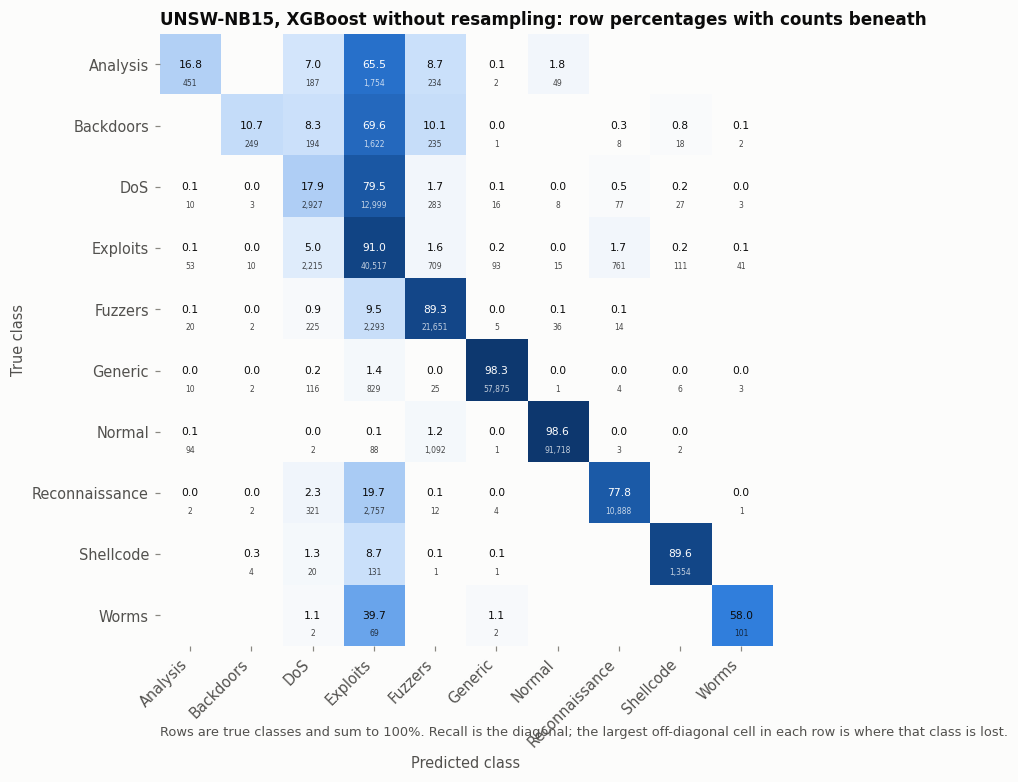

         Class  Support  Correct  Recall_pct  Precision_pct Most_errors_go_to  Errors_to_it
      Analysis     2677      451       16.85          70.47          Exploits          1754
     Backdoors     2329      249       10.69          91.54          Exploits          1622
           DoS    16353     2927       17.90          47.14          Exploits         12999
      Exploits    44525    40517       91.00          64.25               DoS          2215
       Fuzzers    24246    21651       89.30          89.31          Exploits          2293
       Generic    58871    57875       98.31          99.78          Exploits           829
        Normal    93000    91718       98.62          99.88           Fuzzers          1092
Reconnaissance    13987    10888       77.84          92.62          Exploits          2757
     Shellcode     1511     1354       89.61          89.20          Exploits           131
         Worms      174      101       58.05          66.89          Exploits   

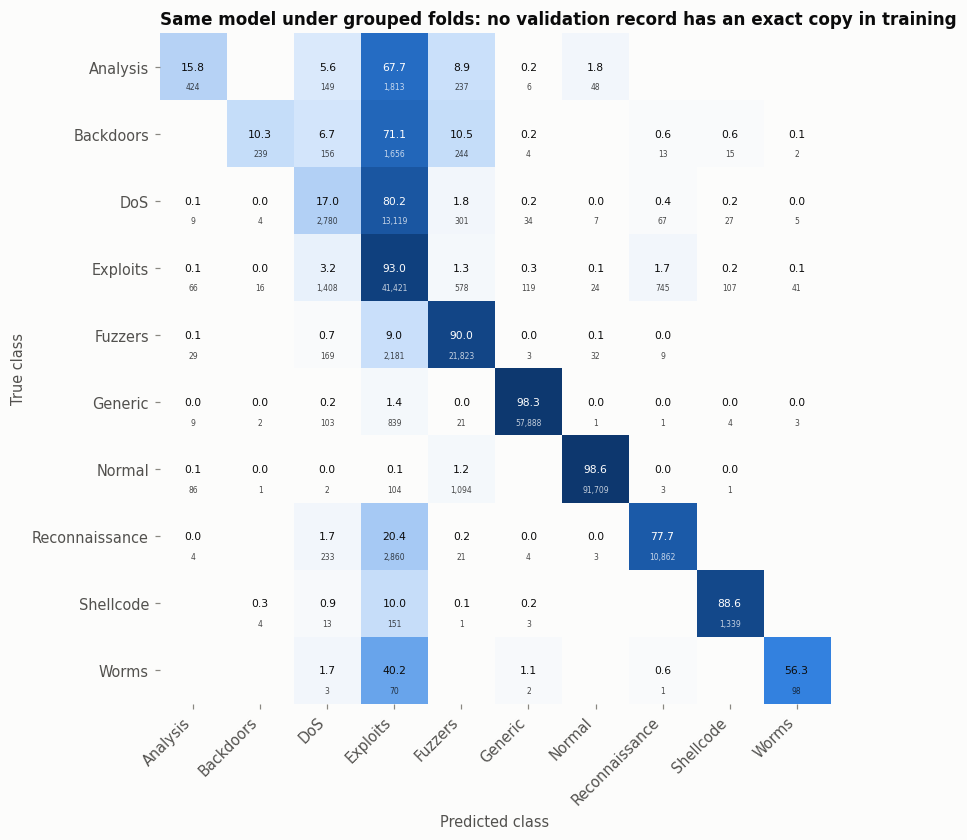


change in per-class recall when every shared feature vector is separated (points):
Analysis         -1.01
Backdoors        -0.43
DoS              -0.90
Exploits          2.03
Fuzzers           0.71
Generic           0.02
Normal           -0.01
Reconnaissance   -0.19
Shellcode        -0.99
Worms            -1.72


In [28]:
# 1.24  The confusion matrix the paper prints (Figure 1): XGBoost, no resampling, five folds pooled
cm_xgb = np.sum(np.array(grid[(grid.model == "XGB") & (grid.resampling == "none")]["cm"].tolist()), axis=0)
plot_confusion_pct(cm_xgb, UNSW_CLASSES,
                   "UNSW-NB15, XGBoost without resampling: row percentages with counts beneath",
                   "fig1_unsw_confusion_xgb_none",
                   note="Rows are true classes and sum to 100%. Recall is the diagonal; "
                        "the largest off-diagonal cell in each row is where that class is lost.")
summ_cm = confusion_summary(cm_xgb, UNSW_CLASSES)
print(summ_cm.to_string(index=False))
summ_cm.to_csv(os.path.join(OUT, "unsw_confusion_summary_xgb_none.csv"), index=False)
share = cm_xgb / cm_xgb.sum(1, keepdims=True) * 100
for c in ["Analysis", "Backdoors", "DoS"]:
    i = UNSW_CLASSES.index(c); j = int(np.argmax(np.where(np.arange(n_classes) == i, -1, cm_xgb[i])))
    print(f"{c}: recall {share[i, i]:.2f}%, and {share[i, j]:.2f}% of it is predicted {UNSW_CLASSES[j]}")

# the same matrix under the leakage-controlled protocol, for the reader who wants to see both
gp = prot_all[(prot_all.protocol == "grouped") & (prot_all.model == "XGB") & (prot_all.resampling == "none")]
if len(gp):
    cm_gp = np.sum(np.array(gp["cm"].tolist()), axis=0)
    plot_confusion_pct(cm_gp, UNSW_CLASSES,
                       "Same model under grouped folds: no validation record has an exact copy in training",
                       "unsw_confusion_xgb_grouped")
    d = (np.diag(cm_gp) / cm_gp.sum(1) - np.diag(cm_xgb) / cm_xgb.sum(1)) * 100
    print("\nchange in per-class recall when every shared feature vector is separated (points):")
    print(pd.Series(d.round(2), index=UNSW_CLASSES).to_string())

## What the model uses, and whether more data would help (paper Section 5.6)

Two questions a reader asks about any result like this. Which features carry the decision, and would a
bigger training set close the gap on the minority classes? SHAP answers the first on the model that is
actually reported, and a learning curve answers the second by refitting on subsets of the same fold.

explained model: fold 0, accuracy 88.41%, macro F1 67.60%
SHAP values (6047, 43, 10) for 6,047 records in 36s

global importance, mean |SHAP| over records and class outputs:
       feature  mean_abs_shap   xgb_gain  cum_share_pct
        dsport       1.245193  30.482735      18.299999
          sttl       1.021174 631.572021      33.310001
        sbytes       0.537840  81.590294      41.209999
         sport       0.496725  18.577599      48.520000
       smeansz       0.328759  16.670424      53.349998
    ct_srv_dst       0.243805  30.127234      56.930000
ct_dst_src_ltm       0.213710   6.079935      60.070000
    ct_srv_src       0.198493   2.861039      62.990002
       service       0.195480  18.054012      65.860001
       dmeansz       0.167851  59.827728      68.330002
         Dload       0.153049   1.627328      70.580002
        dbytes       0.146875   6.889845      72.739998
         Sload       0.136179   3.217666      74.739998
         sloss       0.117604   7.573450  

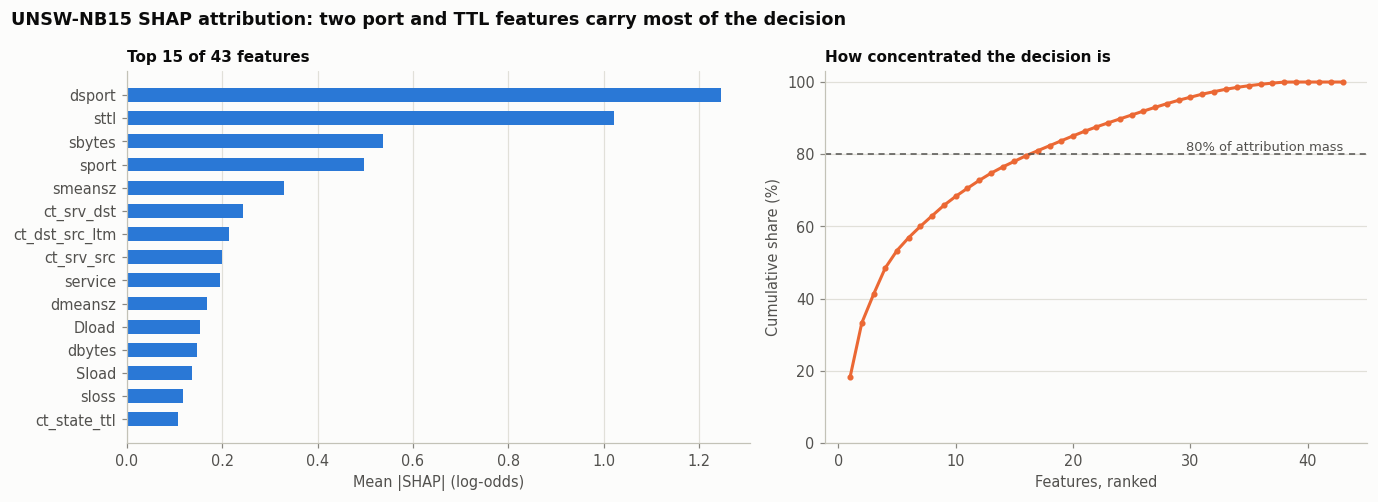

In [29]:
# 1.25  SHAP attribution for the reference model: XGBoost, fold 0, no resampling (Figure 2 left, Section 5.6)
if RUN_XAI:
    try:
        import shap
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
        import shap
    tr0, va0 = splits[0]
    Xtr0, Xva0, names0, _, _ = preprocess_fold(X_all_raw.iloc[tr0], X_all_raw.iloc[va0])
    ref = get_model("XGB"); ref.fit(Xtr0, y_all[tr0])
    pred0 = np.argmax(ref.predict_proba(Xva0), axis=1)
    print(f"explained model: fold 0, accuracy {accuracy_score(y_all[va0], pred0) * 100:.2f}%, "
          f"macro F1 {f1_score(y_all[va0], pred0, average='macro') * 100:.2f}%")

    rng = np.random.default_rng(SEED)          # stratified sample, at least 50 records per class
    idx = np.sort(np.concatenate([
        rng.choice(np.where(y_all[va0] == c)[0],
                   size=min(int((y_all[va0] == c).sum()),
                            max(50, int(round(6000 * (y_all[va0] == c).sum() / len(va0))))),
                   replace=False)
        for c in range(n_classes)]))
    Xs, ys = Xva0[idx], y_all[va0][idx]
    t0 = time.time()
    sv = np.asarray(shap.TreeExplainer(ref).shap_values(Xs))
    if sv.ndim == 3 and sv.shape[1] != len(names0):        # older layout (classes, records, features)
        sv = np.transpose(sv, (1, 2, 0))
    print(f"SHAP values {sv.shape} for {len(idx):,} records in {time.time() - t0:.0f}s")

    gain = ref.get_booster().get_score(importance_type="gain")
    shap_imp = pd.DataFrame({"feature": names0, "mean_abs_shap": np.abs(sv).mean(axis=(0, 2)),
                             "xgb_gain": [gain.get(f"f{i}", 0.0) for i in range(len(names0))]})
    shap_imp = shap_imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    shap_imp["cum_share_pct"] = (shap_imp.mean_abs_shap.cumsum() / shap_imp.mean_abs_shap.sum() * 100).round(2)
    shap_imp.to_csv(os.path.join(OUT, "unsw_shap_global.csv"), index=False)
    print("\nglobal importance, mean |SHAP| over records and class outputs:")
    print(shap_imp.head(15).to_string(index=False))
    rho, p_rho = stats.spearmanr(shap_imp.mean_abs_shap, shap_imp.xgb_gain)
    print(f"\nSpearman(mean |SHAP|, XGBoost split gain) = {rho:.3f} (p = {p_rho:.2g}): two importance "
          f"measures on the same\nfitted model agree only moderately, which is why the paper quotes SHAP "
          f"and not gain.")
    for k in (5, 10, 15, 20):
        print(f"  top {k:>2} of {len(names0)} features hold {shap_imp.cum_share_pct.iloc[k - 1]:.1f}% "
              f"of the attribution mass")

    per_cls_shap = pd.DataFrame(np.abs(sv).mean(axis=0), index=names0, columns=UNSW_CLASSES)
    per_cls_shap.to_csv(os.path.join(OUT, "unsw_shap_per_class.csv"))
    print("\ntop 5 features per class, by mean |SHAP| for that class's output:")
    for c in UNSW_CLASSES:
        top = per_cls_shap[c].sort_values(ascending=False).head(5)
        print(f"  {c:<15}" + ", ".join(f"{f} {v:.3f}" for f, v in top.items()))
    for c in UNSW_CLASSES:
        record(f"shap_top_feature_is_port_{c}",
               1.0 if per_cls_shap[c].idxmax() in ("sport", "dsport") else 0.0)
    for i, r in shap_imp.head(5).iterrows():
        record(f"shap_rank{i + 1}_share_pct", r["mean_abs_shap"] / shap_imp.mean_abs_shap.sum() * 100)
    record("shap_top5_share_pct", shap_imp.cum_share_pct.iloc[4])
    record("shap_top10_share_pct", shap_imp.cum_share_pct.iloc[9])
    record("shap_gain_spearman", rho)

    if os.path.exists(GA_FILE):                 # wrapper selection against attribution
        sel = set(json.load(open(GA_FILE))["selected"])
        topk = set(shap_imp.feature.head(len(sel)))
        print(f"\nGA subset ({len(sel)} features) against the SHAP top {len(sel)}: "
              f"{len(sel & topk)} shared, Jaccard {len(sel & topk) / len(sel | topk):.2f}")
        print("  chosen by the GA only :", sorted(sel - topk))
        print("  ranked by SHAP only   :", sorted(topk - sel))
        record("ga_shap_jaccard", len(sel & topk) / len(sel | topk))

    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6), gridspec_kw=dict(width_ratios=[1.15, 1]))
    top15 = shap_imp.head(15).iloc[::-1]
    axes[0].barh(np.arange(15), top15.mean_abs_shap.values, height=0.6, color=SERIES[0])
    axes[0].set_yticks(np.arange(15)); axes[0].set_yticklabels(top15.feature.values)
    axes[0].set_xlabel("Mean |SHAP| (log-odds)"); value_axis(axes[0], "x")
    axes[0].set_title("Top 15 of 43 features", fontsize=10)
    axes[1].plot(np.arange(1, len(shap_imp) + 1), shap_imp.cum_share_pct.values, color=SERIES[1], marker="o",
                 markersize=3)
    axes[1].axhline(80, color=INK2, lw=1, ls=(0, (4, 3)))
    axes[1].text(len(shap_imp), 81, "80% of attribution mass", ha="right", fontsize=8.5, color=INK2)
    axes[1].set_xlabel("Features, ranked"); axes[1].set_ylabel("Cumulative share (%)")
    axes[1].set_ylim(0, 103); value_axis(axes[1])
    axes[1].set_title("How concentrated the decision is", fontsize=10)
    fig.suptitle("UNSW-NB15 SHAP attribution: two port and TTL features carry most of the decision",
                 x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "fig2_left_unsw_shap_importance")

 fraction  n_train model  train_f1_macro  val_f1_macro  val_accuracy  recall_Analysis  recall_Backdoors  recall_DoS  recall_Exploits
     0.02     4123   XGB           95.04         54.94         85.82             6.90              2.15       30.80            76.81
     0.02     4123    RF           95.00         53.38         85.86             9.14              1.50       28.62            77.94
     0.05    10307   XGB           90.34         59.04         86.25            10.07              6.65       30.70            77.42
     0.05    10307    RF           90.49         57.00         86.21             8.77              5.36       30.21            77.53
     0.10    20614   XGB           84.76         61.36         87.02            11.94              7.94       28.32            81.57
     0.10    20614    RF           85.86         57.85         86.55            14.74              7.08       30.06            78.88
     0.20    41228   XGB           81.92         66.16         87.34 

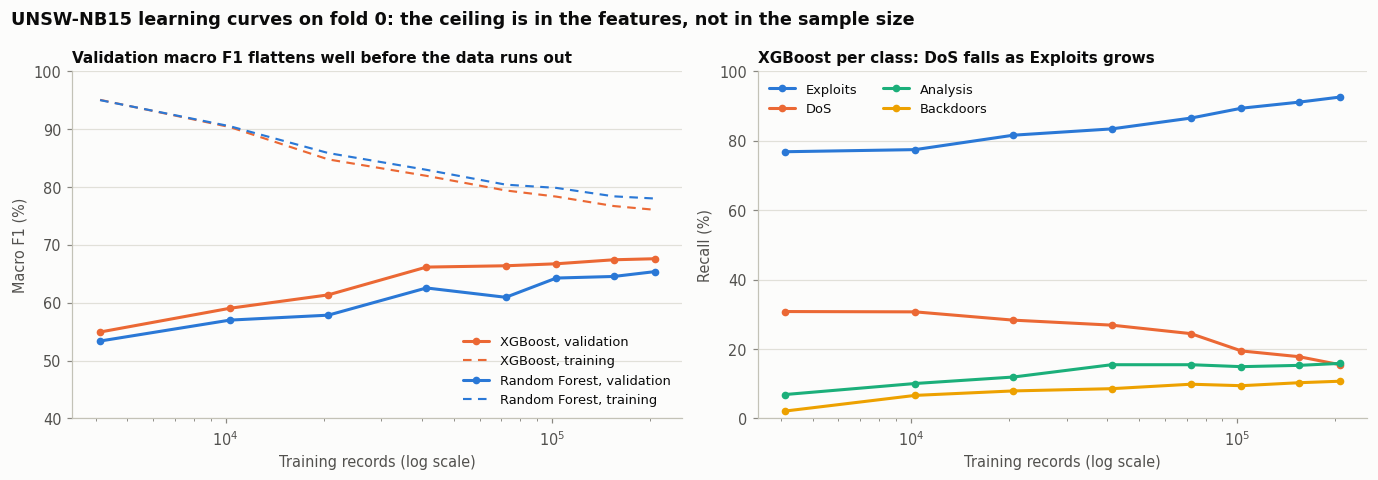

In [30]:
# 1.26  Learning curves: would more training data help? (Figure 2 right, Section 5.6)
if RUN_XAI:
    FRACTIONS = [0.02, 0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.00]
    LC_FILE = os.path.join(OUT, "unsw_learning_curve.csv")
    if os.path.exists(LC_FILE):
        lc = pd.read_csv(LC_FILE)
    else:
        rows = []
        for frac in FRACTIONS:
            sub = (np.arange(len(tr0)) if frac == 1.0 else
                   np.sort(np.concatenate([                       # stratified subsample of the training fold
                       np.random.default_rng(SEED).choice(np.where(y_all[tr0] == c)[0],
                                                          size=max(2, int(round((y_all[tr0] == c).sum() * frac))),
                                                          replace=False)
                       for c in range(n_classes)])))
            for m in ["XGB", "RF"]:
                t0 = time.time(); c2 = get_model(m); c2.fit(Xtr0[sub], y_all[tr0][sub])
                pv = np.argmax(c2.predict_proba(Xva0), axis=1)
                pt = np.argmax(c2.predict_proba(Xtr0[sub]), axis=1)
                r = dict(fraction=frac, n_train=int(len(sub)), model=m,
                         val_accuracy=accuracy_score(y_all[va0], pv) * 100,
                         val_f1_macro=f1_score(y_all[va0], pv, average="macro", zero_division=0) * 100,
                         train_f1_macro=f1_score(y_all[tr0][sub], pt, average="macro", zero_division=0) * 100,
                         fit_seconds=round(time.time() - t0, 1))
                rc = recall_score(y_all[va0], pv, average=None, labels=list(range(n_classes)), zero_division=0) * 100
                r.update({f"recall_{c}": rc[i] for i, c in enumerate(UNSW_CLASSES)})
                rows.append(r); print(f"  {frac:>5.2f} n={len(sub):>7,} {m:<4}val F1 {r['val_f1_macro']:.2f} "
                                      f"train F1 {r['train_f1_macro']:.2f} ({r['fit_seconds']}s)")
        lc = pd.DataFrame(rows); lc.to_csv(LC_FILE, index=False)

    print(lc[["fraction", "n_train", "model", "train_f1_macro", "val_f1_macro", "val_accuracy",
              "recall_Analysis", "recall_Backdoors", "recall_DoS", "recall_Exploits"]].round(2).to_string(index=False))
    x1 = lc[lc.model == "XGB"]
    half = x1[x1.fraction == 0.35].val_f1_macro.iloc[0]; full = x1[x1.fraction == 1.0].val_f1_macro.iloc[0]
    print(f"\nXGBoost gains {full - half:+.2f} macro F1 points between 35% and 100% of the training fold, "
          f"so the curve is flat\nwhere a data-hungry model would still be climbing. DoS recall "
          f"{x1[x1.fraction == 0.02].recall_DoS.iloc[0]:.2f}% -> {x1[x1.fraction == 1.0].recall_DoS.iloc[0]:.2f}% "
          f"as data grows: more Exploits\nrecords make the Exploits attractor stronger, not weaker.")
    record("lc_gain_35_to_100_f1", full - half)
    record("lc_dos_recall_2pct", x1[x1.fraction == 0.02].recall_DoS.iloc[0])
    record("lc_dos_recall_full", x1[x1.fraction == 1.0].recall_DoS.iloc[0])

    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))
    for m, c in [("XGB", SERIES[1]), ("RF", SERIES[0])]:
        g = lc[lc.model == m].sort_values("n_train")
        axes[0].plot(g.n_train, g.val_f1_macro, color=c, marker="o", markersize=4, label=f"{MODEL_LABEL[m]}, validation")
        axes[0].plot(g.n_train, g.train_f1_macro, color=c, marker="", ls=(0, (4, 3)), lw=1.4,
                     label=f"{MODEL_LABEL[m]}, training")
    axes[0].set_xscale("log"); axes[0].set_xlabel("Training records (log scale)")
    axes[0].set_ylabel("Macro F1 (%)"); axes[0].set_ylim(40, 100); value_axis(axes[0])
    axes[0].legend(loc="lower right", fontsize=8.5)
    axes[0].set_title("Validation macro F1 flattens well before the data runs out", fontsize=10)
    g = lc[lc.model == "XGB"].sort_values("n_train")
    for i, c in enumerate(["Exploits", "DoS", "Analysis", "Backdoors"]):
        axes[1].plot(g.n_train, g[f"recall_{c}"], color=SERIES[i], marker="o", markersize=4, label=c)
    axes[1].set_xscale("log"); axes[1].set_xlabel("Training records (log scale)")
    axes[1].set_ylabel("Recall (%)"); axes[1].set_ylim(0, 100); value_axis(axes[1])
    axes[1].legend(ncol=2, fontsize=8.5, loc="upper left")
    axes[1].set_title("XGBoost per class: DoS falls as Exploits grows", fontsize=10)
    fig.suptitle("UNSW-NB15 learning curves on fold 0: the ceiling is in the features, not in the sample size",
                 x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "fig2_right_unsw_learning_curve")

In [31]:
# 1.27  Free Part 1 memory before loading CICIDS-2017 (all tables and results above stay available)
for _v in ["df", "grp", "tab", "row_hash", "X_all_raw", "keep", "sub", "X_dd", "Xtr0", "Xva0", "sv", "Xs"]:
    globals().pop(_v, None)
gc.collect()
print("Part 1 finished.")

Part 1 finished.


---
# Part 2. CICIDS-2017 on its own (paper Sections 3.2 and 6)

The CICFlowMeter release has two known quirks: column names carry leading spaces, and the Web Attack
labels contain a Windows-1252 byte, so the files are read as `latin1`. Rows with infinite or missing flow
rates are removed, then the duplicate audit of cell 0.2 runs - the same function used on UNSW-NB15 - and
the copies it finds are set aside rather than deleted, so 2.4 can train without them and 2.5 with them.
The fifteen labels are consolidated into seven classes; `DDoS` is matched before `DoS` because the string
`DDOS` contains `DOS`. Heartbleed (11 records) and Infiltration (36) are dropped rather than merged into a
neighbouring class. The release carries one file per capture session and no timestamp column, which is
what cell 2.6 works with when it asks whether this corpus can be split by time.

loaded 2,830,743 rows from 8 files
   Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
   Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   Friday-WorkingHours-Morning.pcap_ISCX.csv
   Monday-WorkingHours.pcap_ISCX.csv
   Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   Tuesday-WorkingHours.pcap_ISCX.csv
   Wednesday-workingHours.pcap_ISCX.csv
columns in the release: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT 

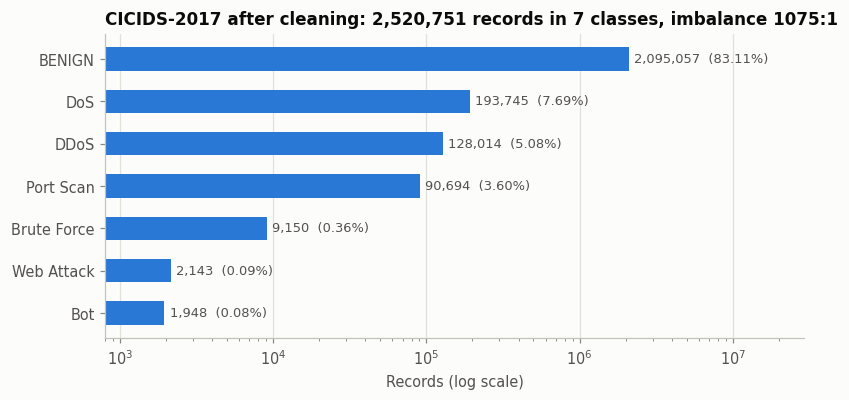

In [32]:
# 2.1  Load, clean and consolidate to 7 classes (Table 1, right)
if RUN_CICIDS or RUN_MERGED:
    zip_path = os.path.join(NIDS_DIR, "MachineLearningCSV.zip")
    local = os.path.join(WORK, "MachineLearningCSV.zip")
    if not os.path.exists(local):
        import shutil
        shutil.copy(zip_path, local)                  # local copy is much faster to read than Drive
    csv_dir = os.path.join(WORK, "cicids")
    if not glob.glob(csv_dir + "/**/*.csv", recursive=True):
        os.makedirs(csv_dir, exist_ok=True)
        with zipfile.ZipFile(local) as z:
            z.extractall(csv_dir)
    files = sorted(glob.glob(csv_dir + "/**/*.csv", recursive=True))
    frames = []
    for f in files:
        d = pd.read_csv(f, encoding="latin1", low_memory=False)
        d.columns = [c.strip() for c in d.columns]
        d["src_file"] = os.path.basename(f)            # the release has one file per capture session
        frames.append(d)
    cic = pd.concat(frames, ignore_index=True); del frames
    n_loaded = len(cic)
    print(f"loaded {n_loaded:,} rows from {len(files)} files")
    for f in files:
        print("  ", os.path.basename(f))
    print("columns in the release:", [c for c in cic.columns if c != "src_file"])
    TIME_COLS = [c for c in cic.columns if "time" in c.lower() or "date" in c.lower()]
    print("columns carrying a wall-clock time:", TIME_COLS or "none - this release has no timestamp column,"
          " so the capture session in src_file is the only time information available")
    if "Fwd Header Length.1" in cic.columns:           # a duplicated column in the release
        cic = cic.drop(columns=["Fwd Header Length.1"])
    num = cic.select_dtypes(include=[np.number]).columns
    cic[num] = cic[num].replace([np.inf, -np.inf], np.nan)
    n_bad = int(cic[num].isna().any(axis=1).sum()); cic = cic.dropna(subset=num)
    n_after_bad = len(cic)
    cic = cic.reset_index(drop=True)

    # Same audit function as UNSW-NB15 (0.2), on this corpus's own released label, and nothing is
    # dropped yet: cell 2.4 trains on the de-duplicated pool and 2.5 trains on the same pool with the
    # copies left in, so the effect of the decision is measured instead of assumed.
    CIC_FEATS = [c for c in cic.columns if c not in ("Label", "src_file")]
    dup_cic, cic_keep, cic_hash = duplicate_audit(cic[CIC_FEATS], cic["Label"].values, "CICIDS-2017")
    n_dup = dup_cic["removed_as_copies"]
    print(f"\ndropped {n_bad:,} rows with infinite or missing values before the audit; "
          f"{n_dup:,} rows ({n_dup / n_after_bad * 100:.2f}%) are exact copies of an earlier row")
    cic["_dup_keep"] = cic_keep

    def to7(lbl):
        s = str(lbl).strip().upper()
        if s == "BENIGN": return "BENIGN"
        if "BOT" in s: return "Bot"
        if "PATATOR" in s: return "Brute Force"
        if "DDOS" in s: return "DDoS"
        if "DOS" in s: return "DoS"
        if "PORTSCAN" in s or "PORT SCAN" in s: return "Port Scan"
        if "WEB ATTACK" in s: return "Web Attack"
        return None
    print("\noriginal labels and the class each one goes to:")
    lab_map = cic["Label"].value_counts().rename("records").to_frame()
    lab_map["7-class"] = [to7(l) or "dropped" for l in lab_map.index]
    print(lab_map.to_string())
    cic["Cat"] = cic["Label"].apply(to7)
    dropped = cic.loc[cic["Cat"].isna(), "Label"].value_counts()
    print("\ndropped labels:", dropped.to_dict())
    cic = cic[cic["Cat"].notna()].reset_index(drop=True)

    # which class appears in which capture session: this decides whether a per-day split is possible (2.6)
    day_cic = pd.crosstab(cic["src_file"], cic["Cat"])
    print("\nrecords per capture session and 7-class category:")
    print(day_cic.to_string())
    day_cic.to_csv(os.path.join(OUT, "cicids_day_composition.csv"))
    per_day = (day_cic > 0).sum(axis=0)
    print("\ncapture sessions each class appears in:", per_day.to_dict())
    print("classes confined to a single session:", sorted(per_day[per_day == 1].index.tolist()))

    # the pool every CICIDS-2017 result in the paper uses: one record per (feature vector, label) pair.
    # The copies are set aside rather than thrown away, so 2.5 can train on the pool that keeps them.
    cic_keep = cic.pop("_dup_keep").values
    cic_dups = cic[~cic_keep].reset_index(drop=True)
    cic = cic[cic_keep].reset_index(drop=True)
    print(f"\nde-duplicated pool used from here on: {len(cic):,} records; "
          f"{len(cic_dups):,} copies kept aside for the control in 2.5")
    vc_c = cic["Cat"].value_counts()
    table1_cic = pd.DataFrame({"Records": vc_c, "%": (vc_c / len(cic) * 100).round(2)})
    print(table1_cic.to_string()); print(f"Total {len(cic):,}")
    imb_cic = vc_c.max() / vc_c.min()
    print(f"imbalance ratio (largest : smallest) = {imb_cic:.0f}:1  ({vc_c.idxmax()} : {vc_c.idxmin()})")
    table1_cic.to_csv(os.path.join(OUT, "table1_cicids_distribution.csv"))

    CIC_LE, CIC_CLASSES = make_encoder(sorted(cic["Cat"].unique()))
    y_cic = CIC_LE.transform(cic["Cat"].values)
    CIC_X_COLS = [c for c in cic.columns if c not in ("Label", "Cat", "src_file")]
    X_cic = cic[CIC_X_COLS].astype(np.float64).values
    print("X_cic", X_cic.shape, "| classes in encoded order:", CIC_CLASSES)
    record("cic_distinct_vectors", dup_cic["distinct_vectors"])
    record("cic_distinct_vector_label_pairs", dup_cic["distinct_vector_label_pairs"])
    record("cic_conflicted_vectors", dup_cic["conflicted_vectors"])
    record("cic_conflict_records", dup_cic["records_on_conflicted_vectors"])
    record("cic_n_sessions", int(cic["src_file"].nunique()))
    record("cic_classes_in_one_session", int((per_day == 1).sum()))

    record("cic_loaded_rows", n_loaded); record("cic_n_files", len(files)); record("cic_bad_rows", n_bad)
    record("cic_duplicates", n_dup); record("cic_duplicates_pct", n_dup / n_after_bad * 100)
    for lbl, n in dropped.items():
        key = "cic_dropped_heartbleed" if "HEARTBLEED" in str(lbl).upper() else (
              "cic_dropped_infiltration" if "INFILTRATION" in str(lbl).upper() else None)
        if key:
            record(key, n)
    record("cic_total", len(cic)); record("cic_imbalance_ratio", round(imb_cic)); record("cic_n_features", X_cic.shape[1])
    for c in vc_c.index:
        record(f"cic_count_{c}", vc_c[c]); record(f"cic_pct_{c}", vc_c[c] / len(cic) * 100)

    fig, ax = plt.subplots(figsize=(8.2, 3.6))
    order = vc_c.sort_values().index
    ax.barh(order, vc_c[order].values, height=0.55, color=SERIES[0])
    ax.set_xscale("log"); value_axis(ax, "x")
    for i, c in enumerate(order):
        ax.text(vc_c[c] * 1.08, i, f"{vc_c[c]:,}  ({vc_c[c] / len(cic) * 100:.2f}%)", va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(800, vc_c.max() * 14)
    ax.set_xlabel("Records (log scale)")
    ax.set_title(f"CICIDS-2017 after cleaning: {len(cic):,} records in 7 classes, imbalance {imb_cic:.0f}:1")
    save_fig(fig, "cicids_class_distribution")

In [33]:
# 2.2  Shared cross-validation routine for Parts 2 and 3 (XGBoost, 200 trees, depth 6, learning rate 0.3)
def cv_evaluate(X, y, class_names, use_smote, smote_cap, tag, ckpt, src=None):
    '''Five stratified folds of XGBoost with fold-local scaling. If src is given (the corpus each
    record came from), per-class recall is also stored separately for each source, which is what the
    per-source breakdown in 3.4 reads. That costs no extra fits, but it is only written while a fold
    is actually computed, so a checkpoint from an earlier run does not contain it.'''
    rows = [r for r in jsonl_rows(ckpt) if r["tag"] == tag]
    have_f = {r["fold"] for r in rows}
    if len(have_f) == 5:
        print(f"  [{tag}] all 5 folds loaded from {os.path.basename(ckpt)}")
    for fold, (tr, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y)):
        if fold in have_f:
            continue
        t0 = time.time()
        sc = MinMaxScaler().fit(X[tr])
        Xtr, Xva, ytr, yva = sc.transform(X[tr]), sc.transform(X[va]), y[tr], y[va]
        if use_smote:
            cnt = pd.Series(ytr).value_counts()
            strat = {k: smote_cap for k in cnt.index if cnt[k] < smote_cap}
            if strat:
                Xtr, ytr = SMOTE(sampling_strategy=strat, random_state=SEED,
                                 k_neighbors=5).fit_resample(Xtr, ytr)
        clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method="hist",
                                random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
        clf.fit(Xtr, ytr)
        pred, proba = clf.predict(Xva), clf.predict_proba(Xva)
        p, r, f1, _ = precision_recall_fscore_support(yva, pred, average="macro", zero_division=0)
        yb = label_binarize(yva, classes=list(range(len(class_names))))
        row = dict(tag=tag, fold=fold, accuracy=accuracy_score(yva, pred), precision=p, recall=r, f1=f1,
                   aucpr=average_precision_score(yb, proba, average="macro"),
                   recall_per_class=recall_score(yva, pred, average=None,
                                                 labels=list(range(len(class_names))), zero_division=0).tolist(),
                   cm=confusion_matrix(yva, pred, labels=list(range(len(class_names)))).tolist(),
                   n_train=int(len(ytr)))
        if src is not None:
            lab = list(range(len(class_names)))
            row["recall_by_source"] = {
                str(s): recall_score(yva[src[va] == s], pred[src[va] == s], average=None,
                                     labels=lab, zero_division=0).tolist() for s in np.unique(src)}
            row["support_by_source"] = {
                str(s): np.bincount(yva[src[va] == s], minlength=len(class_names)).tolist()
                for s in np.unique(src)}
        jsonl_append(ckpt, row); rows.append(row)
        print(f"  [{tag}] fold {fold}: acc={row['accuracy']*100:.2f} F1_M={f1*100:.2f} "
              f"AUC-PR_M={row['aucpr']*100:.2f} ({time.time()-t0:.0f}s, {len(ytr):,} training rows)")
    out = pd.DataFrame(sorted(rows, key=lambda r: r["fold"])).drop_duplicates(subset=["fold"])
    return out

CV_METRICS = ["accuracy", "precision", "recall", "f1", "aucpr"]
CV_LABEL = {"accuracy": "Accuracy", "precision": "Macro precision", "recall": "Macro recall",
            "f1": "Macro F1", "aucpr": "Macro AUC-PR"}

def cv_table(res_by_label):
    '''mean ± std over folds for each condition'''
    return pd.DataFrame({lab: [f"{r[m].mean()*100:.2f} ± {r[m].std()*100:.2f}" for m in CV_METRICS]
                         for lab, r in res_by_label.items()}, index=[CV_LABEL[m] for m in CV_METRICS])

def per_class_recall(res_by_label, class_names):
    return pd.DataFrame({lab: np.mean(np.vstack(r["recall_per_class"].tolist()), 0) * 100
                         for lab, r in res_by_label.items()}, index=class_names)

print("cv_evaluate() ready")

cv_evaluate() ready


undersampled to 1,948 records per class | train 9,545 | test 4,091 (70/30)

Table 6 (top). Balanced single split (%):
               accuracy  precision  recall     f1
Random Forest     99.32      99.32   99.32  99.32
XGBoost           99.68      99.68   99.68  99.68
LightGBM          99.71      99.71   99.71  99.71

per-class recall on the balanced test set (%):
             Random Forest  XGBoost  LightGBM
BENIGN               98.46    99.32     99.66
Bot                  99.66    99.66     99.66
Brute Force          99.49   100.00    100.00
DDoS                 99.66    99.66     99.66
DoS                  98.97    99.66     99.66
Port Scan            99.49    99.66     99.66
Web Attack           99.49    99.83     99.66


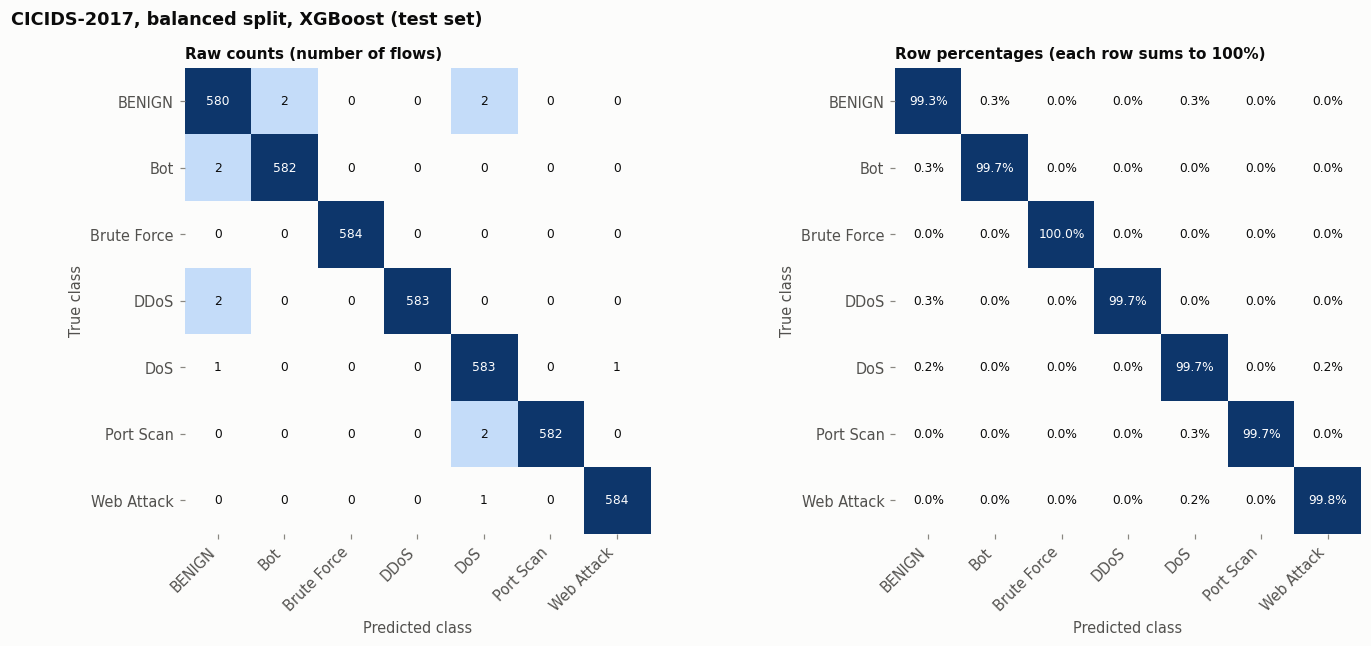

In [34]:
# 2.3  Table 6 (top): class-balanced single split by undersampling, no synthetic records (Section 6.1)
if RUN_CICIDS:
    per = int(pd.Series(y_cic).value_counts().min())
    rng = np.random.RandomState(SEED)
    keep = np.concatenate([rng.choice(np.where(y_cic == k)[0], size=per, replace=False)
                           for k in range(len(CIC_CLASSES))])
    Xtr, Xte, ytr, yte = train_test_split(X_cic[keep], y_cic[keep], test_size=0.30,
                                          stratify=y_cic[keep], random_state=SEED)
    sc = MinMaxScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    print(f"undersampled to {per:,} records per class | train {len(ytr):,} | test {len(yte):,} (70/30)")
    bal, bal_recall, bal_cm = {}, {}, {}
    for name, clf in [("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
                      ("XGBoost", xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3,
                                                    tree_method="hist", random_state=SEED, n_jobs=-1,
                                                    eval_metric="mlogloss")),
                      ("LightGBM", lgb.LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.3,
                                                      random_state=SEED, n_jobs=-1, verbose=-1))]:
        clf.fit(Xtr_s, ytr); pred = clf.predict(Xte_s)
        p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
        bal[name] = dict(accuracy=accuracy_score(yte, pred), precision=p, recall=r, f1=f1)
        bal_recall[name] = recall_score(yte, pred, average=None, labels=list(range(len(CIC_CLASSES))), zero_division=0) * 100
        bal_cm[name] = confusion_matrix(yte, pred, labels=list(range(len(CIC_CLASSES))))
        for m, v in bal[name].items():
            record(f"cic_bal_{name}_{m}", v * 100)
        for c, v in zip(CIC_CLASSES, bal_recall[name]):
            record(f"cic_bal_recall_{name}_{c}", v)
    bal_tab = pd.DataFrame(bal).T.mul(100).round(2)
    print("\nTable 6 (top). Balanced single split (%):")
    print(bal_tab.to_string())
    bal_tab.to_csv(os.path.join(OUT, "cicids_balanced.csv"))
    print("\nper-class recall on the balanced test set (%):")
    print(pd.DataFrame(bal_recall, index=CIC_CLASSES).round(2).to_string())
    record("cic_bal_per_class", per); record("cic_bal_test", len(yte))
    plot_confusion_pair(bal_cm["XGBoost"], CIC_CLASSES, "CICIDS-2017, balanced split, XGBoost (test set)",
                        "cicids_confusion_balanced_xgb")

CV pool: 333,241 records; {'BENIGN': 80000, 'Bot': 1948, 'Brute Force': 9150, 'DDoS': 80000, 'DoS': 80000, 'Port Scan': 80000, 'Web Attack': 2143} | largest : smallest = 41:1
  [cicids_none] all 5 folds loaded from cicids_cv_folds.jsonl
  [cicids_smote] all 5 folds loaded from cicids_cv_folds.jsonl

Table 6 (bottom). CICIDS-2017 capped pool, 5-fold CV, XGBoost (mean ± std, %):
                No resampling SMOTE (minority classes lifted to 20,000)
Accuracy         99.93 ± 0.01                              99.93 ± 0.01
Macro precision  99.51 ± 0.14                              99.44 ± 0.13
Macro recall     99.64 ± 0.10                              99.82 ± 0.07
Macro F1         99.58 ± 0.10                              99.63 ± 0.08
Macro AUC-PR     99.90 ± 0.06                              99.93 ± 0.03

per-class recall (%):
             No resampling  SMOTE  change
BENIGN               99.84  99.83   -0.01
Bot                  99.02  99.64    0.62
Brute Force          99.99  99.97   -0.

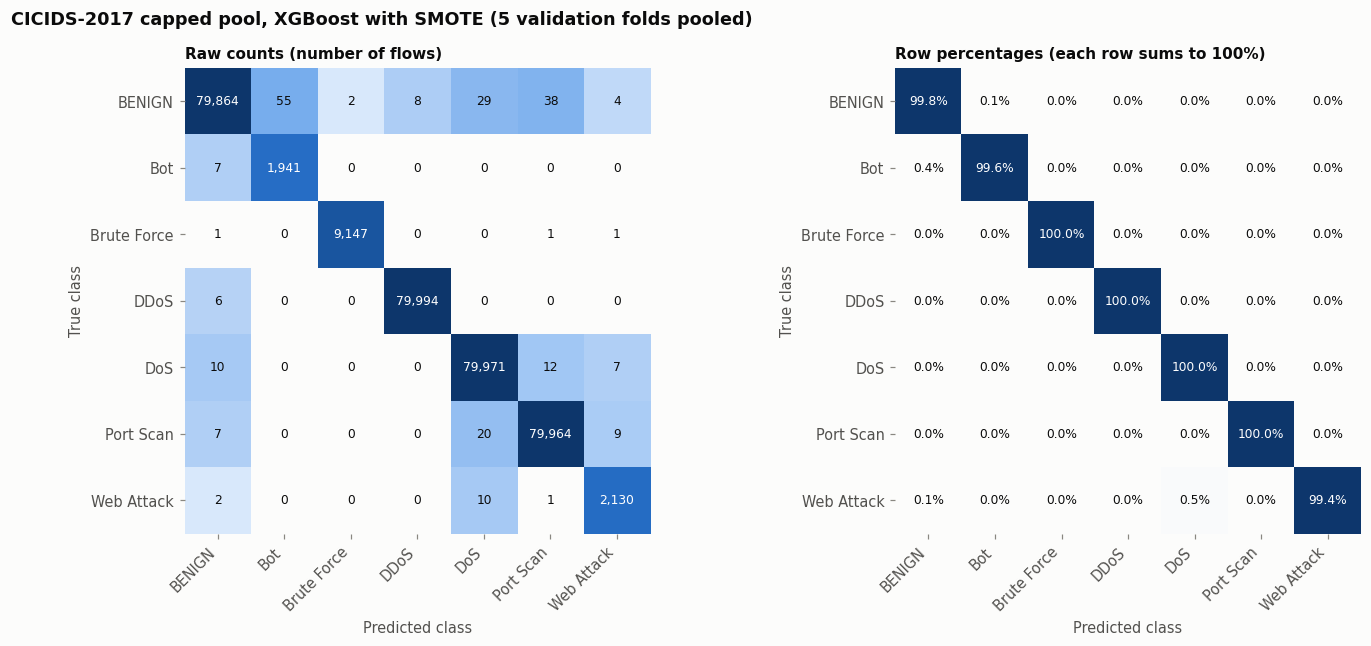

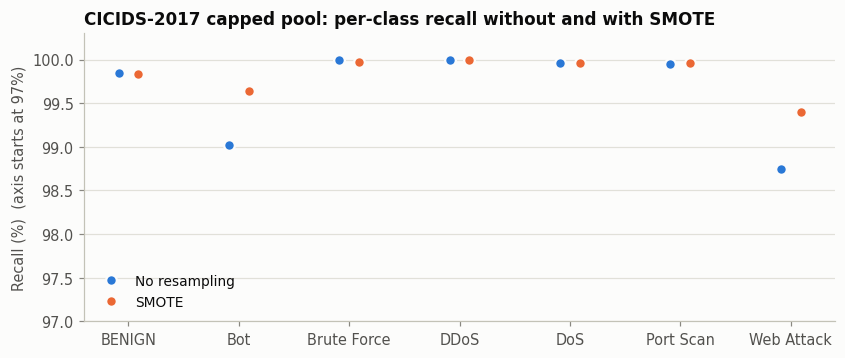

In [35]:
# 2.4  Table 6 (bottom): imbalanced pool, four largest classes capped at 80,000; 5-fold CV without and with SMOTE
if RUN_CICIDS:
    CAP_CIC = 80000
    rng = np.random.RandomState(SEED)
    idx = np.concatenate([rng.choice(np.where(y_cic == k)[0], CAP_CIC, replace=False)
                          if (y_cic == k).sum() > CAP_CIC else np.where(y_cic == k)[0]
                          for k in range(len(CIC_CLASSES))])
    Xc, yc = X_cic[idx], y_cic[idx]
    pool_counts = dict(zip(CIC_CLASSES, np.bincount(yc).tolist()))
    print(f"CV pool: {len(yc):,} records;", pool_counts,
          f"| largest : smallest = {max(pool_counts.values()) / min(pool_counts.values()):.0f}:1")
    record("cic_cv_pool", len(yc)); record("cic_cv_ratio", round(max(pool_counts.values()) / min(pool_counts.values())))
    CIC_CKPT = os.path.join(OUT, "cicids_cv_folds.jsonl")
    cic_none = cv_evaluate(Xc, yc, CIC_CLASSES, False, 20000, "cicids_none", CIC_CKPT)
    cic_smote = cv_evaluate(Xc, yc, CIC_CLASSES, True, 20000, "cicids_smote", CIC_CKPT)
    print("\nTable 6 (bottom). CICIDS-2017 capped pool, 5-fold CV, XGBoost (mean ± std, %):")
    print(cv_table({"No resampling": cic_none, "SMOTE (minority classes lifted to 20,000)": cic_smote}).to_string())
    pcr_cic = per_class_recall({"No resampling": cic_none, "SMOTE": cic_smote}, CIC_CLASSES)
    pcr_cic["change"] = pcr_cic["SMOTE"] - pcr_cic["No resampling"]
    print("\nper-class recall (%):"); print(pcr_cic.round(2).to_string())
    pcr_cic.to_csv(os.path.join(OUT, "cicids_cv_per_class_recall.csv"))
    for lab, res in [("none", cic_none), ("smote", cic_smote)]:
        for m in CV_METRICS:
            record(f"cic_cv_{lab}_{m}", res[m].mean() * 100); record(f"cic_cvsd_{lab}_{m}", res[m].std() * 100)
    for c in CIC_CLASSES:
        record(f"cic_cv_recall_none_{c}", pcr_cic.loc[c, "No resampling"])
        record(f"cic_cv_recall_smote_{c}", pcr_cic.loc[c, "SMOTE"])

    cm_cic = np.sum(np.array(cic_smote["cm"].tolist()), axis=0)
    plot_confusion_pair(cm_cic, CIC_CLASSES, "CICIDS-2017 capped pool, XGBoost with SMOTE (5 validation folds pooled)",
                        "cicids_confusion_cv_smote")

    fig, ax = plt.subplots(figsize=(8.8, 3.4))
    x = np.arange(len(CIC_CLASSES))
    for j, (lab, col, key) in enumerate([("No resampling", SERIES[0], "No resampling"), ("SMOTE", SERIES[1], "SMOTE")]):
        ax.plot(x + (j - 0.5) * 0.18, pcr_cic[key].values, "o", ms=7, color=col, mec=SURFACE, mew=1.5, label=lab)
    lo = min(97.0, np.floor(pcr_cic[["No resampling", "SMOTE"]].values.min()) - 0.5)
    ax.set_xticks(x); ax.set_xticklabels(CIC_CLASSES); value_axis(ax)
    ax.set_ylim(lo, 100.3); ax.set_ylabel(f"Recall (%)  (axis starts at {lo:g}%)")
    ax.legend(loc="lower left")
    ax.set_title("CICIDS-2017 capped pool: per-class recall without and with SMOTE")
    save_fig(fig, "cicids_cv_per_class_recall")
    del Xc, yc

In [36]:
# 2.5  The same pool with the exact copies left in (Section 6.3): the other half of the de-duplication decision
if RUN_CICIDS and len(cic_dups):
    y_dups = CIC_LE.transform(cic_dups["Cat"].values)
    y_union = np.concatenate([y_cic, y_dups])
    rng = np.random.RandomState(SEED)
    idx_u = np.concatenate([rng.choice(np.where(y_union == k)[0], 80000, replace=False)
                            if (y_union == k).sum() > 80000 else np.where(y_union == k)[0]
                            for k in range(len(CIC_CLASSES))])
    from_pool = idx_u[idx_u < len(y_cic)]
    from_dups = idx_u[idx_u >= len(y_cic)] - len(y_cic)
    Xd = np.vstack([X_cic[from_pool], cic_dups[CIC_X_COLS].values[from_dups].astype(np.float64)])
    yd = np.concatenate([y_cic[from_pool], y_dups[from_dups]])
    share = len(from_dups) / len(yd) * 100
    print(f"pool with copies kept: {len(yd):,} records, {len(from_dups):,} of them ({share:.2f}%) are copies")
    print("class counts:", dict(zip(CIC_CLASSES, np.bincount(yd, minlength=len(CIC_CLASSES)).tolist())))
    CIC_DUP_CKPT = os.path.join(OUT, "cicids_withdup_folds.jsonl")
    cic_dup_none = cv_evaluate(Xd, yd, CIC_CLASSES, False, 20000, "cicids_withdup_none", CIC_DUP_CKPT)
    cic_dup_smote = cv_evaluate(Xd, yd, CIC_CLASSES, True, 20000, "cicids_withdup_smote", CIC_DUP_CKPT)
    dd_tab = cv_table({"Copies removed (paper)": cic_none, "Copies kept": cic_dup_none,
                       "Copies removed + SMOTE": cic_smote, "Copies kept + SMOTE": cic_dup_smote})
    print("\nCICIDS-2017 capped pool, 5-fold CV, XGBoost, both de-duplication variants (%):")
    print(dd_tab.to_string())
    dd_tab.to_csv(os.path.join(OUT, "cicids_dedup_variants.csv"))
    for lab, res in [("withdup_none", cic_dup_none), ("withdup_smote", cic_dup_smote)]:
        for m in CV_METRICS:
            record(f"cic_cv_{lab}_{m}", res[m].mean() * 100)
    gap = (cic_dup_none["f1"].mean() - cic_none["f1"].mean()) * 100
    print(f"\nkeeping the copies moves macro F1 by {gap:+.2f} points on this corpus.")
    record("cic_dedup_f1_gap", gap)
    print(paired_tests(cic_dup_none.rename(columns={"f1": "f1_macro", "aucpr": "auc_pr_macro"}),
                       cic_none.rename(columns={"f1": "f1_macro", "aucpr": "auc_pr_macro"}),
                       ["accuracy", "f1_macro", "auc_pr_macro"], "CICIDS-2017",
                       "copies kept vs removed").to_string(index=False))
    del Xd, yd

pool with copies kept: 337,968 records, 63,558 of them (18.81%) are copies
class counts: {'BENIGN': 80000, 'Bot': 1956, 'Brute Force': 13832, 'DDoS': 80000, 'DoS': 80000, 'Port Scan': 80000, 'Web Attack': 2180}
  [cicids_withdup_none] all 5 folds loaded from cicids_withdup_folds.jsonl
  [cicids_withdup_smote] all 5 folds loaded from cicids_withdup_folds.jsonl

CICIDS-2017 capped pool, 5-fold CV, XGBoost, both de-duplication variants (%):
                Copies removed (paper)   Copies kept Copies removed + SMOTE Copies kept + SMOTE
Accuracy                  99.93 ± 0.01  99.94 ± 0.01           99.93 ± 0.01        99.94 ± 0.00
Macro precision           99.51 ± 0.14  99.56 ± 0.10           99.44 ± 0.13        99.45 ± 0.14
Macro recall              99.64 ± 0.10  99.64 ± 0.16           99.82 ± 0.07        99.82 ± 0.11
Macro F1                  99.58 ± 0.10  99.60 ± 0.11           99.63 ± 0.08        99.64 ± 0.09
Macro AUC-PR              99.90 ± 0.06  99.90 ± 0.05           99.93 ± 0.03   

In [37]:
# 2.6  Can CICIDS-2017 be split by time? (Section 6.3)
# The release carries no timestamp column, so the capture session in src_file is the only time marker.
if RUN_CICIDS:
    sess = sorted(cic["src_file"].unique())
    print(f"{len(sess)} capture sessions:")
    for s in sess:
        cats = sorted(cic.loc[cic.src_file == s, "Cat"].unique())
        print(f"  {s:<52}{int((cic.src_file == s).sum()):>9,}  {cats}")
    only_one = [c for c in CIC_CLASSES if cic.loc[cic.Cat == c, "src_file"].nunique() == 1]
    print(f"\nclasses that occur in exactly one session: {only_one}")
    print("Holding a session out therefore removes whole classes from training, so a per-session split")
    print("cannot be evaluated on the seven-class problem. The capture design, not the protocol, is the")
    print("limit here. What can be done is to respect order inside each session: flows are written in")
    print("the order CICFlowMeter finished them, so the first 70% of each file is earlier traffic than")
    print("the last 30%. That is positional, not timestamped, and is reported as such.")

    pos = cic.groupby("src_file").cumcount()
    size = cic["src_file"].map(cic["src_file"].value_counts())
    early = (pos < 0.7 * size).values
    tr_i, te_i = np.where(early)[0], np.where(~early)[0]
    comp = pd.DataFrame({"early 70% (train)": np.bincount(y_cic[tr_i], minlength=len(CIC_CLASSES)),
                         "late 30% (test)": np.bincount(y_cic[te_i], minlength=len(CIC_CLASSES))},
                        index=CIC_CLASSES)
    print("\nwithin-session positional split:"); print(comp.to_string())
    gone = {side: [c for c in CIC_CLASSES if comp.loc[c, side] == 0] for side in comp.columns}
    if any(gone.values()):
        print("\nclasses with no records at all on one side:", {k: v for k, v in gone.items() if v})
        print("Each attack family also occupies one contiguous window inside its session, so even the")
        print("positional split leaves classes with nothing to learn from or nothing to be tested on.")
        print("Verdict: this release admits no time-respecting evaluation of the seven-class problem,")
        print("at session level or within a session. That is a property of the capture schedule.")
        record("cic_positional_possible", 0)
    else:
        record("cic_positional_possible", 1)
    if (comp.min(axis=1) > 0).all():
        sc = MinMaxScaler().fit(X_cic[tr_i])
        clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method="hist",
                                random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
        clf.fit(sc.transform(X_cic[tr_i]), y_cic[tr_i])
        pred = clf.predict(sc.transform(X_cic[te_i]))
        p, r, f1, _ = precision_recall_fscore_support(y_cic[te_i], pred, average="macro", zero_division=0)
        acc = accuracy_score(y_cic[te_i], pred)
        print(f"\nlate 30% of every session, XGBoost trained on the early 70%: accuracy {acc * 100:.2f}%, "
              f"macro F1 {f1 * 100:.2f}%")
        print(f"against {cic_none['accuracy'].mean() * 100:.2f}% / {cic_none['f1'].mean() * 100:.2f}% "
              f"for the shuffled 5-fold protocol on the capped pool")
        rc = recall_score(y_cic[te_i], pred, average=None, labels=list(range(len(CIC_CLASSES))), zero_division=0) * 100
        print("per-class recall (%):", {c: round(v, 2) for c, v in zip(CIC_CLASSES, rc)})
        record("cic_positional_acc", acc * 100); record("cic_positional_f1", f1 * 100)
        for c, v in zip(CIC_CLASSES, rc):
            record(f"cic_positional_recall_{c}", v)
        plot_confusion_pct(confusion_matrix(y_cic[te_i], pred, labels=list(range(len(CIC_CLASSES)))),
                           CIC_CLASSES, "CICIDS-2017, late 30% of each capture session held out",
                           "cicids_confusion_positional")
        del sc, clf

8 capture sessions:
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv      223,082  ['BENIGN', 'DDoS']
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv  212,254  ['BENIGN', 'Port Scan']
  Friday-WorkingHours-Morning.pcap_ISCX.csv             180,097  ['BENIGN', 'Bot']
  Monday-WorkingHours.pcap_ISCX.csv                     502,464  ['BENIGN']
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  245,820  ['BENIGN']
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  156,579  ['BENIGN', 'Web Attack']
  Tuesday-WorkingHours.pcap_ISCX.csv                    409,983  ['BENIGN', 'Brute Force']
  Wednesday-workingHours.pcap_ISCX.csv                  590,472  ['BENIGN', 'DoS']

classes that occur in exactly one session: ['Bot', 'Brute Force', 'DDoS', 'DoS', 'Port Scan', 'Web Attack']
Holding a session out therefore removes whole classes from training, so a per-session split
cannot be evaluated on the seven-class problem. The capture design, not the protocol, is the
limit

reference fit on one 80/20 split of the capped pool: macro F1 99.71%

global SHAP importance, top 12 of 77 features:
                    feature  mean_abs_shap  cum_share_pct
           Destination Port       1.419484      14.250000
    Init_Win_bytes_backward       0.804863      22.340000
     Init_Win_bytes_forward       0.736761      29.740000
       min_seg_size_forward       0.653662      36.299999
               Flow IAT Min       0.415644      40.470001
              Flow Duration       0.354433      44.029999
Total Length of Fwd Packets       0.348817      47.540001
      Bwd Packet Length Std       0.298591      50.529999
              Bwd Packets/s       0.282911      53.380001
                Fwd IAT Min       0.261177      56.000000
        Average Packet Size       0.236124      58.369999
         Packet Length Mean       0.233909      60.720001
top 5 features hold 40.5% of the attribution mass, top 10 hold 56.0%
   0.02 n=  5,331 test macro F1 97.22
   0.05 n= 13,330 test

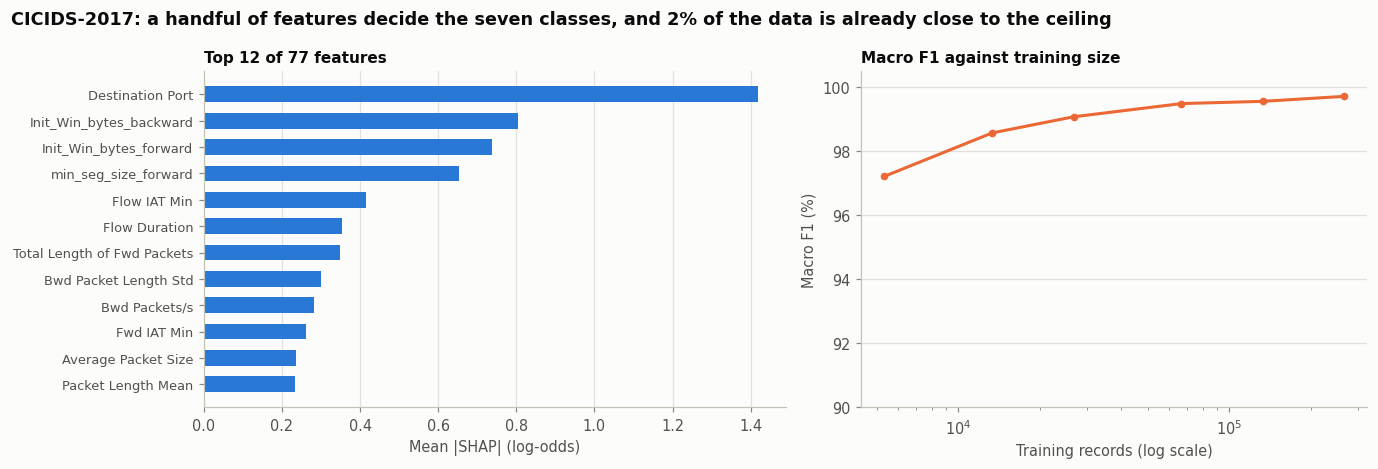

In [38]:
# 2.7  What the CICIDS-2017 model uses, and whether more data would help (Section 6.3)
if RUN_CICIDS and RUN_XAI:
    try:
        import shap
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
        import shap
    rng = np.random.RandomState(SEED)
    idx = np.concatenate([rng.choice(np.where(y_cic == k)[0], min(80000, int((y_cic == k).sum())), replace=False)
                          for k in range(len(CIC_CLASSES))])
    Xc2, yc2 = X_cic[idx], y_cic[idx]
    tr_i, te_i = train_test_split(np.arange(len(yc2)), test_size=0.2, random_state=SEED, stratify=yc2)
    sc = MinMaxScaler().fit(Xc2[tr_i])
    Xtr_c, Xte_c = sc.transform(Xc2[tr_i]), sc.transform(Xc2[te_i])
    ref_c = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method="hist",
                              random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
    ref_c.fit(Xtr_c, yc2[tr_i])
    print(f"reference fit on one 80/20 split of the capped pool: macro F1 "
          f"{f1_score(yc2[te_i], ref_c.predict(Xte_c), average='macro') * 100:.2f}%")

    s_idx = np.sort(np.concatenate([                      # stratified explanation sample
        np.random.default_rng(SEED).choice(np.where(yc2[te_i] == k)[0],
                                          size=min(int((yc2[te_i] == k).sum()),
                                                   max(50, int(round(6000 * (yc2[te_i] == k).sum() / len(te_i))))),
                                          replace=False) for k in range(len(CIC_CLASSES))]))
    sv_c = np.asarray(shap.TreeExplainer(ref_c).shap_values(Xte_c[s_idx]))
    if sv_c.ndim == 3 and sv_c.shape[1] != len(CIC_X_COLS):
        sv_c = np.transpose(sv_c, (1, 2, 0))
    shap_cic = pd.DataFrame({"feature": CIC_X_COLS, "mean_abs_shap": np.abs(sv_c).mean(axis=(0, 2))})
    shap_cic = shap_cic.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    shap_cic["cum_share_pct"] = (shap_cic.mean_abs_shap.cumsum() / shap_cic.mean_abs_shap.sum() * 100).round(2)
    shap_cic.to_csv(os.path.join(OUT, "cicids_shap_global.csv"), index=False)
    print(f"\nglobal SHAP importance, top 12 of {len(CIC_X_COLS)} features:")
    print(shap_cic.head(12).to_string(index=False))
    print(f"top 5 features hold {shap_cic.cum_share_pct.iloc[4]:.1f}% of the attribution mass, "
          f"top 10 hold {shap_cic.cum_share_pct.iloc[9]:.1f}%")
    record("cic_shap_top5_share_pct", shap_cic.cum_share_pct.iloc[4])
    record("cic_shap_top10_share_pct", shap_cic.cum_share_pct.iloc[9])

    rows = []
    for frac in [0.02, 0.05, 0.10, 0.25, 0.50, 1.00]:
        sub = (np.arange(len(tr_i)) if frac == 1.0 else
               np.sort(np.concatenate([np.random.default_rng(SEED).choice(
                   np.where(yc2[tr_i] == k)[0], size=max(2, int(round((yc2[tr_i] == k).sum() * frac))),
                   replace=False) for k in range(len(CIC_CLASSES))])))
        m = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method="hist",
                              random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
        m.fit(Xtr_c[sub], yc2[tr_i][sub])
        pv = m.predict(Xte_c)
        rows.append(dict(fraction=frac, n_train=int(len(sub)),
                         test_accuracy=accuracy_score(yc2[te_i], pv) * 100,
                         test_f1_macro=f1_score(yc2[te_i], pv, average="macro", zero_division=0) * 100))
        print(f"  {frac:>5.2f} n={len(sub):>7,} test macro F1 {rows[-1]['test_f1_macro']:.2f}")
    lc_cic = pd.DataFrame(rows); lc_cic.to_csv(os.path.join(OUT, "cicids_learning_curve.csv"), index=False)
    print("\nCICIDS-2017 learning curve (single 80/20 split of the capped pool):")
    print(lc_cic.round(2).to_string(index=False))
    record("cic_lc_f1_2pct", lc_cic.test_f1_macro.iloc[0]); record("cic_lc_f1_full", lc_cic.test_f1_macro.iloc[-1])

    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3), gridspec_kw=dict(width_ratios=[1.15, 1]))
    top12 = shap_cic.head(12).iloc[::-1]
    axes[0].barh(np.arange(12), top12.mean_abs_shap.values, height=0.6, color=SERIES[0])
    axes[0].set_yticks(np.arange(12)); axes[0].set_yticklabels(top12.feature.values, fontsize=8.5)
    axes[0].set_xlabel("Mean |SHAP| (log-odds)"); value_axis(axes[0], "x")
    axes[0].set_title(f"Top 12 of {len(CIC_X_COLS)} features", fontsize=10)
    axes[1].plot(lc_cic.n_train, lc_cic.test_f1_macro, color=SERIES[1], marker="o", markersize=4)
    axes[1].set_xscale("log"); axes[1].set_xlabel("Training records (log scale)")
    axes[1].set_ylabel("Macro F1 (%)"); value_axis(axes[1])
    axes[1].set_ylim(min(90, lc_cic.test_f1_macro.min() - 2), 100.5)
    axes[1].set_title("Macro F1 against training size", fontsize=10)
    fig.suptitle("CICIDS-2017: a handful of features decide the seven classes, and 2% of the data is "
                 "already close to the ceiling", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "cicids_shap_and_learning_curve")
    del Xc2, yc2, Xtr_c, Xte_c, ref_c, sv_c

In [39]:
# 2.8  Keep only what Part 3 needs from CICIDS-2017 and free the rest
if RUN_CICIDS or RUN_MERGED:
    CIC_KEEP = ["Label", "Destination Port", "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Fwd IAT Mean", "Bwd IAT Mean",
                "Init_Win_bytes_forward", "Init_Win_bytes_backward"]
    cic = cic[CIC_KEEP].copy()
for _v in ["X_cic", "Xtr", "Xte", "Xtr_s", "Xte_s", "cic_dups", "cic_hash", "cic_keep"]:
    globals().pop(_v, None)
gc.collect()
print("Part 2 finished.")

Part 2 finished.


---
# Part 3. The merged pool and cross-dataset transfer (paper Sections 3.3 and 7)

Only the four categories with a defensible correspondence are kept:

| Shared class | UNSW-NB15 | CICIDS-2017 |
|---|---|---|
| Normal | Normal | BENIGN |
| DoS | DoS | DoS + DDoS |
| Reconnaissance | Reconnaissance | Port Scan |
| Backdoor | Backdoor(s) | Bot (the weakest correspondence, flagged in the paper) |

Excluded: UNSW Analysis, Exploits, Fuzzers, Generic, Shellcode and Worms; CICIDS Brute Force, Web Attack,
Heartbleed and Infiltration. Ten features have a direct counterpart in both corpora. CICFlowMeter reports
durations and inter-arrival times in microseconds while UNSW-NB15 uses seconds and milliseconds, so Flow
Duration is divided by 10^6 and both IAT means by 10^3. The full raw UNSW-NB15 capture is used here, not
the downsampled Part 1 pool, because downsampling Normal on one side only would distort the joint
distribution. `source_dataset` is never a feature: it defines the transfer test in 3.5 and the per-source
breakdown in 3.4, where one model trained on the merged pool is scored separately on each corpus's records.

In [40]:
# 3.1  UNSW-NB15 side: full raw capture, the four shared classes, the ten aligned features
if RUN_MERGED:
    UCOLS = ["dsport", "dur", "Spkts", "Dpkts", "sbytes", "dbytes", "Sintpkt", "Dintpkt",
             "swin", "dwin", "attack_cat", "label"]
    u = pd.concat([pd.read_csv(p, header=None, names=COLUMNS, usecols=UCOLS, low_memory=False,
                               encoding="latin1") for p in UNSW_PARTS], ignore_index=True)
    def parse_port(v):
        if pd.isna(v): return np.nan
        s = str(v).strip()
        if s in ("", "-"): return np.nan
        try:
            return int(s, 16) if s.lower().startswith("0x") else int(float(s))
        except ValueError:
            try: return int(s, 16)
            except ValueError: return np.nan
    u["dsport"] = u["dsport"].apply(parse_port)
    u["attack_cat"] = (u["attack_cat"].astype(str).str.strip()
                       .replace({"nan": "Normal", "": "Normal", "Backdoors": "Backdoor"}))
    u.loc[u["label"] == 0, "attack_cat"] = "Normal"
    for c in UCOLS[:10]:
        if u[c].dtype == object:
            u[c] = pd.to_numeric(u[c].astype(str).str.strip(), errors="coerce")
    u["Shared"] = u["attack_cat"].map({"Normal": "Normal", "DoS": "DoS",
                                       "Reconnaissance": "Reconnaissance", "Backdoor": "Backdoor"})
    u = u[u["Shared"].notna()].reset_index(drop=True)
    ALIGN = ["dest_port", "duration", "fwd_packets", "bwd_packets", "fwd_bytes",
             "bwd_bytes", "fwd_iat_mean", "bwd_iat_mean", "fwd_win", "bwd_win"]
    u_al = pd.DataFrame({"dest_port": u["dsport"], "duration": u["dur"],
                         "fwd_packets": u["Spkts"], "bwd_packets": u["Dpkts"],
                         "fwd_bytes": u["sbytes"], "bwd_bytes": u["dbytes"],
                         "fwd_iat_mean": u["Sintpkt"], "bwd_iat_mean": u["Dintpkt"],
                         "fwd_win": u["swin"], "bwd_win": u["dwin"]})
    u_al["Shared"] = u["Shared"].values; u_al["source_dataset"] = "UNSW-NB15"
    n_u_kept = len(u_al)
    lost = u_al[u_al[ALIGN].isna().any(axis=1)]["Shared"].value_counts().to_dict()
    u_al = u_al.dropna(subset=ALIGN).reset_index(drop=True)
    print(f"UNSW-NB15 records in the four shared classes: {n_u_kept:,}; after alignment {len(u_al):,} "
          f"(lost for an unparseable destination port: {lost})")
    record("merged_unsw_kept", n_u_kept); record("merged_unsw_aligned", len(u_al)); record("merged_unsw_lost", n_u_kept - len(u_al))
    del u; gc.collect()

UNSW-NB15 records in the four shared classes: 2,251,433; after alignment 2,251,426 (lost for an unparseable destination port: {'Normal': 7})


merged pool: 4,760,884 records
source_dataset  UNSW-NB15  CICIDS-2017    Total  % of pool
Shared                                                    
Backdoor             2329         1948     4277       0.09
DoS                 16353       321759   338112       7.10
Normal            2218757      2095057  4313814      90.61
Reconnaissance      13987        90694   104681       2.20
classes in encoded order: ['Backdoor', 'DoS', 'Normal', 'Reconnaissance']
=== duplicate and label-conflict audit: merged pool ===
records                                          : 4,760,884
distinct feature vectors (10 features)            : 4,065,384
distinct (feature vector, label) pairs           : 4,066,824   <- what de-duplication keeps
  the gap between those two counts               : 1,440 extra labels carried by 1,168 vectors that appear under more than one label
records with at least one exact copy (features+label): 817,325 (17.17%)
records dropped if those copies are removed      : 694,060
record

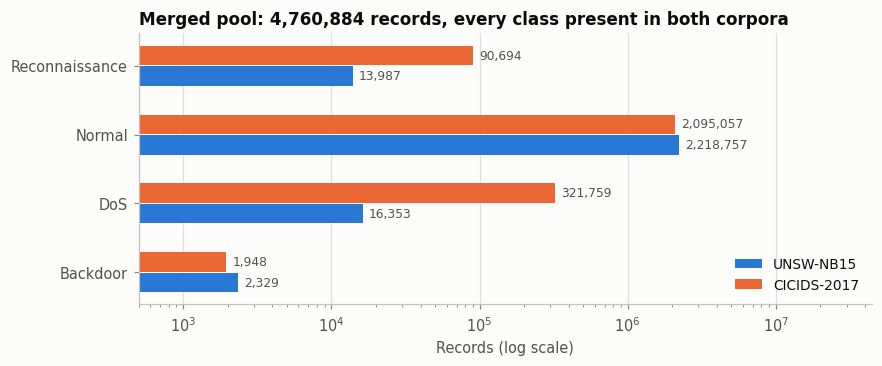

In [41]:
# 3.2  CICIDS-2017 side, unit conversion, merge, and the per-source class table
if RUN_MERGED:
    def to_shared(lbl):
        s = str(lbl).strip().upper()
        if s == "BENIGN": return "Normal"
        if "BOT" in s: return "Backdoor"
        if "DDOS" in s or "DOS" in s: return "DoS"
        if "PORTSCAN" in s or "PORT SCAN" in s: return "Reconnaissance"
        return None
    cc = cic.copy(); cc["Shared"] = cc["Label"].apply(to_shared)
    cc = cc[cc["Shared"].notna()].reset_index(drop=True)
    c_al = pd.DataFrame({"dest_port": cc["Destination Port"],
                         "duration": cc["Flow Duration"] / 1e6,        # microseconds -> seconds
                         "fwd_packets": cc["Total Fwd Packets"],
                         "bwd_packets": cc["Total Backward Packets"],
                         "fwd_bytes": cc["Total Length of Fwd Packets"],
                         "bwd_bytes": cc["Total Length of Bwd Packets"],
                         "fwd_iat_mean": cc["Fwd IAT Mean"] / 1000,    # microseconds -> milliseconds
                         "bwd_iat_mean": cc["Bwd IAT Mean"] / 1000,
                         "fwd_win": cc["Init_Win_bytes_forward"],
                         "bwd_win": cc["Init_Win_bytes_backward"]})
    c_al["Shared"] = cc["Shared"].values; c_al["source_dataset"] = "CICIDS-2017"
    c_al = c_al.dropna(subset=ALIGN).reset_index(drop=True)
    comb = pd.concat([u_al, c_al], ignore_index=True); del cc, c_al, u_al; gc.collect()
    xt = pd.crosstab(comb["Shared"], comb["source_dataset"])[["UNSW-NB15", "CICIDS-2017"]]
    xt["Total"] = xt.sum(1); xt["% of pool"] = (xt["Total"] / len(comb) * 100).round(2)
    print(f"merged pool: {len(comb):,} records")
    print(xt.to_string())
    xt.to_csv(os.path.join(OUT, "merged_pool_composition.csv"))
    record("merged_total", len(comb))
    for c in xt.index:
        record(f"merged_count_{c}", xt.loc[c, "Total"]); record(f"merged_unsw_{c}", xt.loc[c, "UNSW-NB15"])
        record(f"merged_cic_{c}", xt.loc[c, "CICIDS-2017"]); record(f"merged_pct_{c}", xt.loc[c, "Total"] / len(comb) * 100)
    COMB_LE, COMB_CLASSES = make_encoder(sorted(comb["Shared"].unique()))
    y_comb = COMB_LE.transform(comb["Shared"].values)
    X_comb = comb[ALIGN].astype(np.float64).values
    src_comb = comb["source_dataset"].values
    print("classes in encoded order:", COMB_CLASSES)

    # the same audit again, now on ten coarse features, where far more records collide than on 43 or 77
    dup_comb, comb_keep, comb_hash = duplicate_audit(comb[ALIGN], comb["Shared"].values, "merged pool", verify=50)
    print(f"\nThe merged pool is reported with its copies kept, as UNSW-NB15 is, because alignment to ten\n"
          f"features is what creates most of them: a pair of flows that differ in a dropped feature becomes\n"
          f"one vector here. Removing them would change what the pool represents rather than clean it.")
    for k in ["distinct_vectors", "distinct_vector_label_pairs", "records_with_a_copy",
              "conflicted_vectors", "records_on_conflicted_vectors"]:
        record(f"merged_{k}", dup_comb[k])
    both_src = (pd.DataFrame({"h": comb_hash, "s": src_comb}).drop_duplicates()
                .groupby("h")["s"].nunique())
    n_both = int((both_src > 1).sum())
    print(f"feature vectors that occur in both corpora: {n_both:,} "
          f"({n_both / dup_comb['distinct_vectors'] * 100:.2f}% of the distinct vectors)")
    record("merged_vectors_in_both_corpora", n_both)
    del both_src, comb_hash

    fig, ax = plt.subplots(figsize=(8.6, 3.2))
    y = np.arange(len(xt))
    for j, (src, col) in enumerate([("UNSW-NB15", SERIES[0]), ("CICIDS-2017", SERIES[1])]):
        ax.barh(y + (j - 0.5) * 0.3, xt[src].values, height=0.28, color=col, label=src)
        for i, v in enumerate(xt[src].values):
            ax.text(v * 1.1, y[i] + (j - 0.5) * 0.3, f"{v:,}", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels(xt.index); ax.set_xscale("log"); value_axis(ax, "x")
    ax.set_xlim(500, xt[["UNSW-NB15", "CICIDS-2017"]].values.max() * 20)
    ax.set_xlabel("Records (log scale)"); ax.legend(loc="lower right")
    ax.set_title(f"Merged pool: {len(comb):,} records, every class present in both corpora")
    save_fig(fig, "merged_pool_composition")

  [merged_none] all 5 folds loaded from merged_cv_folds.jsonl
  [merged_smote] all 5 folds loaded from merged_cv_folds.jsonl
Table 7. Merged pool, 5-fold CV, XGBoost (%; change computed before rounding):
                       No resampling  SMOTE  change
Accuracy                       99.21  99.36    0.15
Macro precision                78.01  78.78    0.77
Macro recall                   78.15  81.49    3.34
Macro F1                       77.31  79.17    1.86
Macro AUC-PR                   72.47  73.65    1.18
Recall Backdoor                20.50  33.48   12.98
Recall DoS                     95.98  95.61   -0.36
Recall Normal                  99.61  99.78    0.17
Recall Reconnaissance          96.50  97.09    0.59

mean ± std over folds:
                No resampling         SMOTE
Accuracy         99.21 ± 0.19  99.36 ± 0.10
Macro precision  78.01 ± 5.67  78.78 ± 3.52
Macro recall     78.15 ± 1.74  81.49 ± 2.33
Macro F1         77.31 ± 3.77  79.17 ± 2.01
Macro AUC-PR     72.47 ± 2.44  7

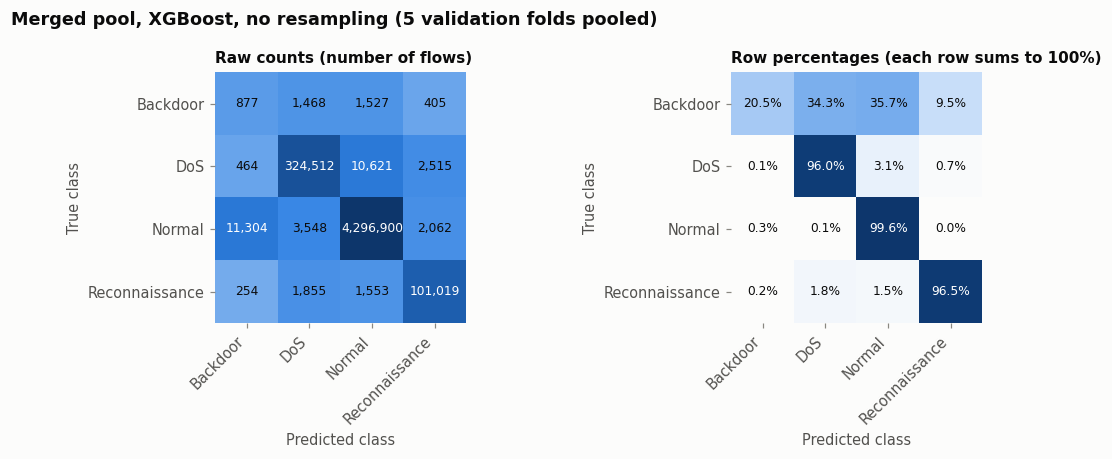

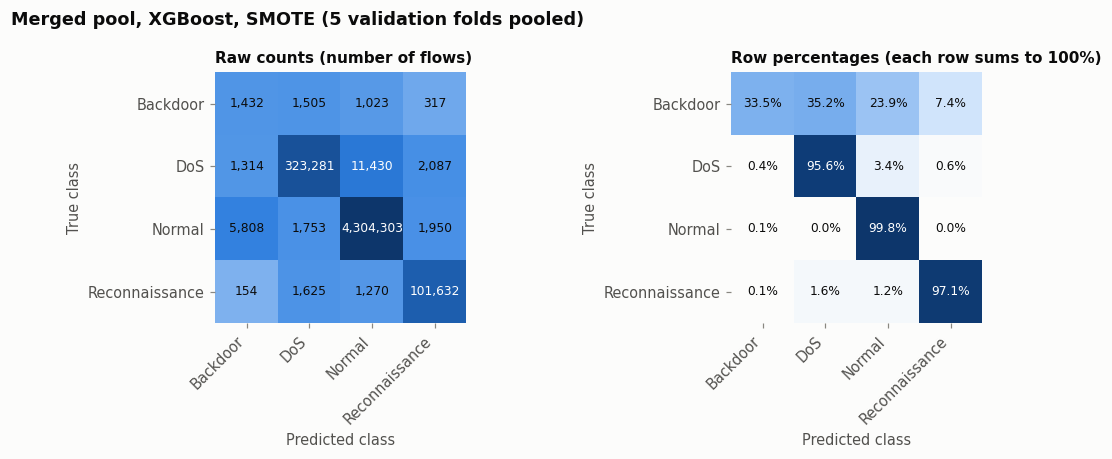

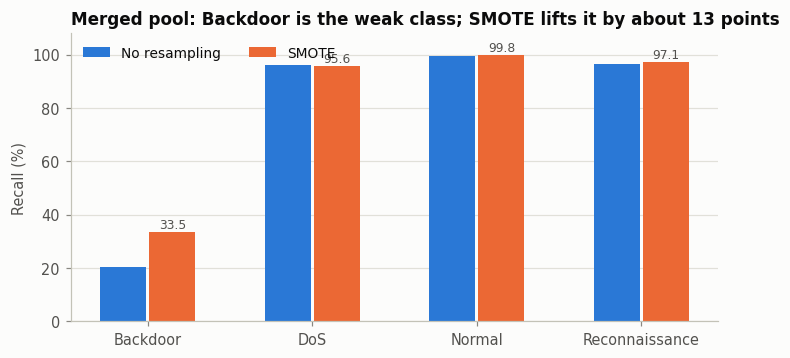


SMOTE against no resampling on the same folds, both tests:
      where    comparison          metric  folds  diff_pp  sd_diff  folds_favouring_first  t_stat  p_ttest  w_stat  p_wilcoxon
merged pool smote vs none        accuracy      5    0.154    0.199                      4    1.74 0.157591     2.0      0.1875
merged pool smote vs none precision_macro      5    0.766    7.271                      4    0.24 0.825319     4.0      0.4375
merged pool smote vs none    recall_macro      5    3.343    3.621                      4    2.06 0.107904     2.0      0.1875
merged pool smote vs none        f1_macro      5    1.858    4.740                      4    0.88 0.430299     4.0      0.4375
merged pool smote vs none    auc_pr_macro      5    1.182    2.437                      3    1.08 0.339183     4.0      0.4375


In [42]:
# 3.3  Table 7: merged pool, 5-fold CV, no resampling vs SMOTE (minority classes lifted to 5,000)
if RUN_MERGED:
    COMB_CKPT = os.path.join(OUT, "merged_cv_folds.jsonl")
    cmb_none = cv_evaluate(X_comb, y_comb, COMB_CLASSES, False, 5000, "merged_none", COMB_CKPT, src=src_comb)
    cmb_sm = cv_evaluate(X_comb, y_comb, COMB_CLASSES, True, 5000, "merged_smote", COMB_CKPT, src=src_comb)
    t5 = pd.DataFrame({"No resampling": [cmb_none[m].mean() * 100 for m in CV_METRICS],
                       "SMOTE": [cmb_sm[m].mean() * 100 for m in CV_METRICS]}, index=[CV_LABEL[m] for m in CV_METRICS])
    pcr_m = per_class_recall({"No resampling": cmb_none, "SMOTE": cmb_sm}, COMB_CLASSES)
    t5 = pd.concat([t5, pcr_m.rename(index=lambda c: f"Recall {c}")])
    t5["change"] = t5["SMOTE"] - t5["No resampling"]
    print("Table 7. Merged pool, 5-fold CV, XGBoost (%; change computed before rounding):")
    print(t5.round(2).to_string())
    print("\nmean ± std over folds:")
    print(cv_table({"No resampling": cmb_none, "SMOTE": cmb_sm}).to_string())
    t5.round(4).to_csv(os.path.join(OUT, "table5_merged_cv.csv"))
    for lab, res in [("none", cmb_none), ("smote", cmb_sm)]:
        for m in CV_METRICS:
            record(f"merged_cv_{lab}_{m}", res[m].mean() * 100)
    for c in COMB_CLASSES:
        record(f"merged_cv_recall_none_{c}", pcr_m.loc[c, "No resampling"])
        record(f"merged_cv_recall_smote_{c}", pcr_m.loc[c, "SMOTE"])

    # guard against the old label-order bug: the majority class's recall must track accuracy
    maj = int(np.bincount(y_comb).argmax())
    maj_recall = np.mean([r[maj] for r in cmb_sm["recall_per_class"]])
    assert maj_recall > cmb_sm["accuracy"].mean() - 0.05, "per-class labels look misaligned"
    print(f"\nlabel-order check passed: majority class {COMB_CLASSES[maj]} recall {maj_recall*100:.2f}% "
          f"vs accuracy {cmb_sm['accuracy'].mean()*100:.2f}%")
    for lab, res in [("no resampling", cmb_none), ("SMOTE", cmb_sm)]:
        plot_confusion_pair(np.sum(np.array(res["cm"].tolist()), axis=0), COMB_CLASSES,
                            f"Merged pool, XGBoost, {lab} (5 validation folds pooled)",
                            f"merged_confusion_{'none' if lab == 'no resampling' else 'smote'}")

    fig, ax = plt.subplots(figsize=(7.6, 3.4))
    x = np.arange(len(COMB_CLASSES))
    for j, (lab, col) in enumerate([("No resampling", SERIES[0]), ("SMOTE", SERIES[1])]):
        ax.bar(x + (j - 0.5) * 0.3, pcr_m[lab].values, width=0.28, color=col, label=lab)
    for i, c in enumerate(COMB_CLASSES):
        ax.text(i + 0.15, pcr_m.loc[c, "SMOTE"] + 1.5, f"{pcr_m.loc[c, 'SMOTE']:.1f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels(COMB_CLASSES); ax.set_ylim(0, 108); value_axis(ax)
    ax.set_ylabel("Recall (%)"); ax.legend(loc="upper left", ncol=2)
    ax.set_title("Merged pool: Backdoor is the weak class; SMOTE lifts it by about 13 points")
    save_fig(fig, "merged_per_class_recall")

    print("\nSMOTE against no resampling on the same folds, both tests:")
    ren = {"f1": "f1_macro", "aucpr": "auc_pr_macro", "precision": "precision_macro", "recall": "recall_macro"}
    print(paired_tests(cmb_sm.rename(columns=ren), cmb_none.rename(columns=ren),
                       ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_pr_macro"],
                       "merged pool", "smote vs none").to_string(index=False))

In [43]:
# 3.4  Per-source breakdown: the same merged model scored separately on each corpus's records
# The folds are the ones from 3.3, so nothing is refitted. A checkpoint written before this cell existed
# has no per-source field; delete merged_cv_folds.jsonl (or set a new RESULTS_SUBDIR in 0.2) to fill it in.
if RUN_MERGED:
    have_src = [r for r in jsonl_rows(COMB_CKPT) if "recall_by_source" in r]
    if not have_src:
        print("the merged folds on disk were written without the per-source field; rerun 3.3 with a fresh"
              "\ncheckpoint to produce this table.")
    else:
        rows = []
        for tag, lab in [("merged_none", "No resampling"), ("merged_smote", "SMOTE")]:
            fr = [r for r in have_src if r["tag"] == tag]
            if not fr:
                continue
            for s in ["UNSW-NB15", "CICIDS-2017"]:
                rec = np.mean([r["recall_by_source"][s] for r in fr], axis=0) * 100
                sup = np.sum([r["support_by_source"][s] for r in fr], axis=0)
                for i, c in enumerate(COMB_CLASSES):
                    rows.append(dict(Condition=lab, Source=s, Class=c, Validation_records=int(sup[i]),
                                     Recall=round(float(rec[i]), 2)))
        per_src = pd.DataFrame(rows)
        per_src.to_csv(os.path.join(OUT, "merged_per_source_recall.csv"), index=False)
        wide = per_src.pivot_table(index="Class", columns=["Condition", "Source"], values="Recall")
        sup_wide = per_src.pivot_table(index="Class", columns="Source", values="Validation_records",
                                       aggfunc="max")
        print("validation records contributed by each corpus, summed over the five folds:")
        print(sup_wide.to_string())
        print("\nrecall (%) of the merged model on each corpus's own records:")
        print(wide.round(2).to_string())
        gaps = []
        for lab in wide.columns.levels[0]:
            for c in COMB_CLASSES:
                u, v = wide.loc[c, (lab, "UNSW-NB15")], wide.loc[c, (lab, "CICIDS-2017")]
                gaps.append(dict(Condition=lab, Class=c, UNSW=u, CICIDS=v, gap=round(u - v, 2)))
        gaps = pd.DataFrame(gaps)
        print("\nwhere the two corpora disagree most under one condition (percentage points):")
        print(gaps.reindex(gaps.gap.abs().sort_values(ascending=False).index).head(6).to_string(index=False))
        for _, r in gaps.iterrows():
            key = "none" if r["Condition"].startswith("No") else "smote"
            record(f"merged_src_unsw_{key}_{r['Class']}", r["UNSW"])
            record(f"merged_src_cic_{key}_{r['Class']}", r["CICIDS"])

        fig, ax = plt.subplots(figsize=(8.8, 3.6))
        x = np.arange(len(COMB_CLASSES))
        for j, (s, col) in enumerate([("UNSW-NB15", SERIES[0]), ("CICIDS-2017", SERIES[1])]):
            v = [wide.loc[c, ("No resampling", s)] for c in COMB_CLASSES]
            ax.bar(x + (j - 0.5) * 0.3, v, width=0.28, color=col, label=s)
            for i, val in enumerate(v):
                ax.text(i + (j - 0.5) * 0.3, val + 1.5, f"{val:.1f}", ha="center", fontsize=8, color=INK2)
        ax.set_xticks(x); ax.set_xticklabels(COMB_CLASSES); ax.set_ylim(0, 112); value_axis(ax)
        ax.set_ylabel("Recall (%)"); ax.legend(ncol=2, loc="upper left")
        ax.set_title("One model trained on the merged pool, scored separately on each corpus's records")
        save_fig(fig, "merged_per_source_recall")

the merged folds on disk were written without the per-source field; rerun 3.3 with a fresh
checkpoint to produce this table.


train UNSW-NB15 (2,251,426 records) -> test CICIDS-2017 (2,509,458 records): acc=66.69 F1_M=24.90
   class shares of the CICIDS-2017 test corpus: Backdoor 0.08%, DoS 12.82%, Normal 83.49%, Reconnaissance 3.61%
train CICIDS-2017 (2,509,458 records) -> test UNSW-NB15 (2,251,426 records): acc=97.83 F1_M=25.48
   class shares of the UNSW-NB15 test corpus: Backdoor 0.10%, DoS 0.73%, Normal 98.55%, Reconnaissance 0.62%

Table 8. Cross-dataset transfer over the four shared classes (%; per-class = recall on the test corpus):
                       UNSW-NB15 -> CICIDS-2017  CICIDS-2017 -> UNSW-NB15
accuracy                                  66.69                     97.83
precision                                 26.76                     26.62
recall                                    24.92                     25.28
f1                                        24.90                     25.48
recall_Backdoor                            0.00                      0.00
recall_DoS                       

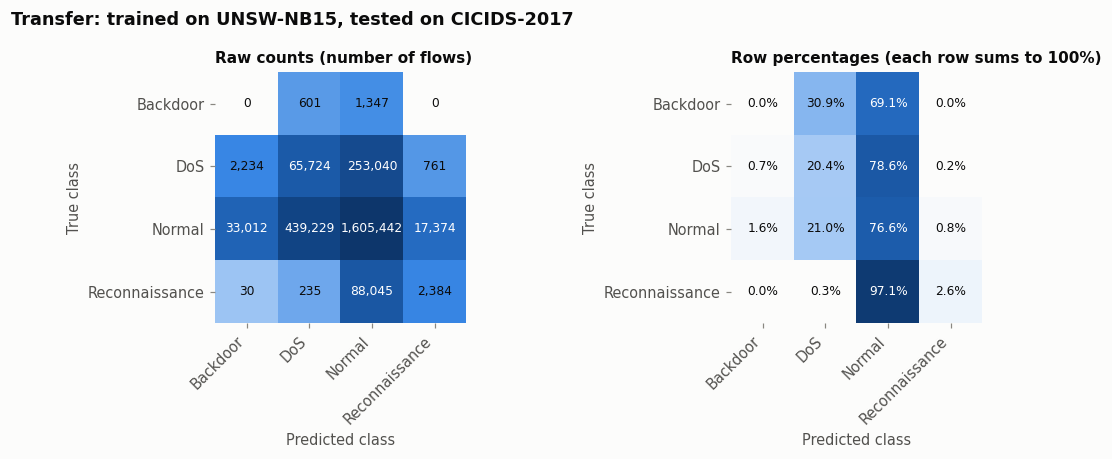

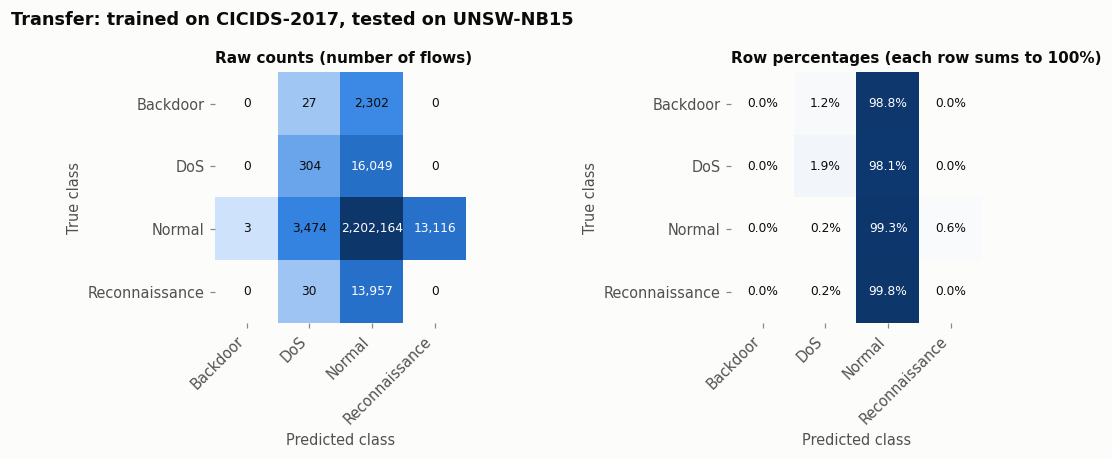

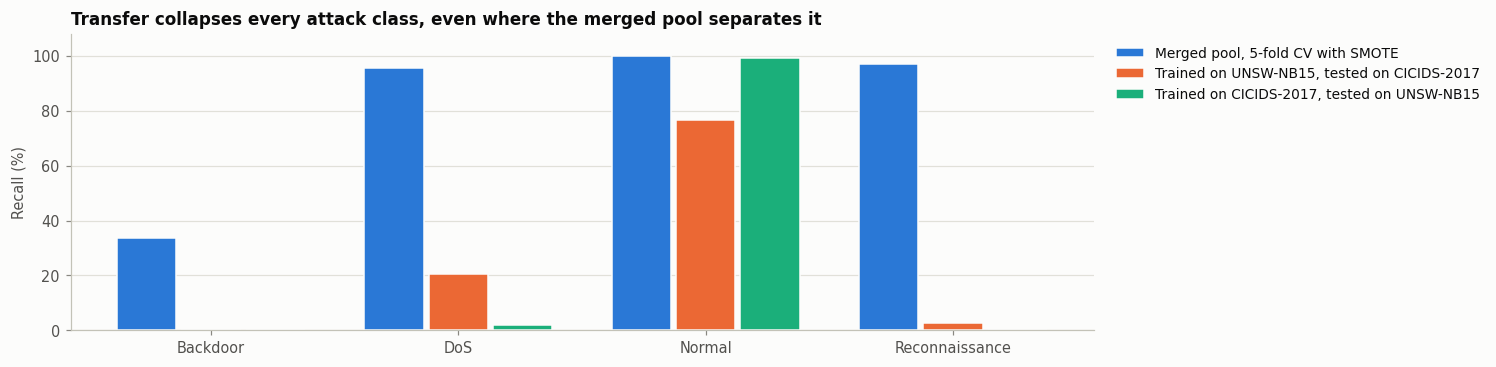

In [44]:
# 3.5  Table 8: cross-dataset transfer (train on one corpus, test on the other)
def transfer(train_name, test_name):
    tr, te = src_comb == train_name, src_comb == test_name
    sc = MinMaxScaler().fit(X_comb[tr])
    Xtr, Xte, ytr, yte = sc.transform(X_comb[tr]), sc.transform(X_comb[te]), y_comb[tr], y_comb[te]
    cnt = pd.Series(ytr).value_counts()
    strat = {k: 5000 for k in cnt.index if cnt[k] < 5000}
    if strat:
        Xtr, ytr = SMOTE(sampling_strategy=strat, random_state=SEED, k_neighbors=5).fit_resample(Xtr, ytr)
    clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method="hist",
                            random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
    clf.fit(Xtr, ytr); pred = clf.predict(Xte)
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
    rc = recall_score(yte, pred, average=None, labels=list(range(len(COMB_CLASSES))), zero_division=0)
    print(f"train {train_name} ({tr.sum():,} records) -> test {test_name} ({te.sum():,} records): "
          f"acc={accuracy_score(yte, pred)*100:.2f} F1_M={f1*100:.2f}")
    res = dict(train=train_name, test=test_name, accuracy=accuracy_score(yte, pred) * 100,
               precision=p * 100, recall=r * 100, f1=f1 * 100,
               **{f"recall_{c}": v * 100 for c, v in zip(COMB_CLASSES, rc)})
    test_share = pd.Series(yte).value_counts(normalize=True).reindex(range(len(COMB_CLASSES)), fill_value=0) * 100
    return res, confusion_matrix(yte, pred, labels=list(range(len(COMB_CLASSES)))), test_share

if RUN_MERGED:
    xfer_rows, xfer_cm = [], {}
    for a, b in [("UNSW-NB15", "CICIDS-2017"), ("CICIDS-2017", "UNSW-NB15")]:
        res, cm, share = transfer(a, b)
        xfer_rows.append(res); xfer_cm[(a, b)] = cm
        print(f"   class shares of the {b} test corpus: " + ", ".join(f"{c} {v:.2f}%" for c, v in zip(COMB_CLASSES, share)))
        record(f"xfer_testshare_{'u2c' if a == 'UNSW-NB15' else 'c2u'}_Normal", share[COMB_CLASSES.index("Normal")])
    xfer = pd.DataFrame(xfer_rows)
    t6 = xfer.set_index(xfer["train"] + " -> " + xfer["test"]).drop(columns=["train", "test"]).T
    print("\nTable 8. Cross-dataset transfer over the four shared classes (%; per-class = recall on the test corpus):")
    print(t6.round(2).to_string())
    xfer.round(2).to_csv(os.path.join(OUT, "transfer.csv"), index=False)
    for _, r in xfer.iterrows():
        tag = "u2c" if r["train"] == "UNSW-NB15" else "c2u"
        for m in ["accuracy", "precision", "recall", "f1"] + [f"recall_{c}" for c in COMB_CLASSES]:
            record(f"xfer_{tag}_{m}", r[m])
    print(f"\nmerged-pool macro F1 with SMOTE for comparison: {cmb_sm['f1'].mean()*100:.2f}%")
    for (a, b), cm in xfer_cm.items():
        plot_confusion_pair(cm, COMB_CLASSES, f"Transfer: trained on {a}, tested on {b}",
                            f"transfer_confusion_{'unsw_to_cicids' if a == 'UNSW-NB15' else 'cicids_to_unsw'}")

    fig, ax = plt.subplots(figsize=(12.0, 3.5))
    x = np.arange(len(COMB_CLASSES))
    series = [("Merged pool, 5-fold CV with SMOTE", pcr_m["SMOTE"].values, SERIES[0]),
              ("Trained on UNSW-NB15, tested on CICIDS-2017", xfer.iloc[0][[f"recall_{c}" for c in COMB_CLASSES]].values.astype(float), SERIES[1]),
              ("Trained on CICIDS-2017, tested on UNSW-NB15", xfer.iloc[1][[f"recall_{c}" for c in COMB_CLASSES]].values.astype(float), SERIES[2])]
    for j, (lab, vals, col) in enumerate(series):
        ax.bar(x + (j - 1) * 0.26, vals, width=0.24, color=col, edgecolor=SURFACE, linewidth=1.0, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(COMB_CLASSES); ax.set_ylim(0, 108); value_axis(ax)
    ax.set_ylabel("Recall (%)"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title("Transfer collapses every attack class, even where the merged pool separates it")
    save_fig(fig, "transfer_per_class_recall")

---
# Part 4. Summary, the numbers used in the Discussion, and a check against the paper

                                                setting  accuracy  f1_macro  auc_pr_macro
              UNSW-NB15, 5-fold, XGBoost, No resampling     88.38     67.05         70.95
                      UNSW-NB15, 5-fold, XGBoost, SMOTE     88.27     66.29         70.81
CICIDS-2017 capped pool, 5-fold, XGBoost, No resampling     99.93     99.58         99.90
        CICIDS-2017 capped pool, 5-fold, XGBoost, SMOTE     99.93     99.63         99.93
            Merged pool, 5-fold, XGBoost, No resampling     99.21     77.31         72.47
                    Merged pool, 5-fold, XGBoost, SMOTE     99.36     79.17         73.65
                      Transfer UNSW-NB15 -> CICIDS-2017     66.69     24.90           NaN
                      Transfer CICIDS-2017 -> UNSW-NB15     97.83     25.48           NaN


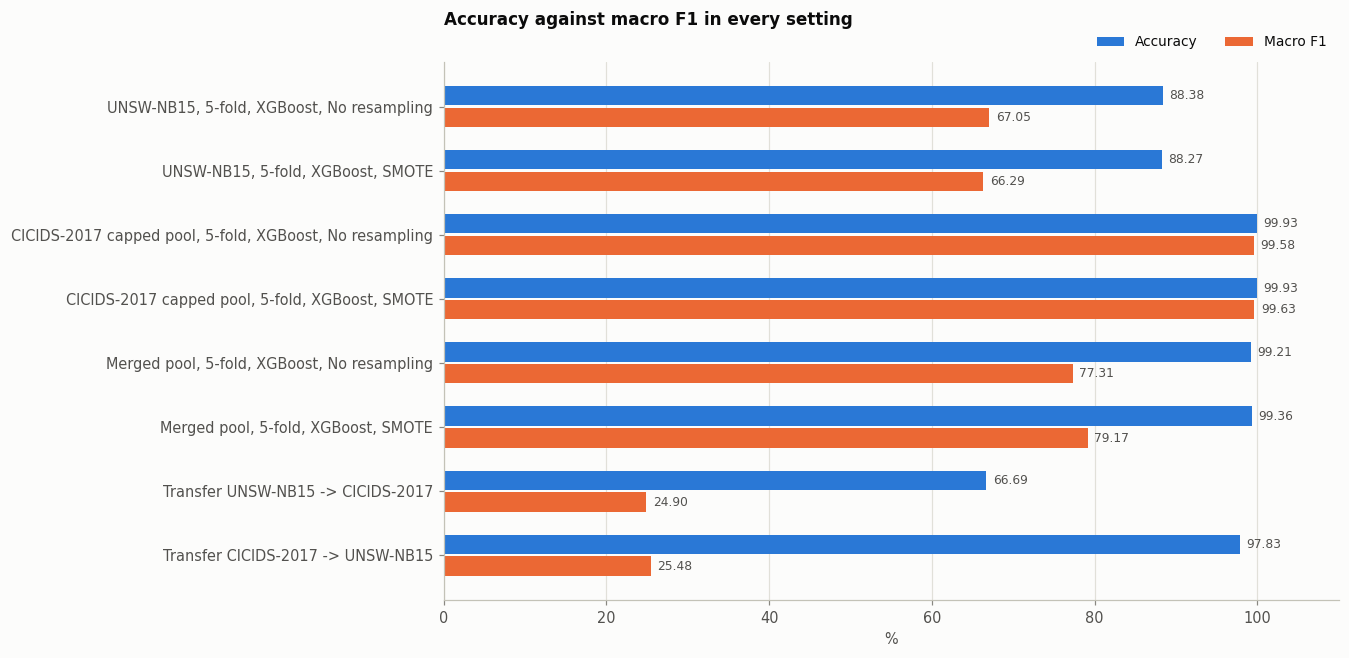

In [45]:
# 4.1  One table across the three settings: accuracy stays high while macro F1 tells the real story
rows = []
g = grid.groupby(["model", "resampling"])[METRICS].mean() * 100
for rs in ["none", "smote"]:
    rows.append(dict(setting=f"UNSW-NB15, 5-fold, XGBoost, {RESAMP_LABEL[rs]}", accuracy=g.loc[("XGB", rs), "accuracy"],
                     f1_macro=g.loc[("XGB", rs), "f1_macro"], auc_pr_macro=g.loc[("XGB", rs), "auc_pr_macro"]))
if RUN_CICIDS:
    for lab, res in [("none", cic_none), ("smote", cic_smote)]:
        rows.append(dict(setting=f"CICIDS-2017 capped pool, 5-fold, XGBoost, {RESAMP_LABEL[lab]}",
                         accuracy=res["accuracy"].mean() * 100, f1_macro=res["f1"].mean() * 100,
                         auc_pr_macro=res["aucpr"].mean() * 100))
if RUN_MERGED:
    for lab, res in [("none", cmb_none), ("smote", cmb_sm)]:
        rows.append(dict(setting=f"Merged pool, 5-fold, XGBoost, {RESAMP_LABEL[lab]}", accuracy=res["accuracy"].mean() * 100,
                         f1_macro=res["f1"].mean() * 100, auc_pr_macro=res["aucpr"].mean() * 100))
    for _, r in xfer.iterrows():
        rows.append(dict(setting=f"Transfer {r['train']} -> {r['test']}", accuracy=r["accuracy"],
                         f1_macro=r["f1"], auc_pr_macro=np.nan))
summary = pd.DataFrame(rows).round(2)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(OUT, "final_summary.csv"), index=False)

fig, ax = plt.subplots(figsize=(10.5, 0.62 * len(summary) + 1.4))
y = np.arange(len(summary))[::-1]
for j, (col, lab, c) in enumerate([("accuracy", "Accuracy", SERIES[0]), ("f1_macro", "Macro F1", SERIES[1])]):
    ax.barh(y + (0.5 - j) * 0.34, summary[col], height=0.3, color=c, label=lab)
    for yi, v in zip(y, summary[col]):
        ax.text(v + 0.8, yi + (0.5 - j) * 0.34, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(summary["setting"]); ax.set_xlim(0, 110); value_axis(ax, "x")
ax.set_xlabel("%"); ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
ax.set_title("Accuracy against macro F1 in every setting", pad=24)
save_fig(fig, "summary_accuracy_vs_macro_f1")

In [46]:
# 4.2  Numbers used in the Discussion (Section 8), computed rather than typed
V = LEDGER_VALUES
def g_(k):
    return V.get(k, np.nan)
lines = []
lines.append(f"UNSW-NB15 XGBoost+SMOTE macro F1 {g_('t2_XGB_smote_f1_macro'):.2f}% vs CICIDS-2017 {g_('cic_cv_smote_f1'):.2f}%: "
             f"gap {g_('cic_cv_smote_f1') - g_('t2_XGB_smote_f1_macro'):.2f} points")
record("disc_gap_unsw_cic", g_("cic_cv_smote_f1") - g_("t2_XGB_smote_f1_macro"))
lines.append(f"accuracy minus macro F1: UNSW-NB15 XGBoost (none) {g_('t2_XGB_none_accuracy') - g_('t2_XGB_none_f1_macro'):.2f} points; "
             f"CICIDS-2017 XGBoost+SMOTE {g_('cic_cv_smote_accuracy') - g_('cic_cv_smote_f1'):.2f} points")
record("disc_accf1_gap_unsw", g_("t2_XGB_none_accuracy") - g_("t2_XGB_none_f1_macro"))
record("disc_accf1_gap_cic", g_("cic_cv_smote_accuracy") - g_("cic_cv_smote_f1"))
lines.append(f"corpus imbalance: CICIDS-2017 {g_('cic_imbalance_ratio'):.0f}:1 vs UNSW-NB15 pool {g_('unsw_imbalance_ratio'):.0f}:1")
for c in ["Bot", "Web Attack"]:
    r_ = 80000 / g_(f"cic_count_{c}")
    record(f"disc_ratio_{c}", r_)
    lines.append(f"CICIDS-2017 {c}: {g_(f'cic_count_{c}'):,.0f} records vs 80,000 ({r_:.0f}:1); recall "
                 f"{g_(f'cic_cv_recall_smote_{c}'):.2f}% (CV, SMOTE), {g_(f'cic_cv_recall_none_{c}'):.2f}% (CV, none), "
                 f"{g_(f'cic_bal_recall_XGBoost_{c}'):.2f}% (balanced split, XGBoost)")
for c in ["Backdoors", "Analysis"]:
    r_ = 93000 / g_(f"unsw_count_{c}")
    record(f"disc_ratio_{c}", r_)
    lines.append(f"UNSW-NB15 {c}: {g_(f'unsw_count_{c}'):,.0f} records vs 93,000 Normal ({r_:.0f}:1)")
best_none = max(g_(f"pcr_{m}_none_{c}") for m in MODELS for c in ["Analysis", "Backdoors"])
best_res = max(g_(f"pcr_{m}_{t}_{c}") for m in MODELS for t in ["smote", "adasyn"] for c in ["Analysis", "Backdoors"])
record("disc_best_recall_none_ab", best_none); record("disc_best_recall_resampled_ab", best_res)
lines.append(f"best recall of Analysis or Backdoors: {best_none:.2f}% without resampling, {best_res:.2f}% with it")
if RUN_MERGED:
    lines.append(f"merged pool: Normal {g_('merged_pct_Normal'):.2f}% of records, Backdoor {g_('merged_count_Backdoor'):,.0f} "
                 f"records ({g_('merged_pct_Backdoor'):.3f}%)")
    lines.append(f"SMOTE on the merged pool: Backdoor recall {g_('merged_cv_recall_smote_Backdoor') - g_('merged_cv_recall_none_Backdoor'):+.2f} "
                 f"points, accuracy {g_('merged_cv_smote_accuracy') - g_('merged_cv_none_accuracy'):+.2f} points")
    lines.append(f"UNSW-NB15 as a transfer test corpus is {g_('xfer_testshare_c2u_Normal'):.2f}% Normal")
lines.append(f"Worms ceiling {g_('ceiling_Worms'):.2f}%; Analysis and Backdoors within "
             f"{max(g_('headroom_Analysis'), g_('headroom_Backdoors')):.2f} points of their ceilings")
for s in lines:
    print("-", s)

- UNSW-NB15 XGBoost+SMOTE macro F1 66.29% vs CICIDS-2017 99.63%: gap 33.34 points
- accuracy minus macro F1: UNSW-NB15 XGBoost (none) 21.33 points; CICIDS-2017 XGBoost+SMOTE 0.30 points
- corpus imbalance: CICIDS-2017 1075:1 vs UNSW-NB15 pool 534:1
- CICIDS-2017 Bot: 1,948 records vs 80,000 (41:1); recall 99.64% (CV, SMOTE), 99.02% (CV, none), 99.66% (balanced split, XGBoost)
- CICIDS-2017 Web Attack: 2,143 records vs 80,000 (37:1); recall 99.39% (CV, SMOTE), 98.74% (CV, none), 99.83% (balanced split, XGBoost)
- UNSW-NB15 Backdoors: 2,329 records vs 93,000 Normal (40:1)
- UNSW-NB15 Analysis: 2,677 records vs 93,000 Normal (35:1)
- best recall of Analysis or Backdoors: 18.34% without resampling, 19.28% with it
- merged pool: Normal 90.61% of records, Backdoor 4,277 records (0.090%)
- SMOTE on the merged pool: Backdoor recall +12.98 points, accuracy +0.15 points
- UNSW-NB15 as a transfer test corpus is 98.55% Normal
- Worms ceiling 91.38%; Analysis and Backdoors within 6.38 points of the

### 4.3 Paper-versus-notebook consistency ledger

Every number in the paper's tables and text is listed below with the value this run produced. The
status column reads:

* **MATCH**: equal at the precision the paper prints.
* **differs, within run-to-run range**: a model metric that moved by at most 1.04 points, the largest
  machine-to-machine difference measured for identical code, data and library versions (Section 9).
  These come from XGBoost or resampled runs on a different machine than the one behind the paper.
* **re-run**: the paper's TabNet and FT-Transformer rows came from an earlier execution. This notebook
  trains both under the same fold-local preprocessing as the trees, so its values replace them.
* **not in paper**: a result this notebook adds (for example CICIDS-2017 without resampling).
* **DIFFERS**: anything else. None is expected; if one appears, it needs a look before submission.

In [47]:
# 4.3  The ledger
P = []            # (where in the paper, what, key, paper value, kind)
def add(where, what, key, val, kind="model"):
    P.append((where, what, key, val, kind))

# Section 3 and Table 1
add("3.1", "raw UNSW-NB15 records", "unsw_raw_rows", 2540047, "count")
add("3.1", "Normal records in the raw files", "unsw_normal_raw", 2218764, "count")
add("3.1", "input features", "unsw_n_features", 43, "count")
T1U = {"Normal": (93000, 36.09), "Generic": (58871, 22.85), "Exploits": (44525, 17.28), "Fuzzers": (24246, 9.41),
       "DoS": (16353, 6.35), "Reconnaissance": (13987, 5.43), "Analysis": (2677, 1.04), "Backdoors": (2329, 0.90),
       "Shellcode": (1511, 0.59), "Worms": (174, 0.07)}
for c, (n, p) in T1U.items():
    add("Table 1", f"UNSW-NB15 {c} records", f"unsw_count_{c}", n, "count")
    add("Table 1", f"UNSW-NB15 {c} %", f"unsw_pct_{c}", p, "data")
add("Table 1", "UNSW-NB15 pool size", "unsw_pool_total", 257673, "count")
add("2.1", "UNSW-NB15 imbalance ratio (x:1)", "unsw_imbalance_ratio", 534, "count")
add("3.2", "CICIDS-2017 rows loaded", "cic_loaded_rows", 2830743, "count")
add("3.2", "CICIDS-2017 CSV files", "cic_n_files", 8, "count")
add("3.2", "CICIDS-2017 features after dropping the duplicated column", "cic_n_features", 77, "count")
add("3.2", "rows removed for Inf/NaN", "cic_bad_rows", 2867, "count")
add("3.2", "exact duplicates removed", "cic_duplicates", 307078, "count")
add("3.2", "duplicates as % of the rest", "cic_duplicates_pct", 10.86, "data")
add("3.2", "Heartbleed records dropped", "cic_dropped_heartbleed", 11, "count")
add("3.2", "Infiltration records dropped", "cic_dropped_infiltration", 36, "count")
T1C = {"BENIGN": (2095057, 83.11), "DoS": (193745, 7.69), "DDoS": (128014, 5.08), "Port Scan": (90694, 3.60),
       "Brute Force": (9150, 0.36), "Web Attack": (2143, 0.09), "Bot": (1948, 0.08)}
for c, (n, p) in T1C.items():
    add("Table 1", f"CICIDS-2017 {c} records", f"cic_count_{c}", n, "count")
    add("Table 1", f"CICIDS-2017 {c} %", f"cic_pct_{c}", p, "data")
add("Table 1", "CICIDS-2017 records after cleaning", "cic_total", 2520751, "count")
add("3.2", "CICIDS-2017 imbalance ratio (x:1)", "cic_imbalance_ratio", 1075, "count")
add("3.3", "UNSW-NB15 Normal records lost at alignment", "merged_unsw_lost", 7, "count")
add("3.3", "merged pool size", "merged_total", 4760884, "count")
for c, (tot, u_, c_) in {"Normal": (4313814, 2218757, 2095057), "DoS": (338112, 16353, 321759),
                         "Reconnaissance": (104681, 13987, 90694), "Backdoor": (4277, 2329, 1948)}.items():
    add("3.3", f"merged {c} total", f"merged_count_{c}", tot, "count")
    add("3.3", f"merged {c} from UNSW-NB15", f"merged_unsw_{c}", u_, "count")
    add("3.3", f"merged {c} from CICIDS-2017", f"merged_cic_{c}", c_, "count")

# Table 3
T2 = {("RF", "none"): [87.53, 77.15, 62.37, 65.05, 68.90], ("RF", "smote"): [87.45, 70.45, 65.40, 66.14, 67.45],
      ("RF", "adasyn"): [87.47, 71.04, 65.90, 66.34, 67.62], ("XGB", "none"): [88.38, 81.15, 64.82, 67.05, 70.95],
      ("XGB", "smote"): [88.28, 71.64, 64.89, 66.04, 70.63], ("XGB", "adasyn"): [88.27, 72.64, 64.94, 66.16, 70.79],
      ("LGB", "none"): [85.81, 63.16, 58.75, 58.48, 54.45], ("LGB", "smote"): [88.51, 73.99, 65.38, 66.37, 71.69],
      ("LGB", "adasyn"): [88.48, 75.45, 65.39, 65.91, 70.64],
      ("TabNet", "none"): [85.85, 60.11, 53.74, 52.82, 60.73], ("FT-Transformer", "none"): [81.54, 37.80, 38.25, 35.60, 47.27]}
T2SD = {("RF", "none"): [0.12, 2.26, 1.17, 1.45, 1.36], ("RF", "smote"): [0.12, 1.20, 1.35, 1.16, 1.17],
        ("RF", "adasyn"): [0.14, 1.19, 1.37, 1.05, 1.24], ("XGB", "none"): [0.12, 0.94, 1.50, 1.24, 0.81],
        ("XGB", "smote"): [0.10, 1.31, 1.67, 1.43, 1.26], ("XGB", "adasyn"): [0.09, 1.47, 1.06, 1.08, 1.29],
        ("LGB", "none"): [1.01, 2.38, 0.86, 0.43, 2.09], ("LGB", "smote"): [0.08, 1.56, 1.38, 1.34, 1.72],
        ("LGB", "adasyn"): [0.09, 1.95, 1.28, 1.29, 2.16],
        ("TabNet", "none"): [1.87, 3.26, 3.60, 4.08, 2.67], ("FT-Transformer", "none"): [0.47, 5.07, 1.76, 3.25, 1.93]}
for (mdl, rs), vals in T2.items():
    kind = "neural" if mdl in ("TabNet", "FT-Transformer") else "model"
    for m, v, sd in zip(METRICS, vals, T2SD[(mdl, rs)]):
        add("Table 3", f"{mdl} {rs} {MET_LABEL[m]} mean", f"t2_{mdl}_{rs}_{m}", v, kind)
        add("Table 3", f"{mdl} {rs} {MET_LABEL[m]} std", f"t2sd_{mdl}_{rs}_{m}", sd, kind)

# Sections 5.1 to 5.4 and Table 4
add("5.1", "lowest tree accuracy (paper: every configuration clears 85.8%)", "unsw_min_tree_accuracy", 85.81)
add("5.1", "highest tree macro F1 (paper: none reaches 67.1%)", "unsw_max_tree_f1", 67.05)
add("5.2", "LightGBM + SMOTE macro AUC-PR gain", "tt_LGB_smote_auc_pr_macro_diff", 17.2, "model1")
add("5.2", "LightGBM + ADASYN macro AUC-PR gain", "tt_LGB_adasyn_auc_pr_macro_diff", 16.2, "model1")
add("5.2", "RF + SMOTE macro recall gain", "tt_RF_smote_recall_macro_diff", 3.0, "model1")
add("5.2", "RF + ADASYN macro recall gain", "tt_RF_adasyn_recall_macro_diff", 3.5, "model1")
add("5.2", "RF + SMOTE macro precision change", "tt_RF_smote_precision_macro_diff", -6.7, "model1")
add("5.2", "RF + ADASYN macro precision change", "tt_RF_adasyn_precision_macro_diff", -6.1, "model1")
add("5.2", "RF + SMOTE macro AUC-PR change", "tt_RF_smote_auc_pr_macro_diff", -1.4, "model1")
add("5.2", "RF + ADASYN macro AUC-PR change", "tt_RF_adasyn_auc_pr_macro_diff", -1.3, "model1")
add("5.2", "XGB + SMOTE macro precision change", "tt_XGB_smote_precision_macro_diff", -9.5, "model1")
add("5.2", "XGB + ADASYN macro precision change", "tt_XGB_adasyn_precision_macro_diff", -8.5, "model1")
add("5.2", "Worms recall, RF, none", "pcr_RF_none_Worms", 31.08)
add("5.2", "Worms recall, RF, SMOTE", "pcr_RF_smote_Worms", 57.45)
add("5.2", "Worms recall, LGB, none", "pcr_LGB_none_Worms", 27.61)
add("5.2", "Worms recall, LGB, SMOTE", "pcr_LGB_smote_Worms", 60.40)
add("5.3", "attractor slots, all rows", "attr_slots_all", 90, "count")
add("5.3", "slots won by Exploits", "attr_exploits_all", 72, "count")
add("5.3", "slots won by DoS", "attr_dos_all", 9, "count")
add("5.3", "slots won by Fuzzers", "attr_fuzzers_all", 9, "count")
add("5.3", "classes that win any slot", "attr_n_winners_all", 3, "count")
add("5.3", "slots with recall below 90%", "attr_slots_hard", 60, "count")
add("5.3", "of those, won by Exploits", "attr_exploits_hard", 56, "count")
add("5.3", "of those, won by DoS", "attr_dos_hard", 4, "count")
for c, v in {"Analysis": 16.85, "Backdoors": 10.69, "DoS": 17.90, "Exploits": 91.00, "Reconnaissance": 77.84, "Normal": 98.62}.items():
    add("5.3/Table 4", f"XGBoost (none) recall {c}", f"pcr_XGB_none_{c}", v)
add("5.4", "distinct 43-feature vectors", "unsw_distinct_vectors", 167339, "count")
add("5.4", "conflicted feature vectors", "unsw_conflict_groups", 2023, "count")
add("5.4", "records inside them", "unsw_conflict_records", 38809, "count")
add("5.4", "their share of the pool %", "unsw_conflict_pct", 15.06, "data")
add("5.4", "maximum achievable accuracy %", "unsw_max_accuracy", 91.58, "data")
add("5.4", "ceiling minus XGBoost accuracy (paper: 3.2)", "unsw_ceiling_gap_to_xgb", 3.2, "model1")
for c, v in {"Backdoors": 15.67, "Analysis": 23.23, "DoS": 57.93, "Reconnaissance": 84.14, "Exploits": 88.25,
             "Normal": 100.00, "Generic": 99.02, "Fuzzers": 88.57, "Shellcode": 100.00, "Worms": 91.38}.items():
    add("Table 4", f"ceiling {c}", f"ceiling_{c}", v, "data")
for c, v in {"Backdoors": 4.98, "Analysis": 6.38, "DoS": 40.03, "Reconnaissance": 6.30, "Exploits": -2.75, "Normal": 1.38}.items():
    add("Table 4", f"headroom {c}", f"headroom_{c}", v)
add("5.4", "XGB DoS recall after dropping Exploits", "abl_drop_exploits_XGB_DoS_after", 94.66)
add("5.4", "XGB Analysis recall gain after dropping Exploits", "abl_drop_exploits_XGB_Analysis_change", 3.03)
add("5.4", "XGB Backdoors recall gain after dropping Exploits", "abl_drop_exploits_XGB_Backdoors_change", 0.94)
add("5.4", "GA: features selected", "ga_n_selected", 18, "count")
add("5.4", "GA: Analysis recall change", "ga_change_Analysis", 0.34)
add("5.4", "GA: Backdoors recall change", "ga_change_Backdoors", 0.21)
add("5.4", "GA: DoS recall change", "ga_change_DoS", -3.00)
add("5.4", "GA: DoS paired p", "ga_p_DoS", 0.007, "p3")

# Section 6 and Table 6
for name, v in {"Random Forest": 99.32, "XGBoost": 99.68, "LightGBM": 99.71}.items():
    for m in ["accuracy", "precision", "recall", "f1"]:
        add("Table 6", f"balanced split {name} {m}", f"cic_bal_{name}_{m}", v)
add("6.1", "records per class in the balanced split", "cic_bal_per_class", 1948, "count")
add("6.2", "capped CV pool size", "cic_cv_pool", 333241, "count")
add("6.2", "capped pool ratio (x:1)", "cic_cv_ratio", 41, "count")
for m, v, sd in zip(CV_METRICS, [99.93, 99.44, 99.82, 99.63, 99.93], [0.01, 0.13, 0.07, 0.08, 0.03]):
    add("Table 6", f"CV XGBoost+SMOTE {CV_LABEL[m]} mean", f"cic_cv_smote_{m}", v)
    add("Table 6", f"CV XGBoost+SMOTE {CV_LABEL[m]} std", f"cic_cvsd_smote_{m}", sd)
for c, v in {"BENIGN": 99.83, "Bot": 99.64, "Brute Force": 99.97, "DDoS": 99.99, "DoS": 99.96,
             "Port Scan": 99.95, "Web Attack": 99.39}.items():
    add("6.2", f"CV SMOTE recall {c}", f"cic_cv_recall_smote_{c}", v)
for m in CV_METRICS:
    add("new", f"CV XGBoost without resampling {CV_LABEL[m]} mean", f"cic_cv_none_{m}", None, "new")

# Section 7, Tables 5 and 6
for m, a, b in zip(CV_METRICS, [99.21, 78.01, 78.15, 77.31, 72.47], [99.36, 78.78, 81.49, 79.17, 73.65]):
    add("Table 7", f"merged none {CV_LABEL[m]}", f"merged_cv_none_{m}", a)
    add("Table 7", f"merged SMOTE {CV_LABEL[m]}", f"merged_cv_smote_{m}", b)
for c, a, b in [("Normal", 99.61, 99.78), ("DoS", 95.98, 95.61), ("Reconnaissance", 96.50, 97.09), ("Backdoor", 20.50, 33.48)]:
    add("Table 7", f"merged none recall {c}", f"merged_cv_recall_none_{c}", a)
    add("Table 7", f"merged SMOTE recall {c}", f"merged_cv_recall_smote_{c}", b)
add("7.1", "Normal share of the merged pool %", "merged_pct_Normal", 90.6, "data1")
add("7.1", "Backdoor share of the merged pool %", "merged_pct_Backdoor", 0.09, "data")
for tag, vals in {"u2c": [66.69, 26.76, 24.92, 24.90, 76.63, 20.43, 2.63, 0.00],
                  "c2u": [97.83, 26.62, 25.28, 25.48, 99.25, 1.86, 0.00, 0.00]}.items():
    for k, v in zip(["accuracy", "precision", "recall", "f1", "recall_Normal", "recall_DoS",
                     "recall_Reconnaissance", "recall_Backdoor"], vals):
        add("Table 8", f"transfer {tag} {k}", f"xfer_{tag}_{k}", v)
add("7.2", "Normal share of the UNSW-NB15 test corpus %", "xfer_testshare_c2u_Normal", 98.5, "data1")

# Sections 8 and 9
add("8.1", "UNSW vs CICIDS macro F1 gap", "disc_gap_unsw_cic", 33.6, "model1")
add("6.3", "accuracy minus macro F1, UNSW-NB15", "disc_accf1_gap_unsw", 21.0, "model0")
add("6.3", "accuracy minus macro F1, CICIDS-2017", "disc_accf1_gap_cic", 0.3, "model1")
for c, v in {"Bot": 41, "Web Attack": 37, "Backdoors": 40, "Analysis": 35}.items():
    add("8.1", f"{c} ratio to the largest class (x:1)", f"disc_ratio_{c}", v, "ratio")
add("8.1", "best Analysis/Backdoors recall without resampling", "disc_best_recall_none_ab", 18.34)
add("8.1", "best Analysis/Backdoors recall with resampling", "disc_best_recall_resampled_ab", 19.46)
add("9", "records with an exact copy", "unsw_exact_copy_records", 102737, "count")
add("9", "their share %", "unsw_exact_copy_pct", 39.87, "data")
add("9", "de-duplicated pool", "dedup_records", 176183, "count")
for m, v in zip(METRICS, [90.24, 68.18, None, 66.19, 73.11]):
    if v is not None:
        add("9", f"de-duplicated XGBoost {MET_LABEL[m]}", f"dedup_{m}", v)

# Sections 4.2 to 4.3, 5.2, 5.5 and 5.6: everything added for the revision
add("4.3", "validation records with a training copy %", "unsw_val_records_with_training_copy_pct", 40.83, "data")
add("5.4", "distinct (vector, label) pairs", "unsw_distinct_vector_label_pairs", 176183, "count")
add("5.4", "extra label variants on conflicted vectors", "unsw_extra_label_variants", 8844, "count")
for p, (a, f1, ap) in {"stratified_5fold": (88.38, 67.05, 70.95), "grouped": (88.71, 66.71, 71.79),
                       "dedup": (90.24, 66.19, 73.11), "single_random": (88.39, 67.96, 72.79),
                       "single_time": (87.91, 65.96, 70.91), "day_jan2feb": (82.49, 57.54, 65.13),
                       "day_feb2jan": (93.77, 62.94, 69.68)}.items():
    add("Table 5", f"{p} accuracy", f"prot_{p}_acc", a)
    add("Table 5", f"{p} macro F1", f"prot_{p}_f1", f1)
    add("Table 5", f"{p} macro AUC-PR", f"prot_{p}_aucpr", ap)
add("5.5", "grouped minus stratified macro F1", "prot_grouped_minus_stratified_f1", -0.34, "model1")
add("5.5", "time-ordered minus random macro F1", "prot_time_minus_random_f1", -2.00, "model1")
add("5.5", "largest per-class spread across protocols", "prot_spread_max_class", 41.33, "model1")
add("5.2", "ten folds: comparisons significant on both tests", "ten_both_significant", 12, "count")
add("5.2", "ten folds: significant on the t-test only", "ten_ttest_only", 0, "count")
add("5.2", "ten folds: significant on the signed-rank test only", "ten_wilcoxon_only", 0, "count")
for m, d, p_ in [("RF", 1.24, 0.0039), ("LGB", 8.55, 0.002), ("XGB", 0.04, 1.00)]:
    add("5.2", f"ten folds: {m} SMOTE macro F1 change", f"ten_{m}_smote_f1_diff", d, "model1")
    add("5.2", f"ten folds: {m} SMOTE macro F1 signed-rank p", f"ten_{m}_smote_f1_p_wilcoxon", p_, "p3")
add("5.6", "top 5 features' share of |SHAP| %", "shap_top5_share_pct", 53.3, "data1")
add("5.6", "top 10 features' share of |SHAP| %", "shap_top10_share_pct", 68.3, "data1")
add("5.6", "Spearman(|SHAP|, split gain)", "shap_gain_spearman", 0.509, "data")
add("5.6", "GA subset against SHAP top 18, Jaccard", "ga_shap_jaccard", 0.33, "data")
add("5.6", "macro F1 gained from 35% to 100% of the fold", "lc_gain_35_to_100_f1", 1.22, "model1")
add("5.6", "DoS recall on 2% of the training fold", "lc_dos_recall_2pct", 30.80, "model1")
add("5.6", "DoS recall on the whole training fold", "lc_dos_recall_full", 15.50, "model1")
for c in ["Analysis", "Backdoors"]:
    add("5.6", f"{c}: top SHAP feature is a port number", f"shap_top_feature_is_port_{c}", 1, "count")
for k in ["cic_cv_withdup_none_f1", "cic_dedup_f1_gap", "cic_shap_top5_share_pct", "cic_lc_f1_2pct",
          "merged_records_with_a_copy", "merged_vectors_in_both_corpora", "cic_positional_possible"]:
    add("new", k.replace("_", " "), k, None, "new")


def status(kind, paper, nb):
    if nb is None or (isinstance(nb, float) and np.isnan(nb)):
        return "not computed"
    if kind == "new":
        return "not in paper"
    d = nb - paper
    if kind == "count":
        return "MATCH" if abs(d) < 0.5 else f"DIFFERS ({d:+,.0f})"
    if kind == "ratio":
        return "MATCH" if round(nb) == paper else f"DIFFERS ({nb:.1f})"
    if kind == "neural":
        return f"re-run ({d:+.2f})"
    tol = {"data": 0.0051, "data1": 0.051, "model": 0.0051, "model1": 0.051, "model0": 0.51, "p3": 0.00051}[kind]
    if abs(d) <= tol:
        return "MATCH"
    if kind.startswith("model") and abs(d) <= 1.04 + tol:
        return f"differs {d:+.2f}, within run-to-run range"
    return f"DIFFERS ({d:+.3f})"

rows = []
for where, what, key, val, kind in P:
    nb = LEDGER_VALUES.get(key)
    rows.append(dict(section=where, quantity=what, paper=val, notebook=None if nb is None else round(nb, 4),
                     status=status(kind, val, nb)))
ledger = pd.DataFrame(rows)

# claims stated as ranges or thresholds in the text
def pv(k):
    return LEDGER_VALUES.get(k, np.nan)
claims = [
    ("5.2", "LightGBM: SMOTE and ADASYN improve all five metrics, every p <= 0.004",
     all(pv(f"tt_LGB_{t}_{m}_diff") > 0 and pv(f"tt_LGB_{t}_{m}_p") <= 0.004 for t in ["smote", "adasyn"] for m in METRICS)),
    ("5.2", "Random Forest: macro recall p <= 0.003 and macro precision p < 0.001 for both methods",
     all(pv(f"tt_RF_{t}_recall_macro_p") <= 0.003 and pv(f"tt_RF_{t}_precision_macro_p") < 0.001 for t in ["smote", "adasyn"])),
    ("5.2", "XGBoost: macro recall does not move (p >= 0.57) and precision falls (p < 0.001)",
     all(pv(f"tt_XGB_{t}_recall_macro_p") >= 0.57 and pv(f"tt_XGB_{t}_precision_macro_p") < 0.001 for t in ["smote", "adasyn"])),
    ("5.2", "Analysis and Backdoors move by at most 2.0 points under any model and method",
     pv("unsw_max_move_analysis_backdoors") <= 2.0),
    ("5.2", "TabNet's macro AUC-PR is below every tree configuration except LightGBM without resampling",
     pv("tabnet_aucpr_beats_only_lgb_none") == 1.0),
    ("5.3", "Analysis, Backdoors and DoS are most often predicted as Exploits (XGBoost, none)",
     all(pv(f"xgb_none_top_wrong_is_exploits_{c}") == 1.0 for c in ["Analysis", "Backdoors", "DoS"])),
    ("5.4", "dropping Exploits and DoS: Analysis 22.9-24.3% and Backdoors 11.6-12.6% across the three ensembles",
     all(22.85 <= pv(f"abl_drop_exploits_and_dos_{m}_Analysis_after") <= 24.35 for m in MODELS) and
     all(11.55 <= pv(f"abl_drop_exploits_and_dos_{m}_Backdoors_after") <= 12.65 for m in MODELS)),
    ("5.4", "GA subset: Analysis and Backdoors changes not significant (p >= 0.26)",
     min(pv("ga_p_Analysis"), pv("ga_p_Backdoors")) >= 0.26),
    ("8.1", "Bot and Web Attack exceed 99% recall in the CV pool and in the balanced split",
     all(pv(f"cic_cv_recall_smote_{c}") > 99 and pv(f"cic_bal_recall_XGBoost_{c}") > 99 for c in ["Bot", "Web Attack"])),
    ("5.5", "separating shared feature vectors moves macro F1 by less than one point",
     abs(pv("prot_grouped_minus_stratified_f1")) < 1.0),
    ("5.5", "time ordering costs more macro F1 than separating the copies does",
     abs(pv("prot_time_minus_random_f1")) > abs(pv("prot_grouped_minus_stratified_f1"))),
    ("5.5", "the three largest classes move least across the size-comparable protocols",
     pv("prot_spread_big_classes") < pv("prot_spread_max_class")),
    ("5.6", "the learning curve is flat over the last two thirds of the training fold (< 2 points)",
     abs(pv("lc_gain_35_to_100_f1")) < 2.0),
    ("5.6", "DoS recall falls as the training fold grows",
     pv("lc_dos_recall_full") < pv("lc_dos_recall_2pct")),
    ("5.6", "the top SHAP feature for Analysis and for Backdoors is a port number",
     pv("shap_top_feature_is_port_Analysis") == 1 and pv("shap_top_feature_is_port_Backdoors") == 1),
    ("5.2", "ten folds: no comparison is significant on one test only",
     pv("ten_ttest_only") == 0 and pv("ten_wilcoxon_only") == 0),
]
for where, text, ok in claims:
    rows.append(dict(section=where, quantity=text, paper="claim", notebook="true" if ok else "false",
                     status="MATCH" if ok else "DIFFERS"))
ledger = pd.DataFrame(rows)
def category(st):
    for key in ["MATCH", "within run-to-run range", "re-run", "not in paper", "not computed"]:
        if key in st:
            return key
    return "DIFFERS"
ledger["category"] = ledger["status"].map(category)
ledger.to_csv(os.path.join(OUT, "paper_vs_notebook_ledger.csv"), index=False)

print(f"{len(ledger)} numbers and claims from the paper checked against this run:")
print(ledger["category"].value_counts().to_string())
not_match = ledger[ledger["category"] != "MATCH"]
with pd.option_context("display.max_rows", 500, "display.max_colwidth", 80, "display.width", 200):
    if len(not_match):
        print("\nentries that are not an exact match:")
        print(not_match.drop(columns="category").to_string(index=False))
    print("\nfull ledger, section by section:")
    print(ledger.drop(columns="category").to_string(index=False))

391 numbers and claims from the paper checked against this run:
category
MATCH                      287
within run-to-run range     69
re-run                      20
not in paper                12
DIFFERS                      3

entries that are not an exact match:
section                                                                              quantity  paper  notebook                                 status
Table 3                                                                RF smote Accuracy mean  87.45   87.4391 differs -0.01, within run-to-run range
Table 3                                                                 RF smote Accuracy std   0.12    0.1302 differs +0.01, within run-to-run range
Table 3                                                         RF smote Macro precision mean  70.45   70.3143 differs -0.14, within run-to-run range
Table 3                                                          RF smote Macro precision std    1.2    1.1655 differs -0.03, within r

In [48]:
# 4.4  Export: list of every result file and one zip with all tables and figures
manifest = []
for root, _, files_ in os.walk(OUT):
    for fn in sorted(files_):
        if fn.endswith(".zip"):
            continue
        p = os.path.join(root, fn)
        manifest.append(dict(file=os.path.relpath(p, OUT), kb=round(os.path.getsize(p) / 1024, 1)))
mf = pd.DataFrame(manifest).sort_values("file")
mf.to_csv(os.path.join(OUT, "manifest.csv"), index=False)
zip_path = os.path.join(OUT, "nids_full_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f_ in mf["file"]:
        z.write(os.path.join(OUT, f_), arcname=f_)
print(mf.to_string(index=False))
print(f"\n{len(mf)} files zipped -> {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
print("run finished:", time.strftime("%Y-%m-%d %H:%M:%S"))

                                           file    kb
                            cicids_balanced.csv   0.1
                          cicids_cv_folds.jsonl   4.7
                 cicids_cv_per_class_recall.csv   0.4
                     cicids_day_composition.csv   0.6
                      cicids_dedup_variants.csv   0.4
                      cicids_learning_curve.csv   0.3
                         cicids_shap_global.csv   2.4
                     cicids_withdup_folds.jsonl   5.0
          figures/cicids_class_distribution.pdf  26.6
          figures/cicids_class_distribution.png  69.8
      figures/cicids_confusion_balanced_xgb.pdf  31.1
      figures/cicids_confusion_balanced_xgb.png 122.1
          figures/cicids_confusion_cv_smote.pdf  34.3
          figures/cicids_confusion_cv_smote.png 129.4
         figures/cicids_cv_per_class_recall.pdf  26.8
         figures/cicids_cv_per_class_recall.png  55.4
     figures/cicids_shap_and_learning_curve.pdf  30.7
     figures/cicids_shap_and

In [49]:
import pandas as pd
import os

# Load and display the merged dataset results table
file_path = os.path.join(NIDS_DIR, RESULTS_SUBDIR, 'table5_merged_cv.csv')
merged_table_df = pd.read_csv(file_path)
display(merged_table_df)

,Unnamed: 0,No resampling,SMOTE,change
0,Accuracy,99.2107,99.3649,0.1542
1,Macro precision,78.0115,78.7775,0.7660
2,Macro recall,78.1476,81.4906,3.3429
3,Macro F1,77.3084,79.1661,1.8576
4,Macro AUC-PR,72.4674,73.6493,1.1819
5,Recall Backdoor,20.5033,33.4819,12.9786
6,Recall DoS,95.9777,95.6136,-0.3641
7,Recall Normal,99.6079,99.7795,0.1716
8,Recall Reconnaissance,96.5018,97.0873,0.5856


In [50]:
import pandas as pd
import os
from google.colab import drive

# Mount Google Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# Define paths based on your setup
NIDS_DIR = '/content/drive/MyDrive/NIDS'
RESULTS_SUBDIR = 'results_final'
file_path = os.path.join(NIDS_DIR, RESULTS_SUBDIR, 'table5_merged_cv.csv')

if os.path.exists(file_path):
    merged_table_df = pd.read_csv(file_path)
    display(merged_table_df)
else:
    print(f'File not found at: {file_path}')

,Unnamed: 0,No resampling,SMOTE,change
0,Accuracy,99.2107,99.3649,0.1542
1,Macro precision,78.0115,78.7775,0.7660
2,Macro recall,78.1476,81.4906,3.3429
3,Macro F1,77.3084,79.1661,1.8576
4,Macro AUC-PR,72.4674,73.6493,1.1819
5,Recall Backdoor,20.5033,33.4819,12.9786
6,Recall DoS,95.9777,95.6136,-0.3641
7,Recall Normal,99.6079,99.7795,0.1716
8,Recall Reconnaissance,96.5018,97.0873,0.5856
